In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

# Load dataset
data_path = Path("../data/customer_support.csv")

if not data_path.exists():
    data_path = Path("data/customer_support.csv")

df = pd.read_csv(data_path)

# Display dataset overview
print("Dataset loaded successfully!")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Total Records: 26872
Total Columns: 5


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,"I've understood you have a question regarding canceling order {{Order Number}}, and I'm here to provide you with the information you need. Please ..."
1,BQZ,i have a question about cancelling oorder {{Order Number}},ORDER,cancel_order,I've been informed that you have a question about canceling order {{Order Number}}. I'm here to assist you! Please go ahead and let me know what s...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance with canceling your purchase with the purchase number {{Order Number}}. I apologize for any inconvenien...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with canceling your purchase with the order number {{Order Number}}. We apologize for any inconvenience this...
4,BCELN,"I cannot afford this order, cancel purchase {{Order Number}}",ORDER,cancel_order,I'm sensitive to the fact that you're facing financial difficulties and need to cancel your purchase with the order number {{Order Number}}. We're...


In [2]:
# Dataset structure
print("========== DATASET INFORMATION ==========")
df.info()

# Missing values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

# Duplicate records
print("\n========== DUPLICATE ANALYSIS ==========")
print("Total duplicate rows:", df.duplicated().sum())
print("Duplicate customer queries:", df["instruction"].duplicated().sum())

# Unique values
print("\n========== UNIQUE VALUES ==========")
print(df.nunique())

# Category distribution
print("\n========== CATEGORY DISTRIBUTION ==========")
print(df["category"].value_counts())

# Intent distribution
print("\n========== INTENT DISTRIBUTION ==========")
print(df["intent"].value_counts())

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB

========== MISSING VALUES ==========
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

========== DUPLICATE ANALYSIS ==========
Total duplicate rows: 0
Duplicate customer queries: 2237

========== UNIQUE VALUES ==========
flags            394
instruction    24635
category          11
intent            27
response       26870
dtype: int64

========== CATEGORY DISTRIBUTION ==========
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         

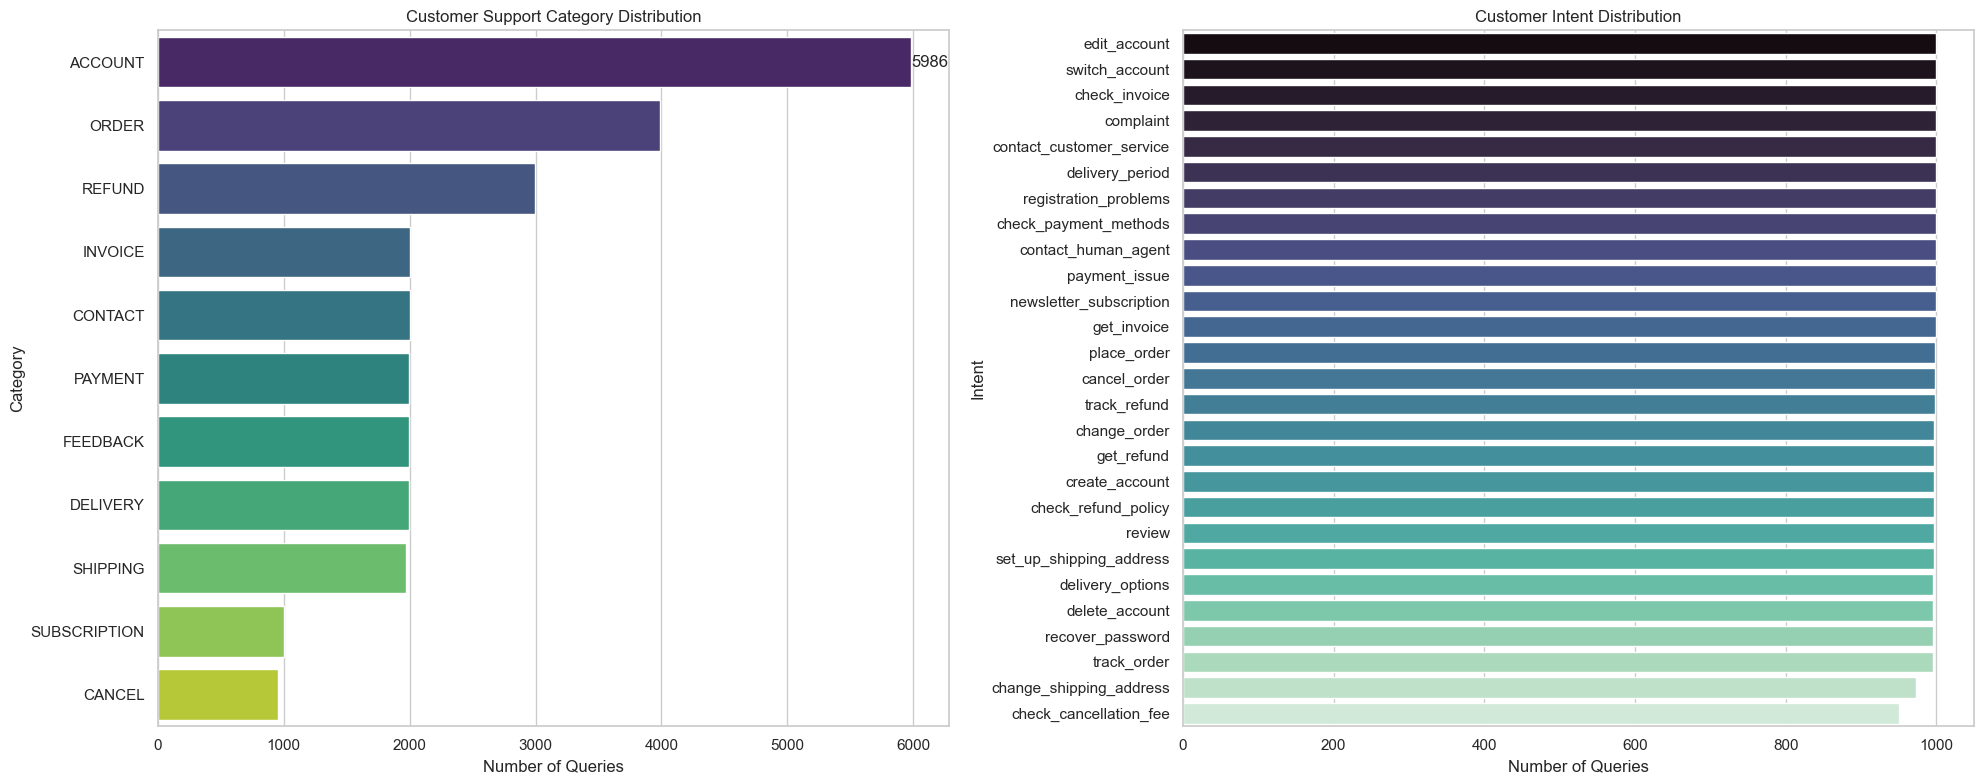

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Category distribution
category_counts = df["category"].value_counts()

sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    hue=category_counts.index,
    palette="viridis",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Customer Support Category Distribution")
axes[0].set_xlabel("Number of Queries")
axes[0].set_ylabel("Category")
axes[0].bar_label(axes[0].containers[0])

# Intent distribution
intent_counts = df["intent"].value_counts()

sns.barplot(
    x=intent_counts.values,
    y=intent_counts.index,
    hue=intent_counts.index,
    palette="mako",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Customer Intent Distribution")
axes[1].set_xlabel("Number of Queries")
axes[1].set_ylabel("Intent")

plt.tight_layout()
plt.show()

========== TEXT LENGTH STATISTICS ==========


,char_count,word_count
count,26872.00,26872.00
mean,46.89,8.69
std,10.90,2.61
min,6.00,1.00
25%,40.00,7.00
50%,48.00,9.00
75%,55.00,11.00
max,92.00,16.00


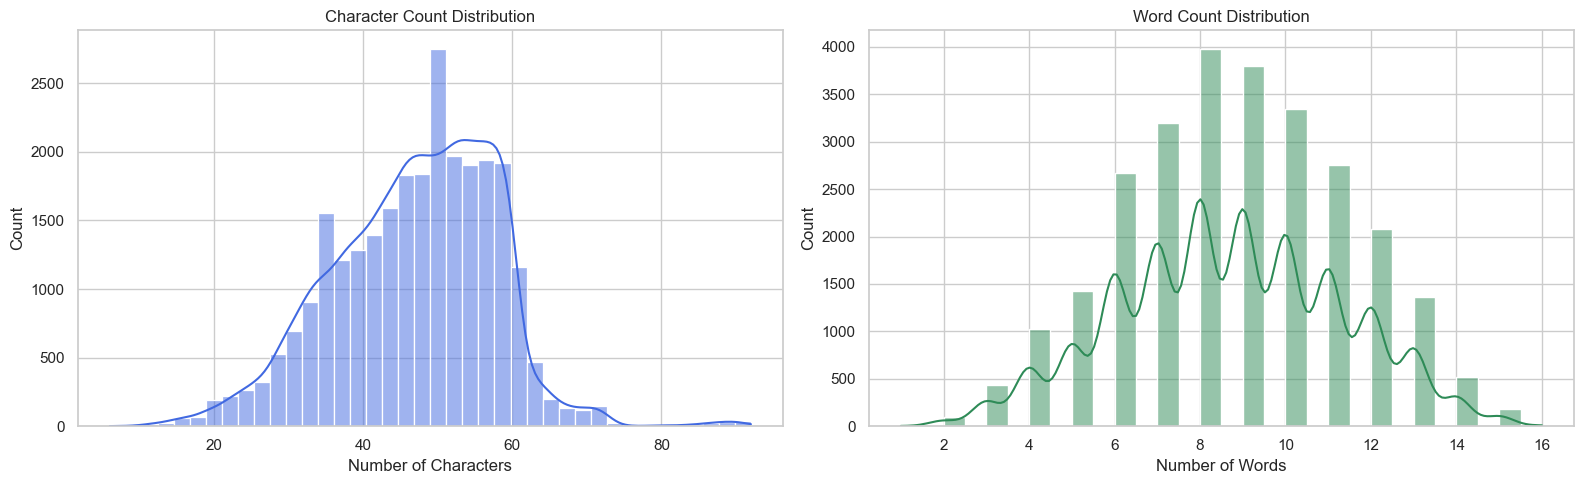


========== SHORTEST QUERY ==========
complaint

========== LONGEST QUERY ==========
I do not know what to do to create a {{Account Type}} account for my dad


In [4]:
# Calculate text statistics
df["char_count"] = df["instruction"].str.len()

df["word_count"] = df["instruction"].apply(
    lambda text: len(text.split())
)

df["sentence_count"] = df["instruction"].apply(
    lambda text: len(nltk.sent_tokenize(text))
) if "nltk" in globals() else 0

# Display text statistics
print("========== TEXT LENGTH STATISTICS ==========")

display(df[["char_count", "word_count"]].describe().round(2))

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.histplot(
    df["char_count"],
    bins=40,
    kde=True,
    color="royalblue",
    ax=axes[0]
)

axes[0].set_title("Character Count Distribution")
axes[0].set_xlabel("Number of Characters")

sns.histplot(
    df["word_count"],
    bins=30,
    kde=True,
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Word Count Distribution")
axes[1].set_xlabel("Number of Words")

plt.tight_layout()
plt.show()

# Display shortest and longest queries
print("\n========== SHORTEST QUERY ==========")
print(df.loc[df["word_count"].idxmin(), "instruction"])

print("\n========== LONGEST QUERY ==========")
print(df.loc[df["word_count"].idxmax(), "instruction"])

In [6]:
%pip install nltk wordcloud

  Using cached nltk-3.10.4-py3-none-any.whl.metadata (5.0 kB)
  Using cached wordcloud-1.9.6-cp311-cp311-win_amd64.whl.metadata (3.5 kB)
Using cached nltk-3.10.4-py3-none-any.whl (1.7 MB)
Using cached wordcloud-1.9.6-cp311-cp311-win_amd64.whl (306 kB)

   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   ---------------------------------------- 0/2 [nltk]
   -----------------------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\picka\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [8]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger_eng")
nltk.download("vader_lexicon")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\picka\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\picka\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\picka\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\picka\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\picka\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\picka\AppData\Roaming\nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\picka\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\aver

True

In [9]:
import nltk
from nltk.corpus import stopwords

print("NLTK Version:", nltk.__version__)
print("NLTK is working successfully!")

NLTK Version: 3.10.4
NLTK is working successfully!


========== VOCABULARY ANALYSIS ==========
Total word tokens: 234612
Unique words: 2841
Vocabulary richness: 0.0121


,Word,Frequency
0,help,6319
1,account,5400
2,order,4833
3,need,4059
4,want,3110
5,assistance,3005
6,number,2953
7,know,2691
8,see,2545
9,check,2070


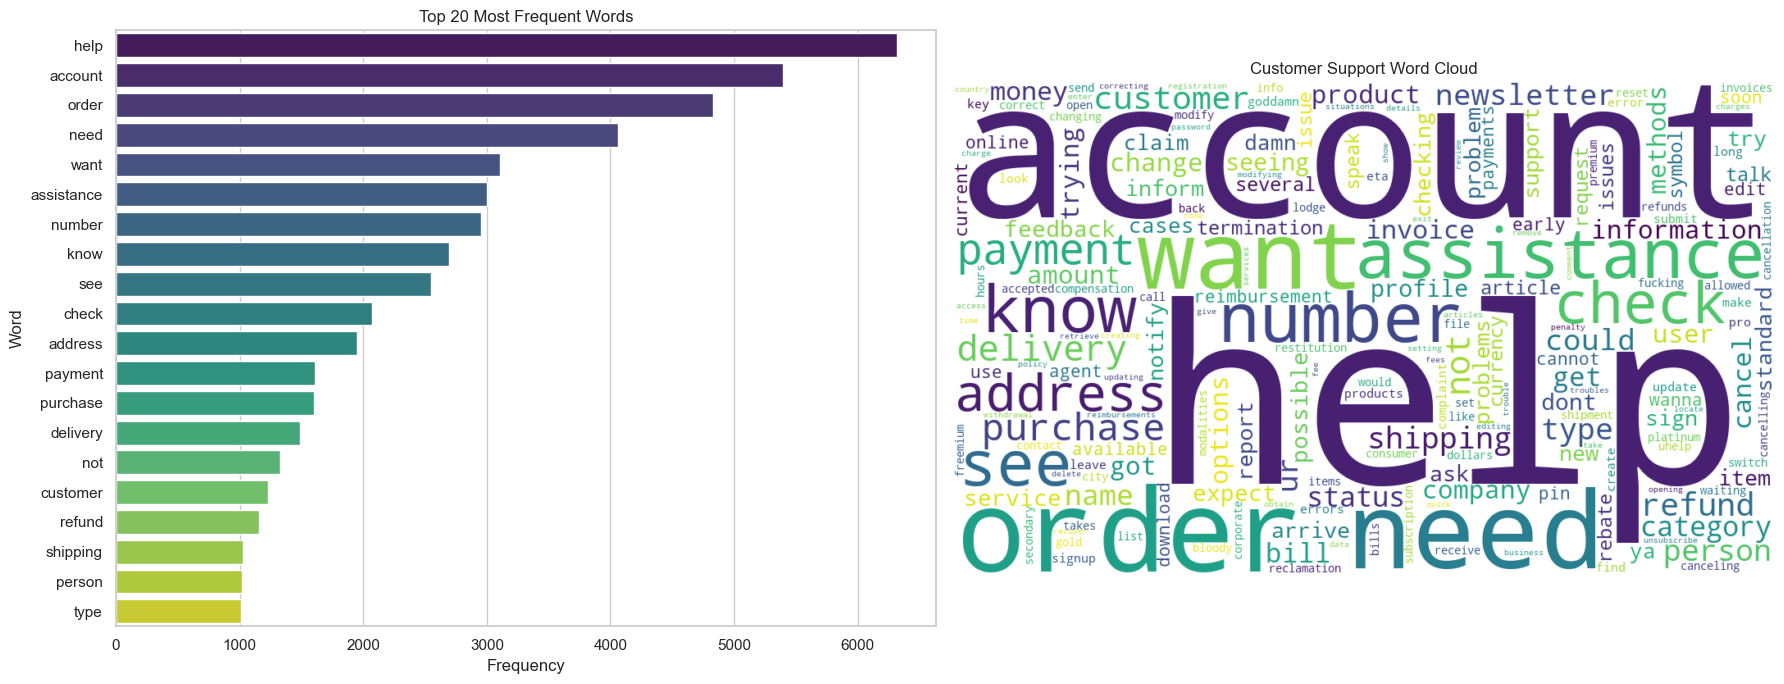

In [10]:
import re
import nltk

from collections import Counter
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Combine all customer queries
all_text = " ".join(df["instruction"].astype(str))

# Convert text to lowercase and extract words
tokens = re.findall(r"\b[a-z]+\b", all_text.lower())

# Vocabulary analysis
vocabulary = set(tokens)

print("========== VOCABULARY ANALYSIS ==========")
print("Total word tokens:", len(tokens))
print("Unique words:", len(vocabulary))
print("Vocabulary richness:", round(len(vocabulary) / len(tokens), 4))

# Remove stopwords while preserving negation
stop_words = set(stopwords.words("english"))
stop_words -= {"not", "no", "nor"}

filtered_tokens = [
    word for word in tokens
    if word not in stop_words
]

# Calculate word frequency
word_freq = Counter(filtered_tokens)

top_words = pd.DataFrame(
    word_freq.most_common(20),
    columns=["Word", "Frequency"]
)

display(top_words)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Top 20 frequently occurring words
sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word",
    hue="Word",
    palette="viridis",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Top 20 Most Frequent Words")

# Word cloud
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color="white",
    colormap="viridis",
    random_state=42
).generate_from_frequencies(word_freq)

axes[1].imshow(wordcloud, interpolation="bilinear")
axes[1].set_title("Customer Support Word Cloud")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [11]:
# Global visualization settings
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.2
)

plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "axes.labelweight": "medium",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.autolayout": True
})

print("Visualization settings configured successfully!")

Visualization settings configured successfully!


In [12]:
from sklearn.feature_extraction.text import CountVectorizer

def get_top_ngrams(texts, n=1, top_n=15):

    vectorizer = CountVectorizer(
        ngram_range=(n, n),
        lowercase=True
    )

    matrix = vectorizer.fit_transform(texts)

    frequencies = np.asarray(matrix.sum(axis=0)).ravel()

    result = pd.DataFrame({
        "N-gram": vectorizer.get_feature_names_out(),
        "Frequency": frequencies
    })

    return result.sort_values(
        "Frequency",
        ascending=False
    ).head(top_n).reset_index(drop=True)


# Generate N-grams
unigrams = get_top_ngrams(df["instruction"], 1)
bigrams = get_top_ngrams(df["instruction"], 2)
trigrams = get_top_ngrams(df["instruction"], 3)


# Display results
print("========== TOP 15 UNIGRAMS ==========")
display(unigrams)

print("\n========== TOP 15 BIGRAMS ==========")
display(bigrams)

print("\n========== TOP 15 TRIGRAMS ==========")
display(trigrams)

========== TOP 15 UNIGRAMS ==========


,N-gram,Frequency
0,to,16400
1,the,6413
2,help,6319
3,can,5495
4,account,5400
5,do,5349
6,order,4833
7,my,4774
8,how,4207
9,need,4059



========== TOP 15 BIGRAMS ==========


,N-gram,Frequency
0,order number,2907
1,help me,2791
2,to do,1992
3,do to,1786
4,to see,1655
5,have to,1492
6,help to,1473
7,order order,1454
8,need to,1410
9,need help,1355



========== TOP 15 TRIGRAMS ==========


,N-gram,Frequency
0,to do to,1774
1,order order number,1454
2,purchase order number,1351
3,do not know,1167
4,you help me,1097
5,account type account,869
6,from person name,867
7,can you help,805
8,account category account,699
9,help me to,667


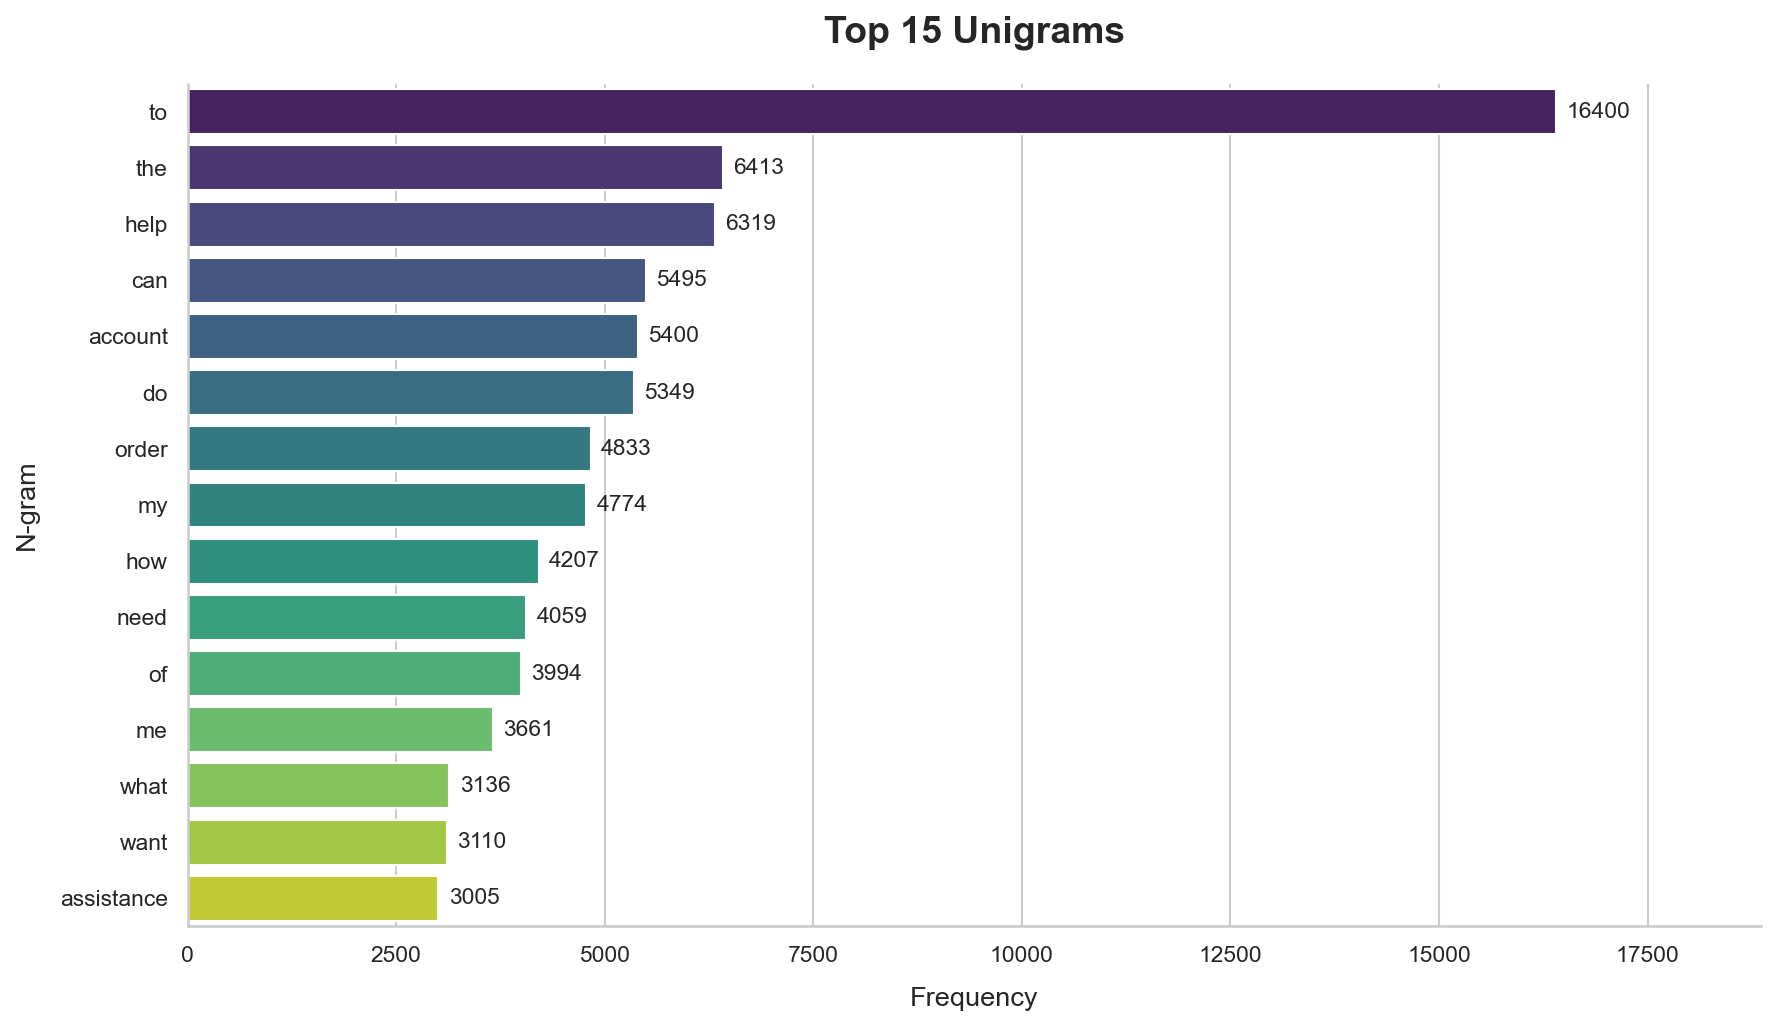

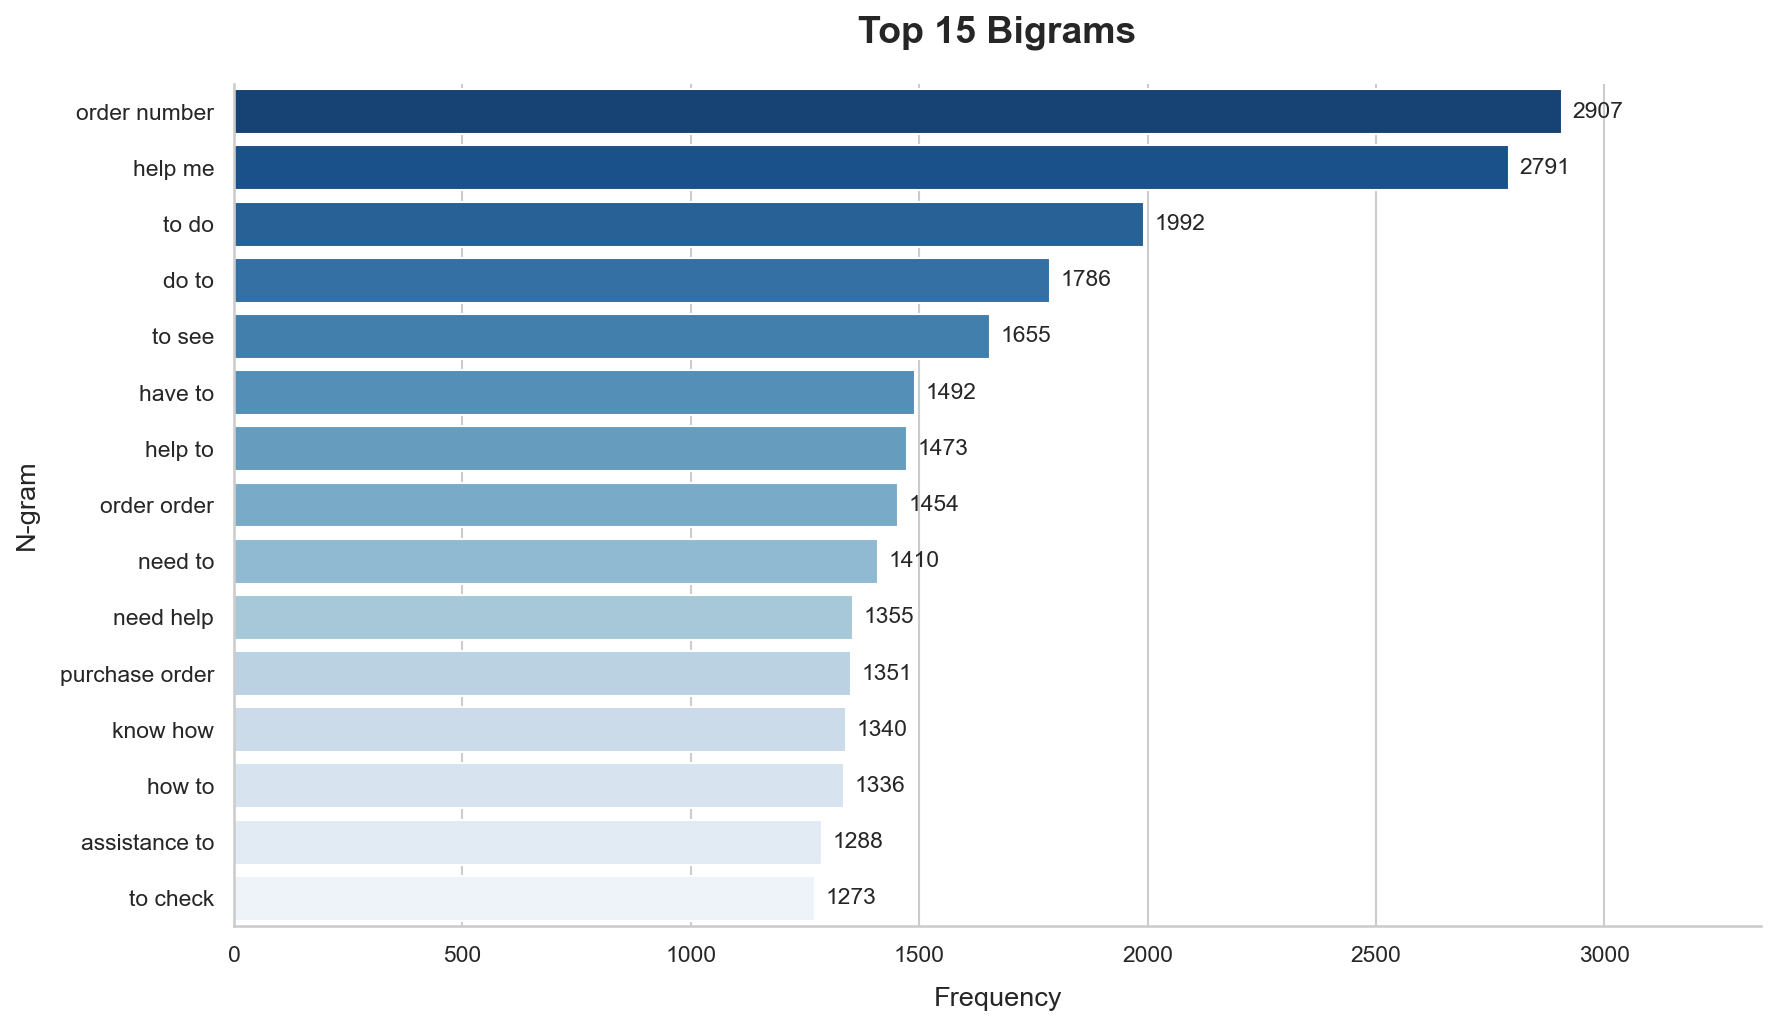

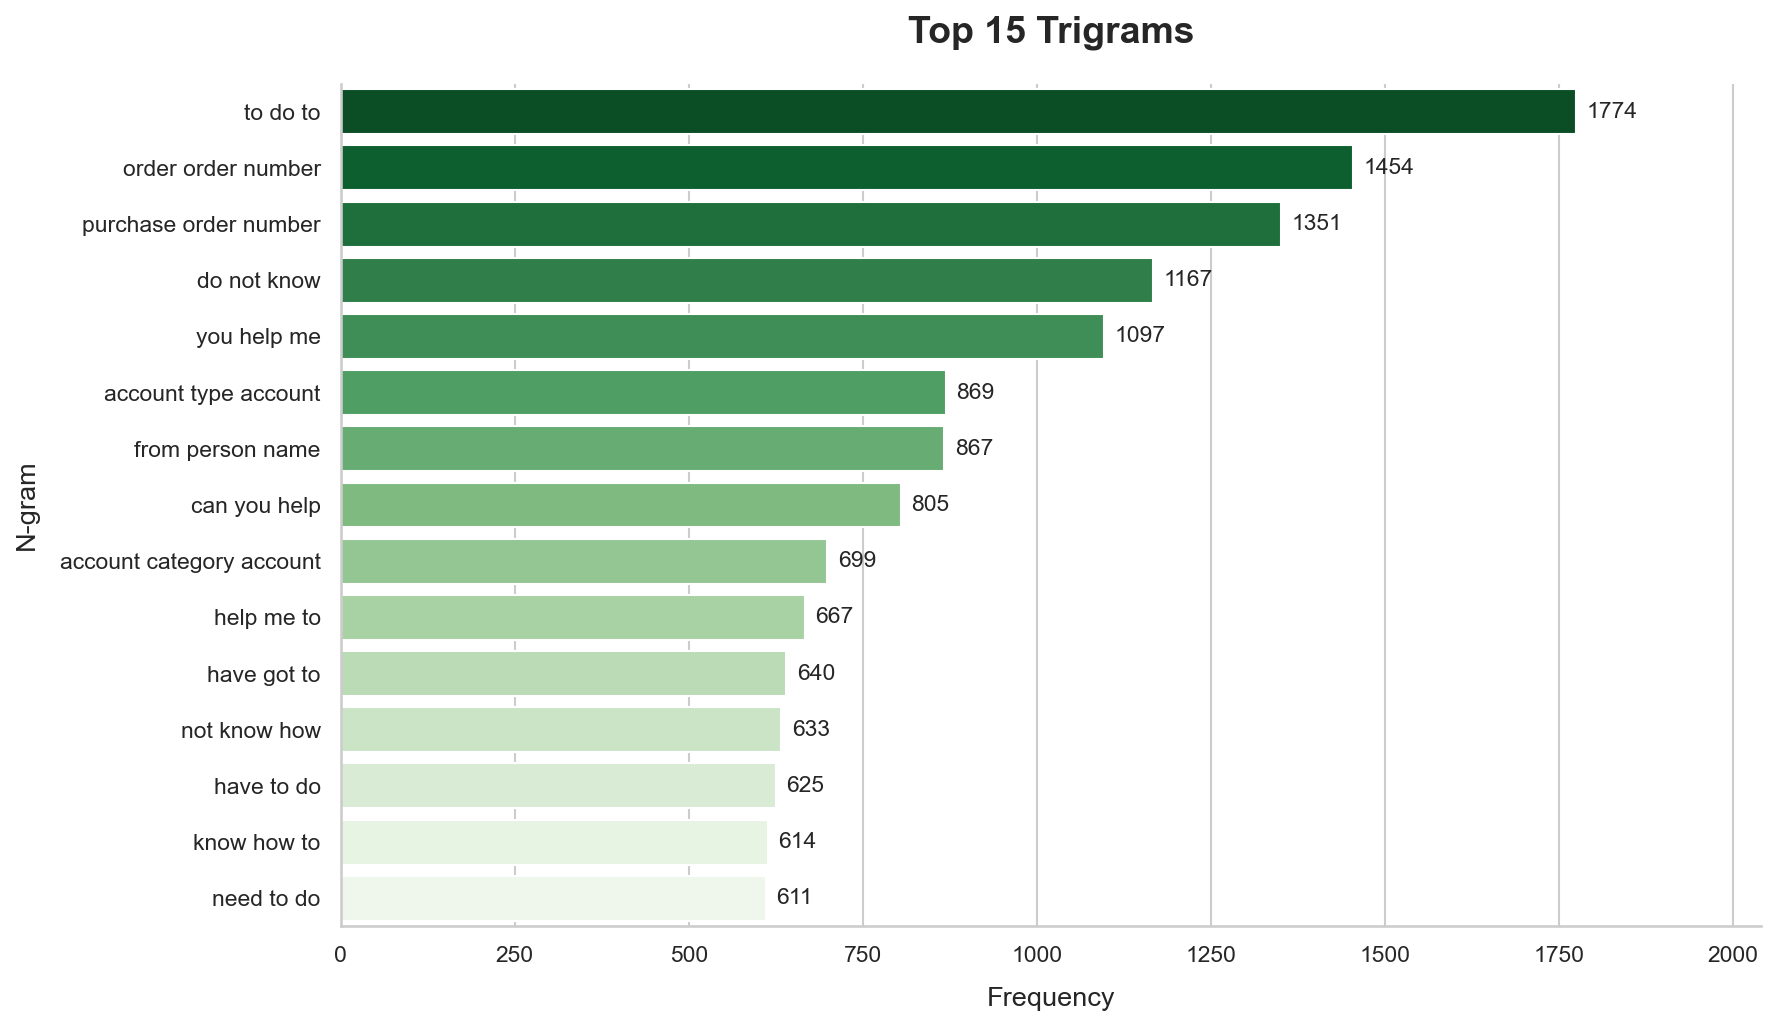

In [13]:
ngram_results = [
    (unigrams, "Top 15 Unigrams", "viridis"),
    (bigrams, "Top 15 Bigrams", "Blues_r"),
    (trigrams, "Top 15 Trigrams", "Greens_r")
]

for data, title, palette in ngram_results:

    fig, ax = plt.subplots(figsize=(12, 7))

    sns.barplot(
        data=data,
        x="Frequency",
        y="N-gram",
        hue="N-gram",
        palette=palette,
        legend=False,
        ax=ax
    )

    ax.set_title(title, pad=20)
    ax.set_xlabel("Frequency", labelpad=10)
    ax.set_ylabel("N-gram", labelpad=10)

    for container in ax.containers:
        ax.bar_label(
            container,
            padding=5,
            fontsize=11,
            fmt="%d"
        )

    ax.set_xlim(0, data["Frequency"].max() * 1.15)

    sns.despine()
    plt.tight_layout()
    plt.show()

In [14]:
import re
import unicodedata
import html

# Text cleaning function
def clean_text(text):

    # Convert to string
    text = str(text)

    # Unicode normalization
    text = unicodedata.normalize("NFKC", text)

    # Decode HTML entities
    text = html.unescape(text)

    # Convert to lowercase
    text = text.lower()

    # Normalize apostrophes
    text = text.replace("’", "'")

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Expand common contractions
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"'m\b", " am", text)
    text = re.sub(r"'re\b", " are", text)
    text = re.sub(r"'ve\b", " have", text)
    text = re.sub(r"'ll\b", " will", text)

    # Remove special characters and punctuation
    # Preserve letters and numbers
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
df["cleaned_text"] = df["instruction"].apply(clean_text)

# Display results
print("========== TEXT CLEANING RESULTS ==========")

display(
    df[["instruction", "cleaned_text"]]
    .sample(10, random_state=42)
)

# Check empty records after cleaning
print(
    "Empty queries after cleaning:",
    df["cleaned_text"].eq("").sum()
)

========== TEXT CLEANING RESULTS ==========


,instruction,cleaned_text
9329,I can't talk with a human agent,i can not talk with a human agent
4160,I have got to locate hte bills from {{Person Name}},i have got to locate hte bills from person name
18500,"I cannot pay, help me to inform of a problem with payments",i cannot pay help me to inform of a problem with payments
8840,I want help speaking to customer service,i want help speaking to customer service
5098,I try to see th accepted payment options,i try to see th accepted payment options
17250,where to sign up to the company nmewsletter,where to sign up to the company nmewsletter
3589,I'd like to see the withdrwaal fee how can i do it,i d like to see the withdrwaal fee how can i do it
9043,I want to speak with someone,i want to speak with someone
15800,can you help me getting bill #85632?,can you help me getting bill 85632
4384,I don't know how to take a quick look at invoice #12588,i do not know how to take a quick look at invoice 12588


Empty queries after cleaning: 0


In [15]:
test_sentences = [
    "I CAN'T access my account!!!",
    "I don't want to cancel my order.",
    "   Please help me with my order.   ",
    "My order number is 12345.",
    "Visit https://example.com for details.",
    "<p>I need a refund.</p>",
    "I'm not happy with the service."
]

test_results = pd.DataFrame({
    "Original Text": test_sentences,
    "Cleaned Text": [
        clean_text(text) for text in test_sentences
    ]
})

display(test_results)

,Original Text,Cleaned Text
0,I CAN'T access my account!!!,i can not access my account
1,I don't want to cancel my order.,i do not want to cancel my order
2,Please help me with my order.,please help me with my order
3,My order number is 12345.,my order number is 12345
4,Visit https://example.com for details.,visit for details
5,<p>I need a refund.</p>,i need a refund
6,I'm not happy with the service.,i am not happy with the service


In [16]:
from nltk.tokenize import word_tokenize, sent_tokenize

# Word tokenization
df["tokens"] = df["cleaned_text"].apply(word_tokenize)

# Sentence tokenization using original text
df["sentences"] = df["instruction"].apply(sent_tokenize)

# Update sentence count from earlier EDA
df["sentence_count"] = df["sentences"].apply(len)

# Token count
df["token_count"] = df["tokens"].apply(len)

# Display results
print("========== TOKENIZATION RESULTS ==========")

display(
    df[["cleaned_text", "tokens", "token_count"]]
    .sample(10, random_state=42)
)

print("\n========== TOKEN STATISTICS ==========")
print("Total tokens:", df["token_count"].sum())
print("Average tokens per query:", round(df["token_count"].mean(), 2))
print("Maximum tokens:", df["token_count"].max())
print("Minimum tokens:", df["token_count"].min())

========== TOKENIZATION RESULTS ==========


,cleaned_text,tokens,token_count
9329,i can not talk with a human agent,"[i, can, not, talk, with, a, human, agent]",8
4160,i have got to locate hte bills from person name,"[i, have, got, to, locate, hte, bills, from, person, name]",10
18500,i cannot pay help me to inform of a problem with payments,"[i, can, not, pay, help, me, to, inform, of, a, problem, with, payments]",13
8840,i want help speaking to customer service,"[i, want, help, speaking, to, customer, service]",7
5098,i try to see th accepted payment options,"[i, try, to, see, th, accepted, payment, options]",8
17250,where to sign up to the company nmewsletter,"[where, to, sign, up, to, the, company, nmewsletter]",8
3589,i d like to see the withdrwaal fee how can i do it,"[i, d, like, to, see, the, withdrwaal, fee, how, can, i, do, it]",13
9043,i want to speak with someone,"[i, want, to, speak, with, someone]",6
15800,can you help me getting bill 85632,"[can, you, help, me, getting, bill, 85632]",7
4384,i do not know how to take a quick look at invoice 12588,"[i, do, not, know, how, to, take, a, quick, look, at, invoice, 12588]",13



========== TOKEN STATISTICS ==========
Total tokens: 236448
Average tokens per query: 8.8
Maximum tokens: 17
Minimum tokens: 1


In [17]:
from nltk.corpus import stopwords

# Load English stopwords
stop_words = set(stopwords.words("english"))

# Preserve important negation words
negation_words = {
    "not", "no", "nor", "never",
    "cannot", "without", "neither"
}

stop_words = stop_words - negation_words

# Stopword removal function
def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in stop_words
    ]

# Apply stopword removal
df["filtered_tokens"] = df["tokens"].apply(remove_stopwords)

# Calculate token counts
df["filtered_token_count"] = df["filtered_tokens"].apply(len)

# Display results
print("========== STOPWORD REMOVAL ==========")

display(
    df[["tokens", "filtered_tokens"]]
    .sample(10, random_state=42)
)

# Compare token counts
before = df["token_count"].sum()
after = df["filtered_token_count"].sum()

print("\n========== TOKEN COMPARISON ==========")
print("Tokens before removal:", before)
print("Tokens after removal:", after)
print("Total removed tokens:", before - after)
print("Reduction percentage:", round((before - after) / before * 100, 2), "%")

========== STOPWORD REMOVAL ==========


,tokens,filtered_tokens
9329,"[i, can, not, talk, with, a, human, agent]","[not, talk, human, agent]"
4160,"[i, have, got, to, locate, hte, bills, from, person, name]","[got, locate, hte, bills, person, name]"
18500,"[i, can, not, pay, help, me, to, inform, of, a, problem, with, payments]","[not, pay, help, inform, problem, payments]"
8840,"[i, want, help, speaking, to, customer, service]","[want, help, speaking, customer, service]"
5098,"[i, try, to, see, th, accepted, payment, options]","[try, see, th, accepted, payment, options]"
17250,"[where, to, sign, up, to, the, company, nmewsletter]","[sign, company, nmewsletter]"
3589,"[i, d, like, to, see, the, withdrwaal, fee, how, can, i, do, it]","[like, see, withdrwaal, fee]"
9043,"[i, want, to, speak, with, someone]","[want, speak, someone]"
15800,"[can, you, help, me, getting, bill, 85632]","[help, getting, bill, 85632]"
4384,"[i, do, not, know, how, to, take, a, quick, look, at, invoice, 12588]","[not, know, take, quick, look, invoice, 12588]"



========== TOKEN COMPARISON ==========
Tokens before removal: 236448
Tokens after removal: 129261
Total removed tokens: 107187
Reduction percentage: 45.33 %


========== STOPWORD REMOVAL SUMMARY ==========
Tokens before removal: 236,448
Tokens after removal: 129,261
Total removed tokens: 107,187
Reduction percentage: 45.33%


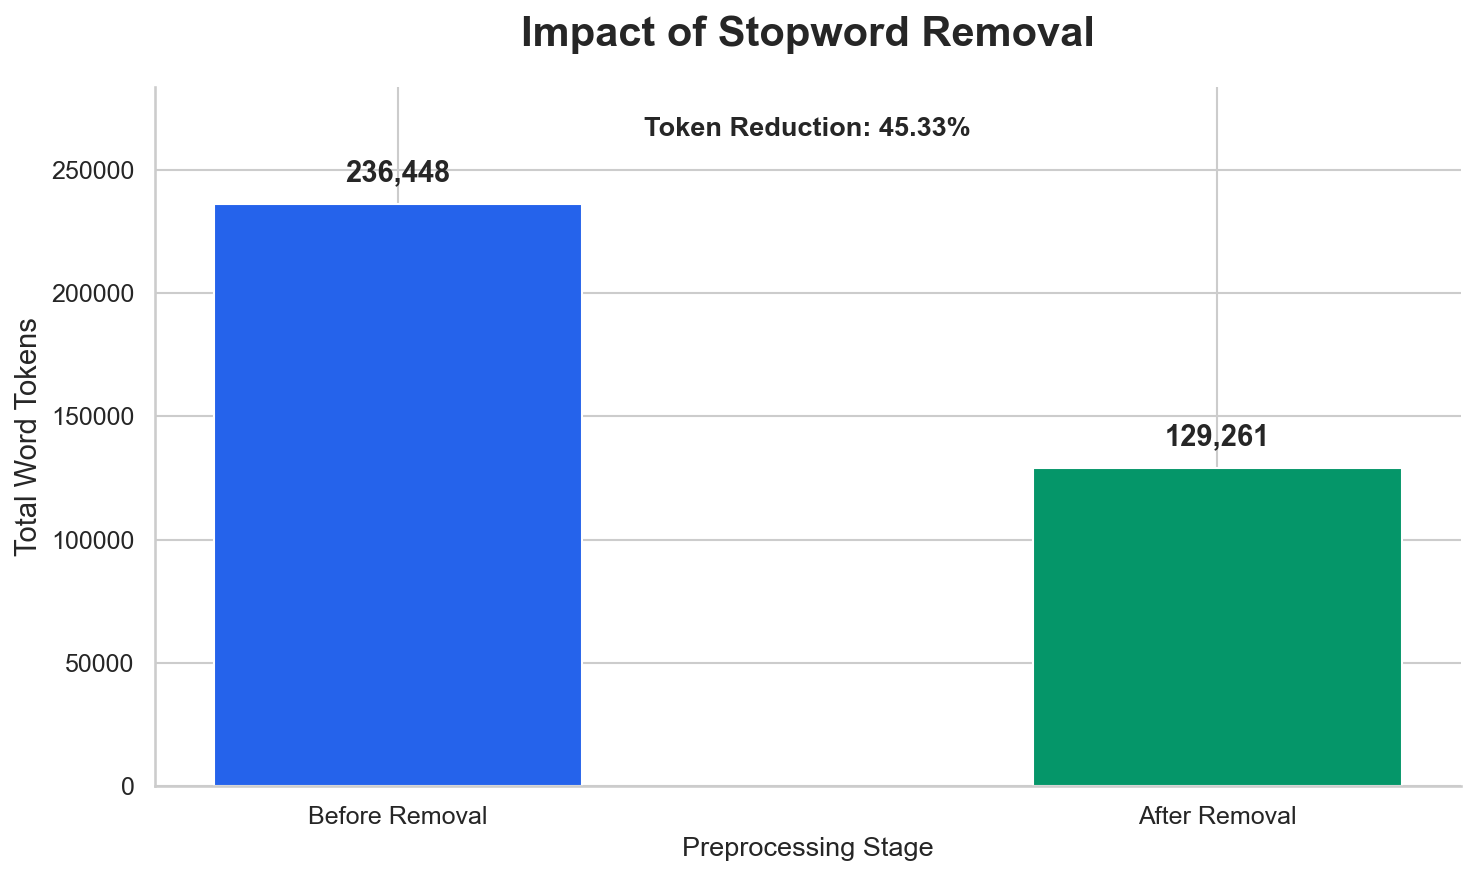

In [18]:
# Calculate token statistics
before = df["token_count"].sum()
after = df["filtered_token_count"].sum()

removed = before - after
reduction = (removed / before) * 100

# Display statistics
print("========== STOPWORD REMOVAL SUMMARY ==========")
print(f"Tokens before removal: {before:,}")
print(f"Tokens after removal: {after:,}")
print(f"Total removed tokens: {removed:,}")
print(f"Reduction percentage: {reduction:.2f}%")

# Visualization
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

labels = ["Before Removal", "After Removal"]
values = [before, after]

bars = ax.bar(
    labels,
    values,
    color=["#2563EB", "#059669"],
    width=0.45
)

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in values],
    fontsize=14,
    fontweight="bold",
    padding=8
)

ax.set_title(
    "Impact of Stopword Removal",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Total Word Tokens", fontsize=14)
ax.set_xlabel("Preprocessing Stage", fontsize=13)

ax.tick_params(axis="both", labelsize=12)
ax.set_ylim(0, max(values) * 1.2)

ax.text(
    0.5, 0.93,
    f"Token Reduction: {reduction:.2f}%",
    transform=ax.transAxes,
    ha="center",
    fontsize=13,
    fontweight="bold"
)

sns.despine()
plt.tight_layout()
plt.show()

In [19]:
from nltk.stem import PorterStemmer

# Initialize Porter Stemmer
stemmer = PorterStemmer()

# Stemming function
def apply_stemming(tokens):
    return [stemmer.stem(word) for word in tokens]

# Apply stemming
df["stemmed_tokens"] = df["filtered_tokens"].apply(
    apply_stemming
)

# Display results
print("========== STEMMING RESULTS ==========")

display(
    df[["filtered_tokens", "stemmed_tokens"]]
    .sample(10, random_state=42)
)

# Vocabulary before stemming
vocab_before_stemming = set(
    word
    for tokens in df["filtered_tokens"]
    for word in tokens
)

# Vocabulary after stemming
vocab_after_stemming = set(
    word
    for tokens in df["stemmed_tokens"]
    for word in tokens
)

# Vocabulary statistics
print("\n========== VOCABULARY COMPARISON ==========")

print("Vocabulary before stemming:", len(vocab_before_stemming))
print("Vocabulary after stemming:", len(vocab_after_stemming))

reduction_stemming = (
    (len(vocab_before_stemming) - len(vocab_after_stemming))
    / len(vocab_before_stemming)
) * 100

print(f"Vocabulary reduction: {reduction_stemming:.2f}%")

========== STEMMING RESULTS ==========


,filtered_tokens,stemmed_tokens
9329,"[not, talk, human, agent]","[not, talk, human, agent]"
4160,"[got, locate, hte, bills, person, name]","[got, locat, hte, bill, person, name]"
18500,"[not, pay, help, inform, problem, payments]","[not, pay, help, inform, problem, payment]"
8840,"[want, help, speaking, customer, service]","[want, help, speak, custom, servic]"
5098,"[try, see, th, accepted, payment, options]","[tri, see, th, accept, payment, option]"
17250,"[sign, company, nmewsletter]","[sign, compani, nmewslett]"
3589,"[like, see, withdrwaal, fee]","[like, see, withdrwaal, fee]"
9043,"[want, speak, someone]","[want, speak, someon]"
15800,"[help, getting, bill, 85632]","[help, get, bill, 85632]"
4384,"[not, know, take, quick, look, invoice, 12588]","[not, know, take, quick, look, invoic, 12588]"



========== VOCABULARY COMPARISON ==========
Vocabulary before stemming: 2795
Vocabulary after stemming: 2545
Vocabulary reduction: 8.94%


In [20]:
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

# Convert NLTK POS tags to WordNet POS tags
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return wordnet.ADJ

    elif tag.startswith("V"):
        return wordnet.VERB

    elif tag.startswith("N"):
        return wordnet.NOUN

    elif tag.startswith("R"):
        return wordnet.ADV

    return wordnet.NOUN


# Lemmatization with POS tagging
def apply_lemmatization(tokens):

    tagged_tokens = pos_tag(tokens)

    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        for word, tag in tagged_tokens
    ]


# Apply lemmatization
df["lemmatized_tokens"] = df["tokens"].apply(
    apply_lemmatization
)

# Remove stopwords after lemmatization
df["lemmatized_tokens"] = df["lemmatized_tokens"].apply(
    remove_stopwords
)

# Display results
print("========== LEMMATIZATION RESULTS ==========")

display(
    df[
        [
            "filtered_tokens",
            "stemmed_tokens",
            "lemmatized_tokens"
        ]
    ].sample(10, random_state=42)
)

# Calculate vocabulary after lemmatization
vocab_after_lemmatization = set(
    word
    for tokens in df["lemmatized_tokens"]
    for word in tokens
)

print("\n========== VOCABULARY COMPARISON ==========")

print("Original vocabulary:", len(vocab_before_stemming))
print("After stemming:", len(vocab_after_stemming))
print("After lemmatization:", len(vocab_after_lemmatization))

reduction_lemmatization = (
    (len(vocab_before_stemming) - len(vocab_after_lemmatization))
    / len(vocab_before_stemming)
) * 100

print(f"Lemmatization vocabulary reduction: {reduction_lemmatization:.2f}%")

========== LEMMATIZATION RESULTS ==========


,filtered_tokens,stemmed_tokens,lemmatized_tokens
9329,"[not, talk, human, agent]","[not, talk, human, agent]","[not, talk, human, agent]"
4160,"[got, locate, hte, bills, person, name]","[got, locat, hte, bill, person, name]","[get, locate, hte, bill, person, name]"
18500,"[not, pay, help, inform, problem, payments]","[not, pay, help, inform, problem, payment]","[not, pay, help, inform, problem, payment]"
8840,"[want, help, speaking, customer, service]","[want, help, speak, custom, servic]","[want, help, speaking, customer, service]"
5098,"[try, see, th, accepted, payment, options]","[tri, see, th, accept, payment, option]","[try, see, th, accepted, payment, option]"
17250,"[sign, company, nmewsletter]","[sign, compani, nmewslett]","[sign, company, nmewsletter]"
3589,"[like, see, withdrwaal, fee]","[like, see, withdrwaal, fee]","[like, see, withdrwaal, fee]"
9043,"[want, speak, someone]","[want, speak, someon]","[want, speak, someone]"
15800,"[help, getting, bill, 85632]","[help, get, bill, 85632]","[help, get, bill, 85632]"
4384,"[not, know, take, quick, look, invoice, 12588]","[not, know, take, quick, look, invoic, 12588]","[not, know, take, quick, look, invoice, 12588]"



========== VOCABULARY COMPARISON ==========
Original vocabulary: 2795
After stemming: 2545
After lemmatization: 2681
Lemmatization vocabulary reduction: 4.08%


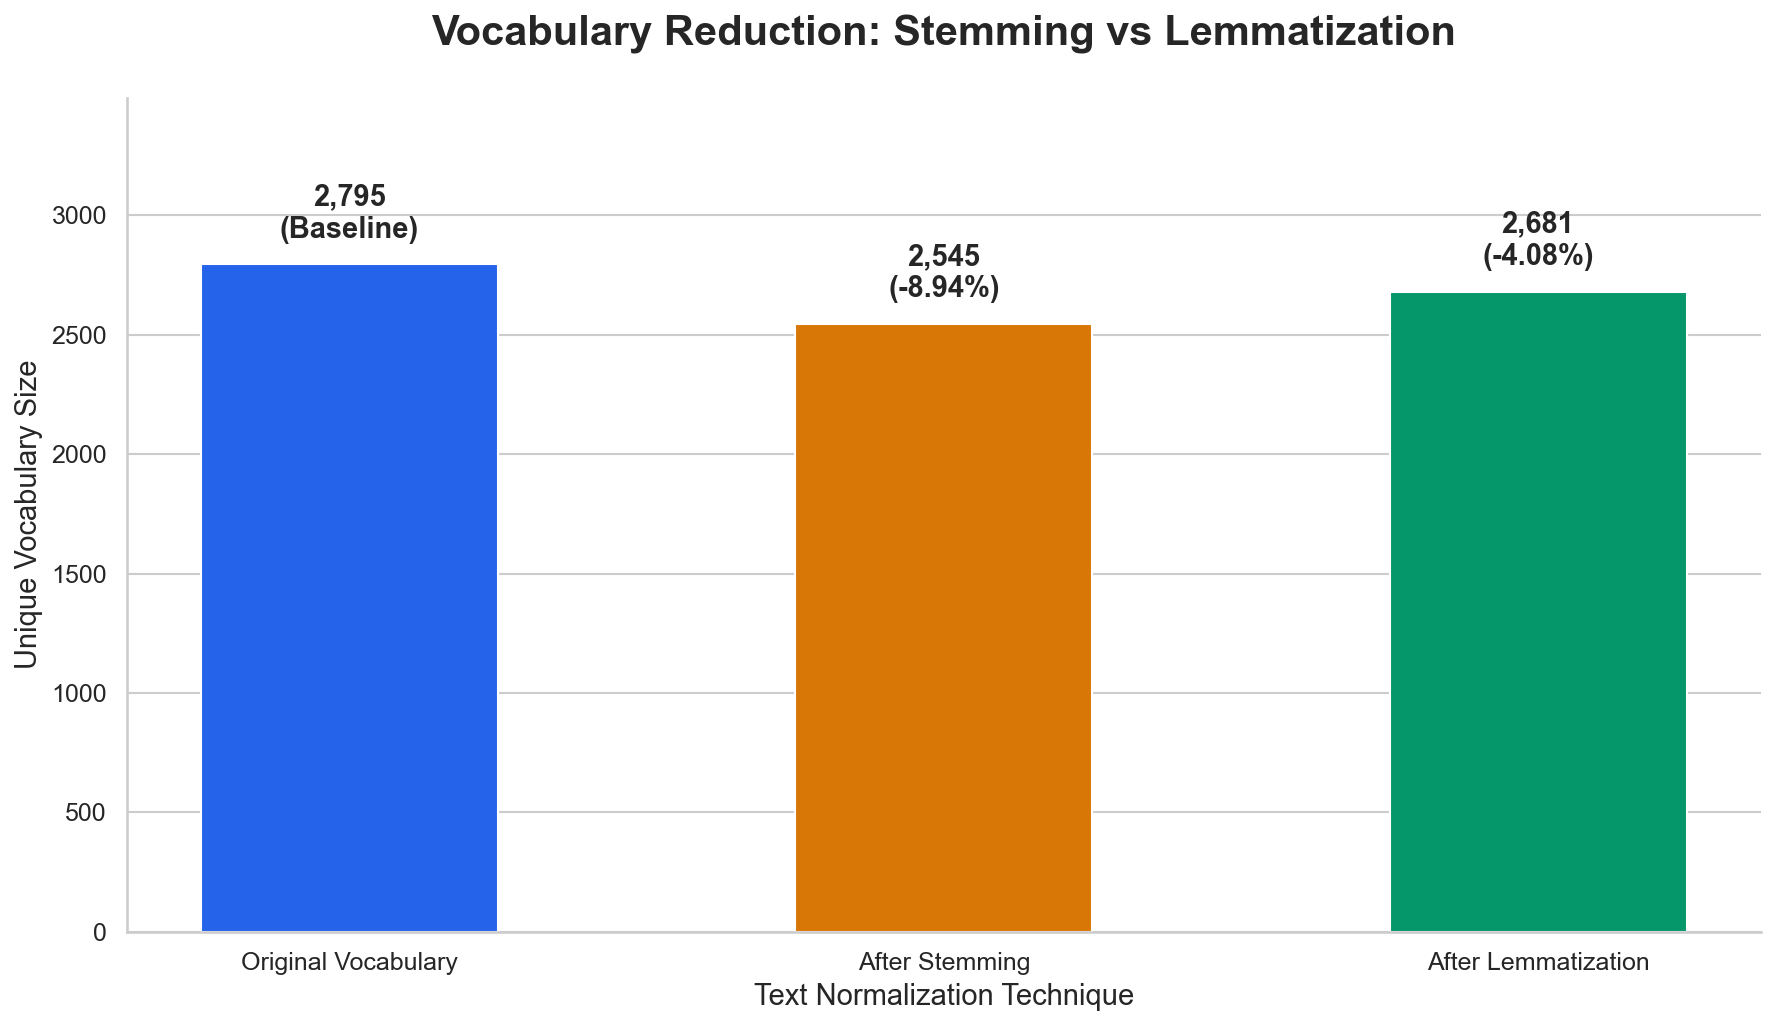

In [21]:
# Vocabulary comparison
labels = [
    "Original Vocabulary",
    "After Stemming",
    "After Lemmatization"
]

values = [
    len(vocab_before_stemming),
    len(vocab_after_stemming),
    len(vocab_after_lemmatization)
]

# Create chart
fig, ax = plt.subplots(figsize=(12, 7), dpi=150)

bars = ax.bar(
    labels,
    values,
    color=["#2563EB", "#D97706", "#059669"],
    width=0.5
)

# Display values and reduction percentages
bar_labels = [
    f"{values[0]:,}\n(Baseline)",
    f"{values[1]:,}\n(-{reduction_stemming:.2f}%)",
    f"{values[2]:,}\n(-{reduction_lemmatization:.2f}%)"
]

ax.bar_label(
    bars,
    labels=bar_labels,
    padding=10,
    fontsize=14,
    fontweight="bold"
)

# Chart formatting
ax.set_title(
    "Vocabulary Reduction: Stemming vs Lemmatization",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_ylabel("Unique Vocabulary Size", fontsize=14)
ax.set_xlabel("Text Normalization Technique", fontsize=14)

ax.tick_params(axis="both", labelsize=12)
ax.set_ylim(0, max(values) * 1.25)

ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

In [22]:
# Define negation words
negation_terms = {
    "not", "no", "never", "cannot",
    "neither", "nor", "without"
}

# Rule-based negation handling
def handle_negation(tokens):

    result = []
    remaining = 0

    for word in tokens:

        if word in negation_terms:
            result.append(word)
            remaining = 2

        elif word in {"but", "however", "yet"}:
            remaining = 0
            result.append(word)

        elif remaining > 0:
            result.append("NOT_" + word)
            remaining -= 1

        else:
            result.append(word)

    return result


# Apply negation handling
df["negation_tokens"] = df["lemmatized_tokens"].apply(
    handle_negation
)

# Identify queries containing negation
negation_mask = df["lemmatized_tokens"].apply(
    lambda tokens: any(
        word in negation_terms for word in tokens
    )
)

negation_count = negation_mask.sum()

# Display results
print("========== NEGATION HANDLING ==========")

display(
    df.loc[
        negation_mask,
        ["instruction", "lemmatized_tokens", "negation_tokens"]
    ].head(10)
)

print("\n========== NEGATION STATISTICS ==========")
print("Total queries:", len(df))
print("Queries containing negation:", negation_count)

print(
    f"Negation percentage: "
    f"{negation_count / len(df) * 100:.2f}%"
)

========== NEGATION HANDLING ==========


,instruction,lemmatized_tokens,negation_tokens
4,"I cannot afford this order, cancel purchase {{Order Number}}","[not, afford, order, cancel, purchase, order, number]","[not, NOT_afford, NOT_order, cancel, purchase, order, number]"
6,"I can no longer afford order {{Order Number}}, cancel it","[no, longer, afford, order, order, number, cancel]","[no, NOT_longer, NOT_afford, order, order, number, cancel]"
33,i do not know how i can cancel purchase {{Order Number}},"[not, know, cancel, purchase, order, number]","[not, NOT_know, NOT_cancel, purchase, order, number]"
36,I can no longer afford purchase {{Order Number}},"[no, longer, afford, purchase, order, number]","[no, NOT_longer, NOT_afford, purchase, order, number]"
39,i do not want these article i try to cancel order {{Order Number}},"[not, want, article, try, cancel, order, order, number]","[not, NOT_want, NOT_article, try, cancel, order, order, number]"
54,I can't afford purchase {{Order Number}},"[not, afford, purchase, order, number]","[not, NOT_afford, NOT_purchase, order, number]"
58,"I can't afford order {{Order Number}}, help me cancelling it","[not, afford, order, order, number, help, cancel]","[not, NOT_afford, NOT_order, order, number, help, cancel]"
59,I do not know how I can cancel purchase {{Order Number}},"[not, know, cancel, purchase, order, number]","[not, NOT_know, NOT_cancel, purchase, order, number]"
62,"I cannot pay for the last purchase I have made, cancel it","[not, pay, last, purchase, make, cancel]","[not, NOT_pay, NOT_last, purchase, make, cancel]"
73,"I can't pay for this item, can I cancel order {{Order Number}}?","[not, pay, item, cancel, order, order, number]","[not, NOT_pay, NOT_item, cancel, order, order, number]"



========== NEGATION STATISTICS ==========
Total queries: 26872
Queries containing negation: 2927
Negation percentage: 10.89%


In [23]:
import nltk
from nltk import pos_tag
from nltk.tokenize import word_tokenize
from collections import Counter

# POS tagging function
def apply_pos_tagging(text):
    tokens = word_tokenize(text)
    return pos_tag(tokens)

# Apply POS tagging to original customer queries
df["pos_tags"] = df["instruction"].apply(
    apply_pos_tagging
)

# Display sample results
print("========== POS TAGGING RESULTS ==========")

display(
    df[["instruction", "pos_tags"]]
    .sample(10, random_state=42)
)

# Calculate POS tag frequencies
pos_frequency = Counter(
    tag
    for tagged_sentence in df["pos_tags"]
    for word, tag in tagged_sentence
)

# Create frequency dataframe
pos_df = pd.DataFrame(
    pos_frequency.most_common(15),
    columns=["POS Tag", "Frequency"]
)

print("\n========== TOP 15 POS TAGS ==========")

display(pos_df)

print("\nTotal unique POS tags:", len(pos_frequency))
print("Total tagged tokens:", sum(pos_frequency.values()))

========== POS TAGGING RESULTS ==========


,instruction,pos_tags
9329,I can't talk with a human agent,"[(I, PRP), (ca, MD), (n't, RB), (talk, VB), (with, IN), (a, DT), (human, JJ), (agent, NN)]"
4160,I have got to locate hte bills from {{Person Name}},"[(I, PRP), (have, VBP), (got, VBN), (to, TO), (locate, VB), (hte, JJ), (bills, NNS), (from, IN), ({, (), ({, (), (Person, NNP), (Name, NNP), (}, )..."
18500,"I cannot pay, help me to inform of a problem with payments","[(I, PRP), (can, MD), (not, RB), (pay, VB), (,, ,), (help, VB), (me, PRP), (to, TO), (inform, VB), (of, IN), (a, DT), (problem, NN), (with, IN), (..."
8840,I want help speaking to customer service,"[(I, PRP), (want, VBP), (help, NN), (speaking, NN), (to, TO), (customer, NN), (service, NN)]"
5098,I try to see th accepted payment options,"[(I, PRP), (try, VBP), (to, TO), (see, VB), (th, RB), (accepted, JJ), (payment, NN), (options, NNS)]"
17250,where to sign up to the company nmewsletter,"[(where, WRB), (to, TO), (sign, VB), (up, RP), (to, TO), (the, DT), (company, NN), (nmewsletter, NN)]"
3589,I'd like to see the withdrwaal fee how can i do it,"[(I, PRP), ('d, MD), (like, VB), (to, TO), (see, VB), (the, DT), (withdrwaal, JJ), (fee, NN), (how, WRB), (can, MD), (i, VB), (do, VBP), (it, PRP)]"
9043,I want to speak with someone,"[(I, PRP), (want, VBP), (to, TO), (speak, VB), (with, IN), (someone, NN)]"
15800,can you help me getting bill #85632?,"[(can, MD), (you, PRP), (help, VB), (me, PRP), (getting, VBG), (bill, NN), (#, #), (85632, CD), (?, .)]"
4384,I don't know how to take a quick look at invoice #12588,"[(I, PRP), (do, VBP), (n't, RB), (know, VB), (how, WRB), (to, TO), (take, VB), (a, DT), (quick, JJ), (look, NN), (at, IN), (invoice, JJ), (#, #), ..."



========== TOP 15 POS TAGS ==========


,POS Tag,Frequency
0,NN,49786
1,VB,34465
2,PRP,20381
3,TO,16759
4,DT,15245
5,VBP,15059
6,IN,14104
7,(,14084
8,),14084
9,NNP,11686



Total unique POS tags: 36
Total tagged tokens: 272214


========== POS TAG DISTRIBUTION ==========


,POS Tag,Description,Frequency
0,NN,Singular Noun,49786
1,VB,Base Verb,34465
2,PRP,Personal Pronoun,20381
3,TO,To,16759
4,DT,Determiner,15245
5,VBP,Present Verb,15059
6,IN,Preposition / Conjunction,14104
7,(,(,14084
8,),),14084
9,NNP,Proper Noun,11686


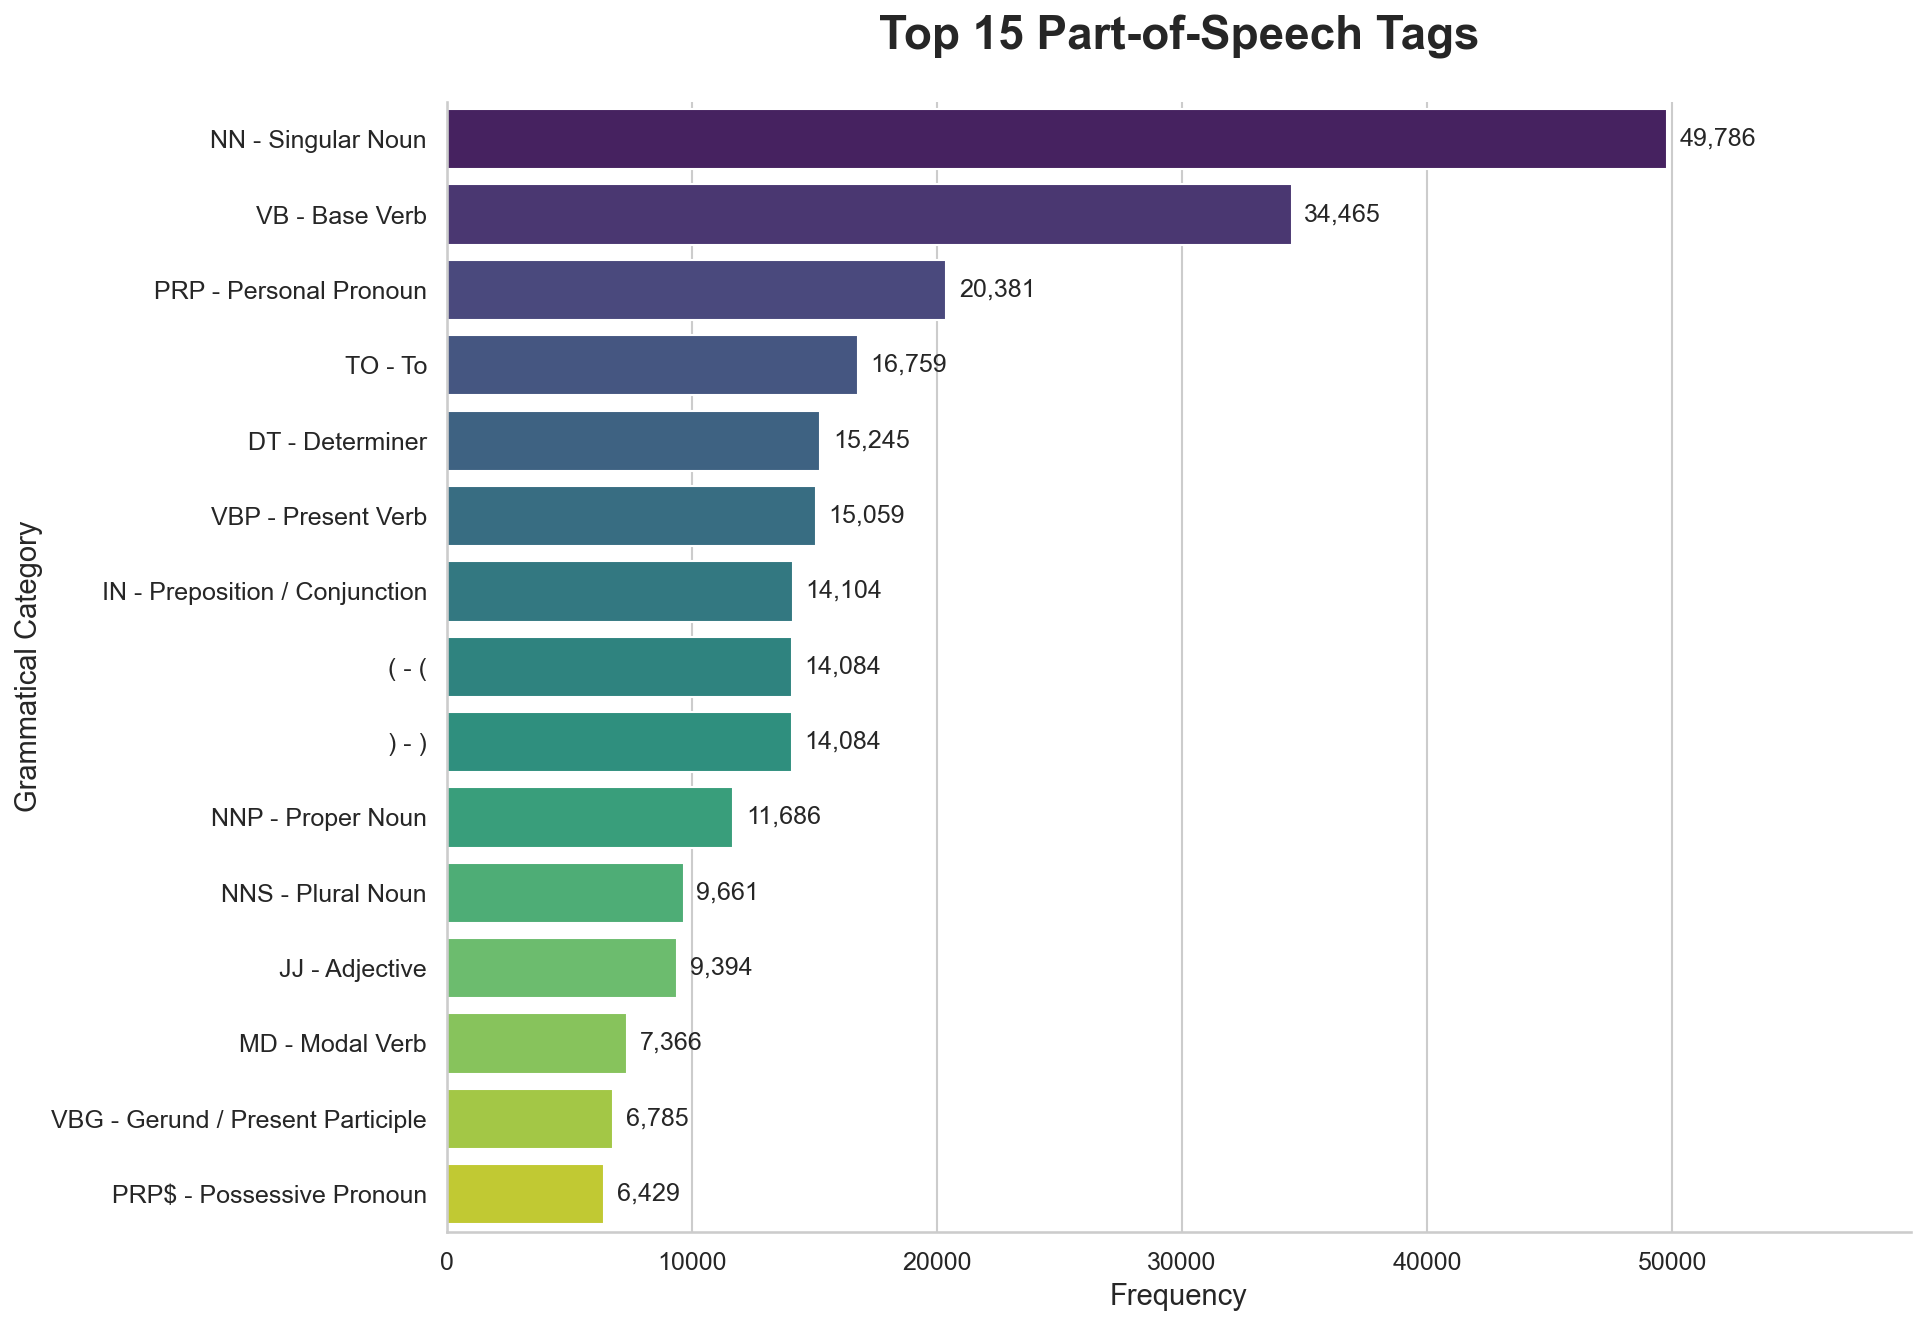

Total unique POS tags: 36
Total tagged tokens: 272214


In [24]:
# Map POS tags to readable descriptions
pos_descriptions = {
    "NN": "Singular Noun",
    "NNS": "Plural Noun",
    "NNP": "Proper Noun",
    "NNPS": "Plural Proper Noun",
    "VB": "Base Verb",
    "VBP": "Present Verb",
    "VBZ": "Third Person Verb",
    "VBG": "Gerund / Present Participle",
    "VBD": "Past Tense Verb",
    "VBN": "Past Participle",
    "JJ": "Adjective",
    "RB": "Adverb",
    "PRP": "Personal Pronoun",
    "PRP$": "Possessive Pronoun",
    "DT": "Determiner",
    "IN": "Preposition / Conjunction",
    "TO": "To",
    "MD": "Modal Verb",
    "CC": "Coordinating Conjunction",
    "CD": "Cardinal Number",
    "WRB": "WH-Adverb",
    "WP": "WH-Pronoun",
    "RP": "Particle",
    ".": "Sentence Punctuation",
    ",": "Comma"
}

# Add readable labels
pos_df["Description"] = pos_df["POS Tag"].map(
    pos_descriptions
).fillna(pos_df["POS Tag"])

pos_df["Label"] = (
    pos_df["POS Tag"] + " - " + pos_df["Description"]
)

# Display POS frequency table
print("========== POS TAG DISTRIBUTION ==========")

display(pos_df[["POS Tag", "Description", "Frequency"]])

# Create visualization
fig, ax = plt.subplots(figsize=(13, 9), dpi=150)

sns.barplot(
    data=pos_df,
    x="Frequency",
    y="Label",
    hue="Label",
    palette="viridis",
    legend=False,
    ax=ax
)

# Display frequency values
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="{:,.0f}",
        padding=6,
        fontsize=12,
        fontweight="medium"
    )

# Chart formatting
ax.set_title(
    "Top 15 Part-of-Speech Tags",
    fontsize=22,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Frequency", fontsize=14)
ax.set_ylabel("Grammatical Category", fontsize=14)

ax.tick_params(axis="both", labelsize=12)
ax.set_xlim(0, pos_df["Frequency"].max() * 1.20)

ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

print("Total unique POS tags:", len(pos_frequency))
print("Total tagged tokens:", sum(pos_frequency.values()))

In [27]:
%pip install spacy

  Using cached spacy-3.8.18-cp311-cp311-win_amd64.whl.metadata (28 kB)
  Using cached spacy_legacy-3.0.12-py2.py3-none-any.whl.metadata (2.8 kB)
  Using cached spacy_loggers-1.0.5-py3-none-any.whl.metadata (23 kB)
  Using cached murmurhash-1.0.16-cp311-cp311-win_amd64.whl.metadata (2.3 kB)
  Using cached cymem-2.0.16-cp311-cp311-win_amd64.whl.metadata (10.0 kB)
  Using cached preshed-3.0.15-cp311-cp311-win_amd64.whl.metadata (5.4 kB)
  Using cached thinc-8.3.14-cp311-cp311-win_amd64.whl.metadata (15 kB)
  Using cached wasabi-1.1.3-py3-none-any.whl.metadata (28 kB)
  Using cached srsly-2.5.6-cp311-cp311-win_amd64.whl.metadata (20 kB)
  Using cached catalogue-2.0.10-py3-none-any.whl.metadata (14 kB)
  Using cached weasel-1.0.1-py3-none-any.whl.metadata (4.8 kB)
  Using cached confection-1.3.4-py3-none-any.whl.metadata (19 kB)
  Using cached typer-0.29.2-py3-none-any.whl.metadata (16 kB)
  Using cached blis-1.3.4-cp311-cp311-win_amd64.whl.metadata (8.6 kB)
  Using cached shellingham-1.5.4


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\picka\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [28]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "spacy",
    "download",
    "en_core_web_sm"
])

0

In [29]:
import spacy

nlp = spacy.load("en_core_web_sm")

print("spaCy Version:", spacy.__version__)
print("English language model loaded successfully!")

spaCy Version: 3.8.18
English language model loaded successfully!


In [30]:
import spacy
from collections import Counter

# Load pretrained English NLP model
nlp = spacy.load("en_core_web_sm")

# Process customer queries in batches
# Batch processing improves efficiency
docs = list(
    nlp.pipe(
        df["instruction"].tolist(),
        batch_size=128
    )
)

# Extract named entities
df["named_entities"] = [
    [(ent.text, ent.label_) for ent in doc.ents]
    for doc in docs
]

# Identify queries containing entities
entity_mask = df["named_entities"].apply(len) > 0

# Display sample results
print("========== NAMED ENTITY RECOGNITION ==========")

display(
    df.loc[
        entity_mask,
        ["instruction", "named_entities"]
    ].head(15)
)

# Count entity types
entity_frequency = Counter(
    label
    for entities in df["named_entities"]
    for entity, label in entities
)

# Create entity frequency dataframe
entity_df = pd.DataFrame(
    entity_frequency.most_common(),
    columns=["Entity Type", "Frequency"]
)

# Add entity descriptions
entity_df["Description"] = entity_df["Entity Type"].apply(
    lambda label: spacy.explain(label) or label
)

print("\n========== ENTITY TYPE DISTRIBUTION ==========")
display(entity_df)

# Summary statistics
print("\n========== NER STATISTICS ==========")
print("Total queries:", len(df))
print("Queries containing entities:", entity_mask.sum())
print("Total extracted entities:", sum(entity_frequency.values()))
print("Unique entity types:", len(entity_frequency))

========== NAMED ENTITY RECOGNITION ==========


,instruction,named_entities
370,cancel purchase732201349959,"[(purchase732201349959, ORG)]"
374,I need help to cancel purchase370795561790,"[(purchase370795561790, ORG)]"
418,I am trying to cancel purchaes {{Order Number}},"[({Order Number, PERSON)]"
497,i nee help to cancel order {{Order Number}},"[(nee, ORG)]"
729,cancel purchase370795561790,"[(purchase370795561790, ORG)]"
763,cancel purchase00123842,"[(purchase00123842, ORG)]"
779,cancel purchase113542617735902,"[(purchase113542617735902, ORG)]"
843,I am trying to cancel purchaes {{Order Number}},"[({Order Number, PERSON)]"
910,cancel purchase00004587345,"[(purchase00004587345, ORG)]"
1076,update purchase00004587345,"[(purchase00004587345, ORG)]"



========== ENTITY TYPE DISTRIBUTION ==========


,Entity Type,Frequency,Description
0,MONEY,534,"Monetary values, including unit"
1,ORG,402,"Companies, agencies, institutions, etc."
2,PERSON,236,"People, including fictional"
3,DATE,174,Absolute or relative dates or periods
4,GPE,136,"Countries, cities, states"
5,TIME,49,Times smaller than a day
6,CARDINAL,18,Numerals that do not fall under another type
7,NORP,3,Nationalities or religious or political groups
8,WORK_OF_ART,1,"Titles of books, songs, etc."
9,LOC,1,"Non-GPE locations, mountain ranges, bodies of water"



========== NER STATISTICS ==========
Total queries: 26872
Queries containing entities: 1546
Total extracted entities: 1555
Unique entity types: 11


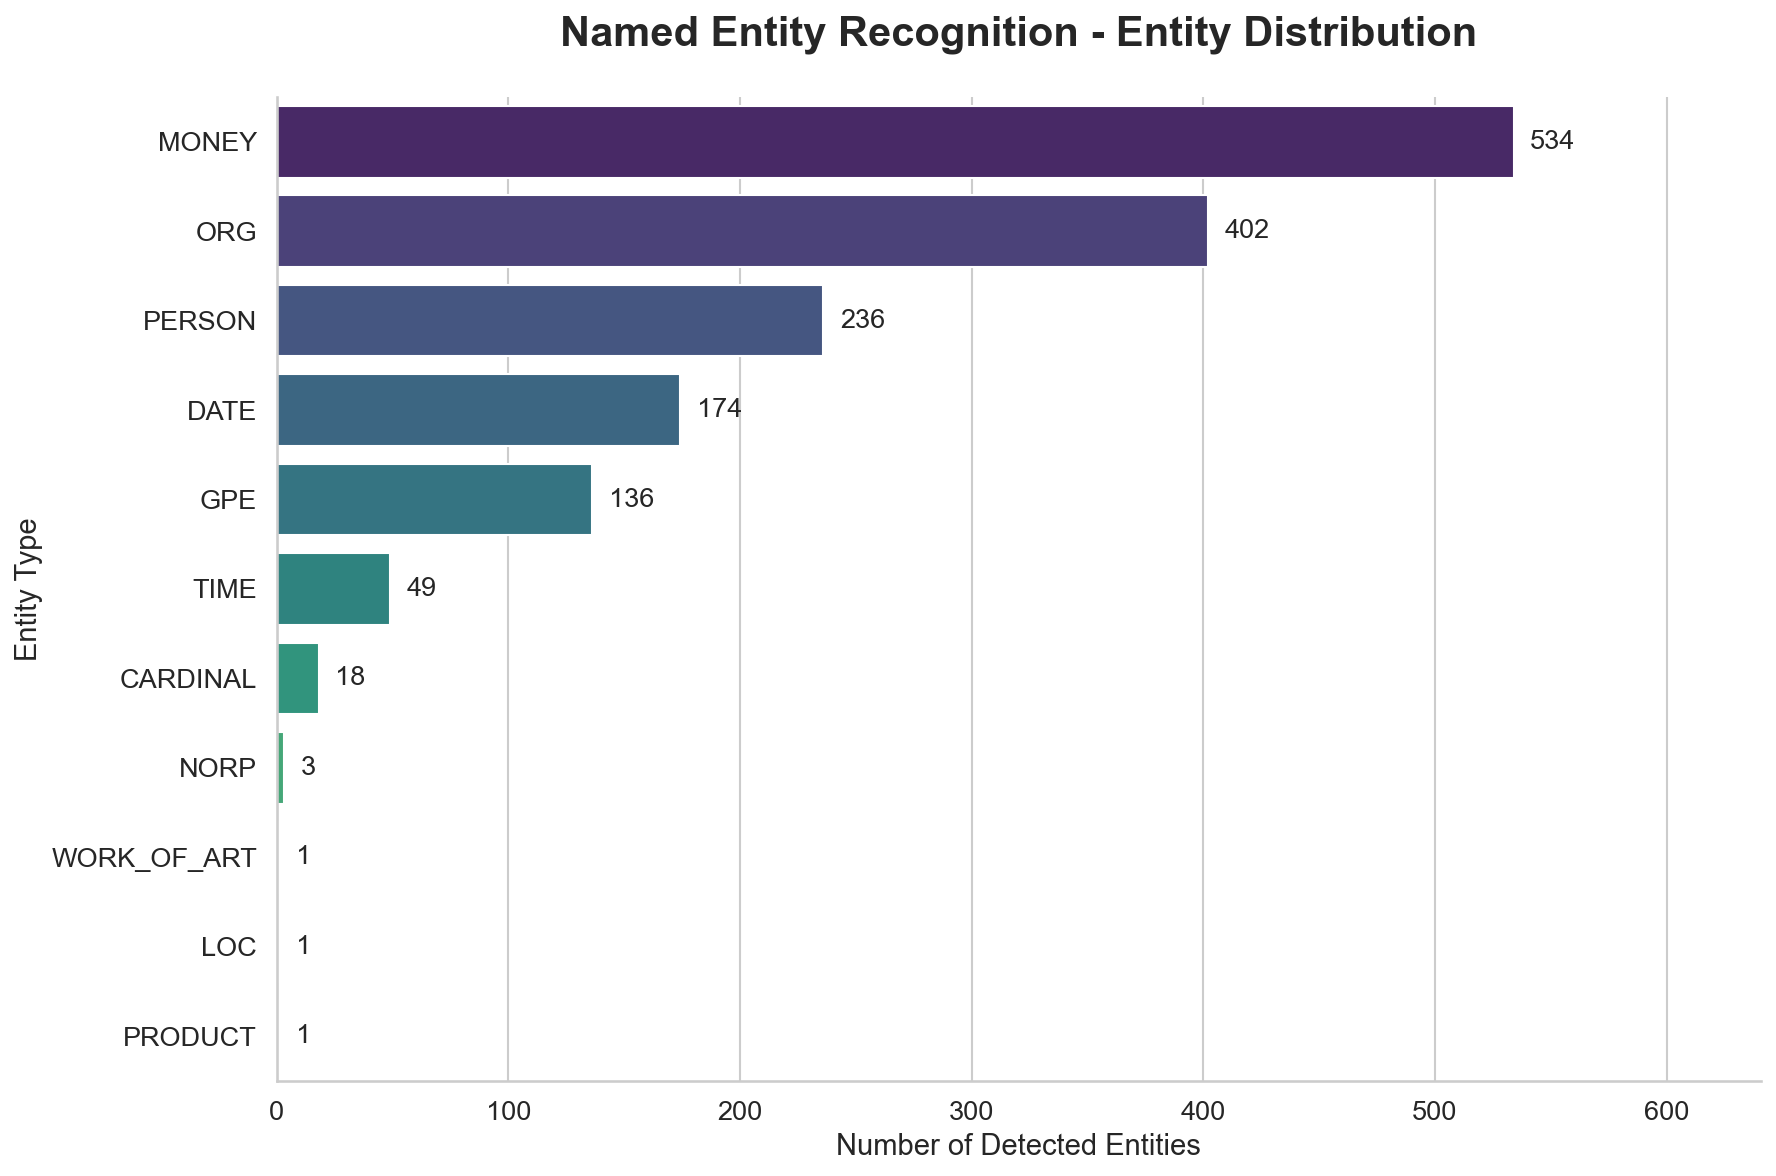

========== NER SUMMARY ==========
Total queries: 26,872
Queries containing entities: 1,546
Total detected entities: 1,555
Unique entity types: 11
Entity detection coverage: 5.75%


In [31]:
# Prepare entity distribution data
ner_plot_df = entity_df.copy()

# Create chart
fig, ax = plt.subplots(figsize=(12, 8), dpi=150)

sns.barplot(
    data=ner_plot_df,
    x="Frequency",
    y="Entity Type",
    hue="Entity Type",
    palette="viridis",
    legend=False,
    ax=ax
)

# Display frequency values
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=8,
        fontsize=13,
        fontweight="medium"
    )

# Chart formatting
ax.set_title(
    "Named Entity Recognition - Entity Distribution",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Number of Detected Entities", fontsize=14)
ax.set_ylabel("Entity Type", fontsize=14)

ax.tick_params(axis="both", labelsize=13)
ax.set_xlim(0, ner_plot_df["Frequency"].max() * 1.20)

ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

# Summary statistics
print("========== NER SUMMARY ==========")

print(f"Total queries: {len(df):,}")
print(f"Queries containing entities: {entity_mask.sum():,}")
print(f"Total detected entities: {sum(entity_frequency.values()):,}")
print(f"Unique entity types: {len(entity_frequency)}")
print(f"Entity detection coverage: {entity_mask.mean() * 100:.2f}%")

In [32]:
import re
from collections import Counter

# Define domain-specific entity patterns
entity_patterns = {

    "ORDER_ID": r"\b(?:order|purchase)\s*(?:number|id|no\.?)?\s*#?\s*(\d+)\b",

    "INVOICE_ID": r"\b(?:invoice|bill)\s*(?:number|id|no\.?)?\s*#?\s*(\d+)\b",

    "ACCOUNT_ID": r"\baccount\s*(?:number|id|no\.?)?\s*#?\s*(\d+)\b",

    "TRACKING_ID": r"\btracking\s*(?:number|id|no\.?)?\s*#?\s*(\d+)\b",

    "EMAIL": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",

    "MONEY": r"(?:₹|\$|€|£|Rs\.?)\s*\d+(?:,\d{3})*(?:\.\d{1,2})?",

    "PLACEHOLDER": r"\{\{[^{}]+\}\}"
}


# Domain-specific entity extraction function
def extract_domain_entities(text):

    entities = []

    for label, pattern in entity_patterns.items():

        matches = re.finditer(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        for match in matches:
            entities.append((match.group(), label))

    return entities


# Apply entity extraction to original text
df["domain_entities"] = df["instruction"].apply(
    extract_domain_entities
)

# Identify queries containing domain entities
domain_mask = df["domain_entities"].apply(len) > 0

# Display sample results
print("========== DOMAIN-SPECIFIC ENTITIES ==========")

display(
    df.loc[
        domain_mask,
        ["instruction", "domain_entities"]
    ].sample(15, random_state=42)
)

# Calculate entity frequencies
domain_frequency = Counter(
    label
    for entities in df["domain_entities"]
    for entity, label in entities
)

domain_entity_df = pd.DataFrame(
    domain_frequency.most_common(),
    columns=["Entity Type", "Frequency"]
)

print("\n========== DOMAIN ENTITY DISTRIBUTION ==========")

display(domain_entity_df)

# Summary statistics
print("\n========== DOMAIN ENTITY STATISTICS ==========")

print(f"Total queries: {len(df):,}")
print(f"Queries containing domain entities: {domain_mask.sum():,}")
print(f"Total extracted entities: {sum(domain_frequency.values()):,}")
print(f"Unique detected entity types: {len(domain_frequency)}")

print(f"Detection coverage: {domain_mask.mean() * 100:.2f}%")

========== DOMAIN-SPECIFIC ENTITIES ==========


,instruction,domain_entities
12777,shipmetns to {{Delivery City}},"[({{Delivery City}}, PLACEHOLDER)]"
1865,could i change something of purchase {{Order Number}},"[({{Order Number}}, PLACEHOLDER)]"
24309,use {{Account Category}} acdcount,"[({{Account Category}}, PLACEHOLDER)]"
11542,removing {{Account Type}} acconut,"[({{Account Type}}, PLACEHOLDER)]"
15642,download bill from {{Person Name}},"[({{Person Name}}, PLACEHOLDER)]"
24479,can ya help me change to the {{Account Type}} account,"[({{Account Type}}, PLACEHOLDER)]"
496,"I purchased some articles, cancel order {{Order Number}}","[({{Order Number}}, PLACEHOLDER)]"
25834,show me purchase {{Order Number}} current status,"[({{Order Number}}, PLACEHOLDER)]"
25724,how do I see order {{Order Number}} current status?,"[({{Order Number}}, PLACEHOLDER)]"
11799,"I never use the {{Account Type}} account, I need help canceling it","[({{Account Type}}, PLACEHOLDER)]"



========== DOMAIN ENTITY DISTRIBUTION ==========


,Entity Type,Frequency
0,PLACEHOLDER,7042
1,INVOICE_ID,994
2,ORDER_ID,29
3,MONEY,1



========== DOMAIN ENTITY STATISTICS ==========
Total queries: 26,872
Queries containing domain entities: 7,694
Total extracted entities: 8,066
Unique detected entity types: 4
Detection coverage: 28.63%


In [33]:
from spacy import displacy
from collections import Counter

# Extract dependency relationships
df["dependency_tags"] = [
    [
        (token.text, token.dep_, token.head.text)
        for token in doc
    ]
    for doc in docs
]

# Display sample results
print("========== DEPENDENCY PARSING ==========")

display(
    df[["instruction", "dependency_tags"]]
    .sample(5, random_state=42)
)

# Count dependency relationships
dependency_frequency = Counter(
    token.dep_
    for doc in docs
    for token in doc
)

# Create frequency table
dependency_df = pd.DataFrame(
    dependency_frequency.most_common(15),
    columns=["Dependency", "Frequency"]
)

dependency_df["Description"] = dependency_df[
    "Dependency"
].apply(
    lambda label: spacy.explain(label) or label
)

print("\n========== TOP DEPENDENCY RELATIONSHIPS ==========")

display(dependency_df)

print(
    "Total unique dependency types:",
    len(dependency_frequency)
)

# Example sentence
sample_text = "I want to cancel my order."

sample_doc = nlp(sample_text)

# Detailed dependency analysis
dependency_details = pd.DataFrame([
    {
        "Word": token.text,
        "POS": token.pos_,
        "Dependency": token.dep_,
        "Head Word": token.head.text
    }
    for token in sample_doc
])

print("\n========== EXAMPLE SENTENCE ==========")
print(sample_text)

display(dependency_details)

# Visualize dependency tree
displacy.render(
    sample_doc,
    style="dep",
    jupyter=True,
    options={
        "compact": True,
        "distance": 140,
        "word_spacing": 50,
        "font": "Arial",
        "bg": "#FFFFFF",
        "color": "#1E293B"
    }
)

========== DEPENDENCY PARSING ==========


,instruction,dependency_tags
9329,I can't talk with a human agent,"[(I, nsubj, talk), (ca, aux, talk), (n't, neg, talk), (talk, ROOT, talk), (with, prep, talk), ( , dep, with), (a, det, agent), (human, amod, agent..."
4160,I have got to locate hte bills from {{Person Name}},"[(I, nsubj, got), (have, aux, got), (got, ROOT, got), (to, aux, locate), (locate, xcomp, got), (hte, compound, bills), (bills, dobj, locate), (fro..."
18500,"I cannot pay, help me to inform of a problem with payments","[(I, nsubj, pay), (can, aux, pay), (not, neg, pay), (pay, ROOT, pay), (,, punct, pay), (help, conj, pay), (me, nsubj, inform), (to, aux, inform), ..."
8840,I want help speaking to customer service,"[(I, nsubj, want), (want, ROOT, want), (help, dobj, want), (speaking, acl, help), (to, prep, speaking), (customer, compound, service), (service, p..."
5098,I try to see th accepted payment options,"[(I, nsubj, try), (try, ROOT, try), (to, aux, see), (see, xcomp, try), (th, intj, see), (accepted, amod, options), (payment, compound, options), (..."



========== TOP DEPENDENCY RELATIONSHIPS ==========


,Dependency,Frequency,Description
0,punct,33973,punctuation
1,dobj,30018,direct object
2,aux,28284,auxiliary
3,ROOT,26912,root
4,nsubj,26111,nominal subject
5,det,15863,determiner
6,compound,15586,compound
7,prep,15480,prepositional modifier
8,pobj,14627,object of preposition
9,xcomp,10584,open clausal complement


Total unique dependency types: 39

========== EXAMPLE SENTENCE ==========
I want to cancel my order.


,Word,POS,Dependency,Head Word
0,I,PRON,nsubj,want
1,want,VERB,ROOT,want
2,to,PART,aux,cancel
3,cancel,VERB,xcomp,want
4,my,PRON,poss,order
5,order,NOUN,dobj,cancel
6,.,PUNCT,punct,want


========== NOUN PHRASE EXTRACTION ==========


,instruction,noun_phrases
9329,I can't talk with a human agent,"[I, a human agent]"
4160,I have got to locate hte bills from {{Person Name}},"[I, hte bills, {{Person Name]"
18500,"I cannot pay, help me to inform of a problem with payments","[I, me, a problem, payments]"
8840,I want help speaking to customer service,"[I, help, customer service]"
5098,I try to see th accepted payment options,"[I, accepted payment options]"
17250,where to sign up to the company nmewsletter,"[the company, nmewsletter]"
3589,I'd like to see the withdrwaal fee how can i do it,"[I, the withdrwaal fee, i, it]"
9043,I want to speak with someone,"[I, someone]"
15800,can you help me getting bill #85632?,"[you, me, bill]"
4384,I don't know how to take a quick look at invoice #12588,"[I, a quick look, invoice]"



========== TOP 15 NOUN PHRASES ==========


,Noun Phrase,Frequency
0,{order number,1829
1,{{person name,839
2,my money,344
3,a product,324
4,account type,317
5,account category,311
6,customer support,307
7,a problem,301
8,a refund,290
9,customer service,278



========== CHUNKING STATISTICS ==========
Total queries: 26872
Total noun phrases: 76398
Unique multi-word noun phrases: 3282
Average noun phrases per query: 2.84


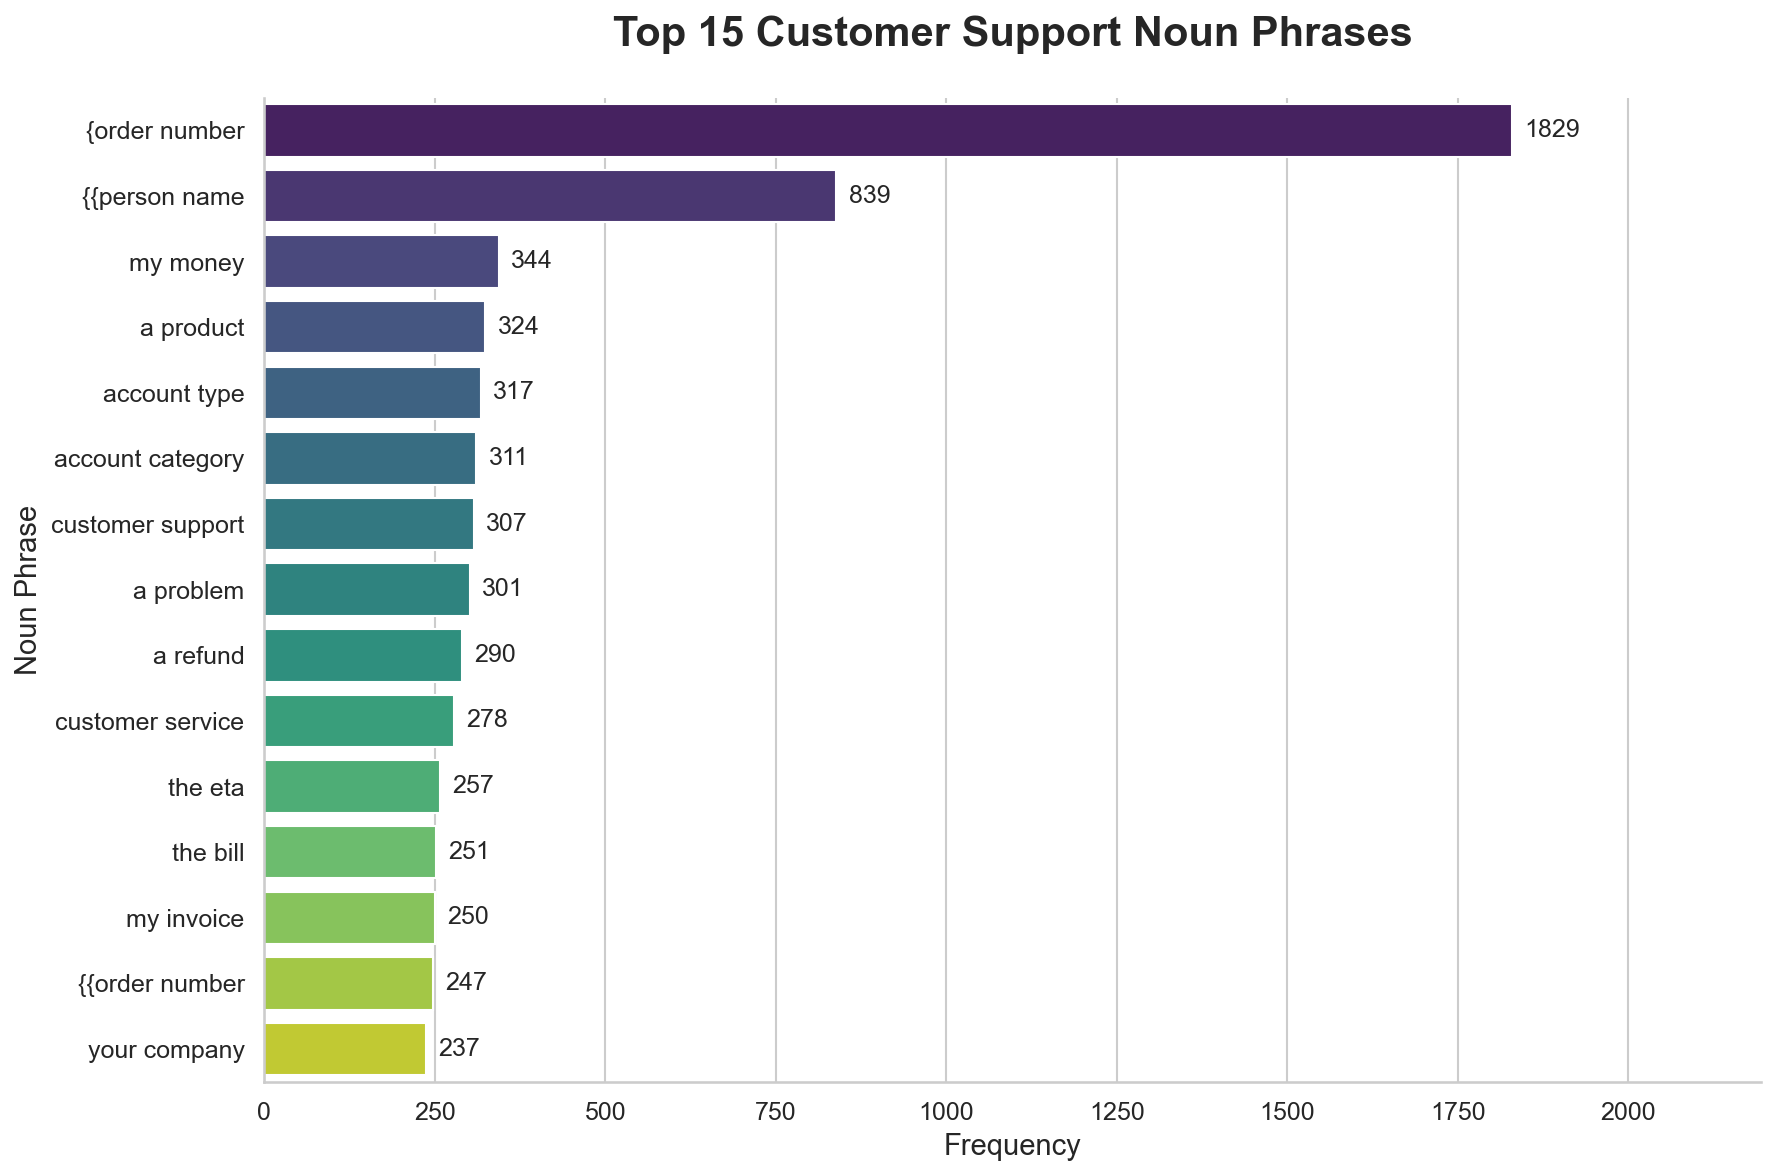

In [34]:
# Extract noun phrases using spaCy
df["noun_phrases"] = [
    [chunk.text for chunk in doc.noun_chunks]
    for doc in docs
]

# Display sample results
print("========== NOUN PHRASE EXTRACTION ==========")

display(
    df[["instruction", "noun_phrases"]]
    .sample(10, random_state=42)
)

# Calculate noun phrase frequencies
noun_phrase_frequency = Counter(
    phrase.lower().strip()
    for phrases in df["noun_phrases"]
    for phrase in phrases
    if len(phrase.split()) >= 2
)

# Create frequency table
noun_phrase_df = pd.DataFrame(
    noun_phrase_frequency.most_common(15),
    columns=["Noun Phrase", "Frequency"]
)

print("\n========== TOP 15 NOUN PHRASES ==========")

display(noun_phrase_df)

# Summary statistics
print("\n========== CHUNKING STATISTICS ==========")

print("Total queries:", len(df))

print(
    "Total noun phrases:",
    df["noun_phrases"].apply(len).sum()
)

print(
    "Unique multi-word noun phrases:",
    len(noun_phrase_frequency)
)

print(
    "Average noun phrases per query:",
    round(df["noun_phrases"].apply(len).mean(), 2)
)

# Visualization
fig, ax = plt.subplots(figsize=(12, 8), dpi=150)

sns.barplot(
    data=noun_phrase_df,
    x="Frequency",
    y="Noun Phrase",
    hue="Noun Phrase",
    palette="viridis",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=6,
        fontsize=12
    )

ax.set_title(
    "Top 15 Customer Support Noun Phrases",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Frequency", fontsize=14)
ax.set_ylabel("Noun Phrase", fontsize=14)

ax.tick_params(axis="both", labelsize=12)
ax.set_xlim(0, noun_phrase_df["Frequency"].max() * 1.20)

ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

========== ONE-HOT ENCODING ==========


,account,delivery,order,payment,refund,support
Word,,,,,,
order,0,0,1,0,0,0
refund,0,0,0,0,1,0
payment,0,0,0,1,0,0
account,1,0,0,0,0,0
delivery,0,1,0,0,0,0
support,0,0,0,0,0,1



========== ENCODING STATISTICS ==========
Vocabulary size: 6
Matrix shape: (6, 6)
Total elements: 36
Non-zero elements: 6


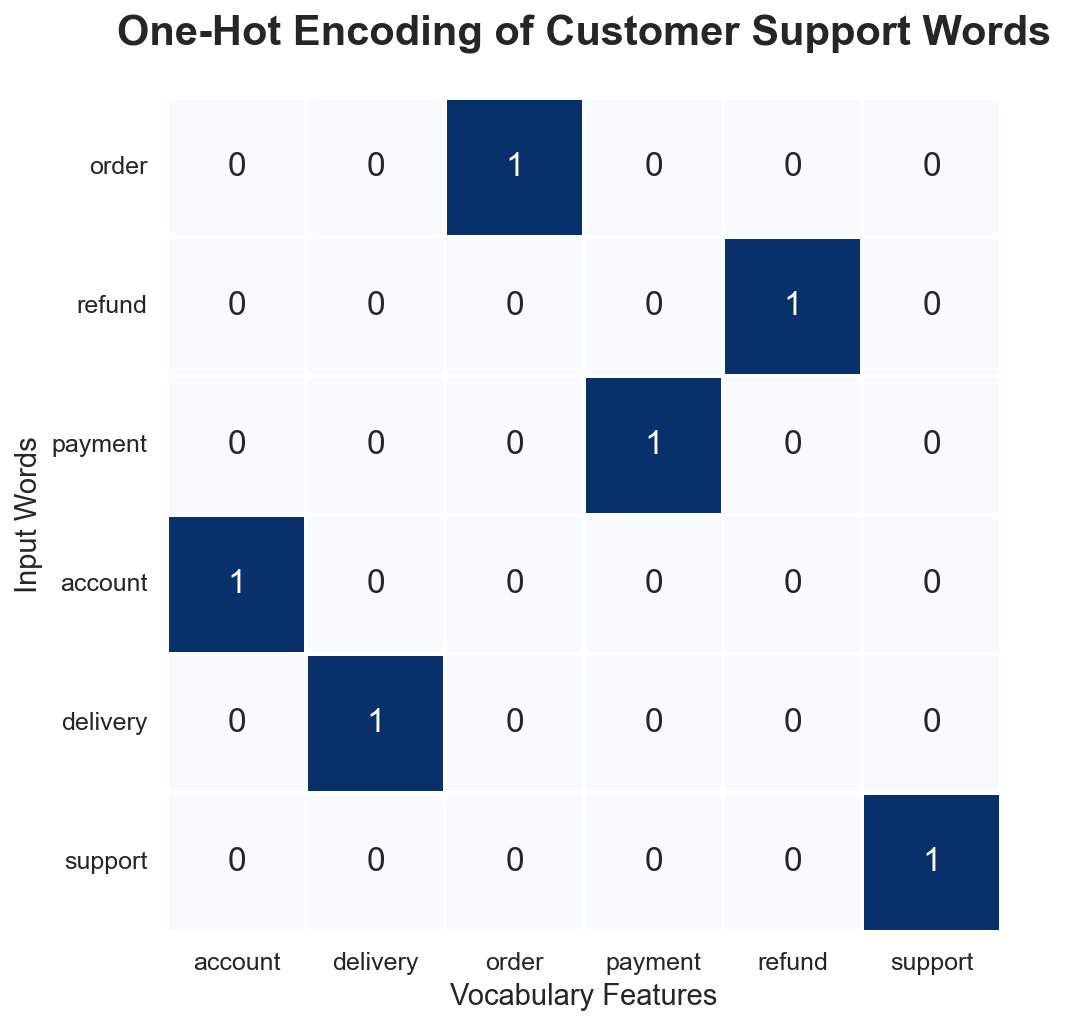

In [35]:
from sklearn.preprocessing import OneHotEncoder

# Sample customer support vocabulary
sample_words = [
    "order",
    "refund",
    "payment",
    "account",
    "delivery",
    "support"
]

# Convert into a 2D array
words_array = np.array(sample_words).reshape(-1, 1)

# Initialize One-Hot Encoder
onehot_encoder = OneHotEncoder(
    sparse_output=False,
    dtype=int
)

# Generate encoded vectors
onehot_matrix = onehot_encoder.fit_transform(
    words_array
)

# Convert into readable dataframe
onehot_df = pd.DataFrame(
    onehot_matrix,
    columns=onehot_encoder.categories_[0],
    index=sample_words
)

onehot_df.index.name = "Word"

print("========== ONE-HOT ENCODING ==========")

display(onehot_df)

print("\n========== ENCODING STATISTICS ==========")

print("Vocabulary size:", len(sample_words))
print("Matrix shape:", onehot_matrix.shape)
print("Total elements:", onehot_matrix.size)
print("Non-zero elements:", np.count_nonzero(onehot_matrix))

# Visualize encoded matrix
fig, ax = plt.subplots(figsize=(10, 7), dpi=150)

sns.heatmap(
    onehot_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    linewidths=1,
    linecolor="white",
    annot_kws={"size": 16},
    square=True,
    ax=ax
)

ax.set_title(
    "One-Hot Encoding of Customer Support Words",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Vocabulary Features", fontsize=14)
ax.set_ylabel("Input Words", fontsize=14)

plt.xticks(rotation=0, fontsize=12)
plt.yticks(rotation=0, fontsize=12)

plt.tight_layout()
plt.show()

========== BAG OF WORDS STATISTICS ==========
Total documents: 26872
Vocabulary size: 2681
Matrix shape: (26872, 2681)
Total matrix elements: 72,043,832
Non-zero elements: 125,962
Matrix sparsity: 99.83%

========== TOP 15 BOW FEATURES ==========


,Word,Frequency
0,help,6319
1,account,5447
2,order,4879
3,need,4061
4,want,3110
5,see,3105
6,assistance,3005
7,number,2953
8,not,2842
9,know,2698



========== SAMPLE BOW MATRIX ==========


,account,cancel,my,order,payment,refund,request,track,update
cancel my order,0,1,1,1,0,0,0,0,0
track my order,0,0,1,1,0,0,0,1,0
request a refund,0,0,0,0,0,1,1,0,0
refund my payment,0,0,1,0,1,1,0,0,0
update my account,1,0,1,0,0,0,0,0,1


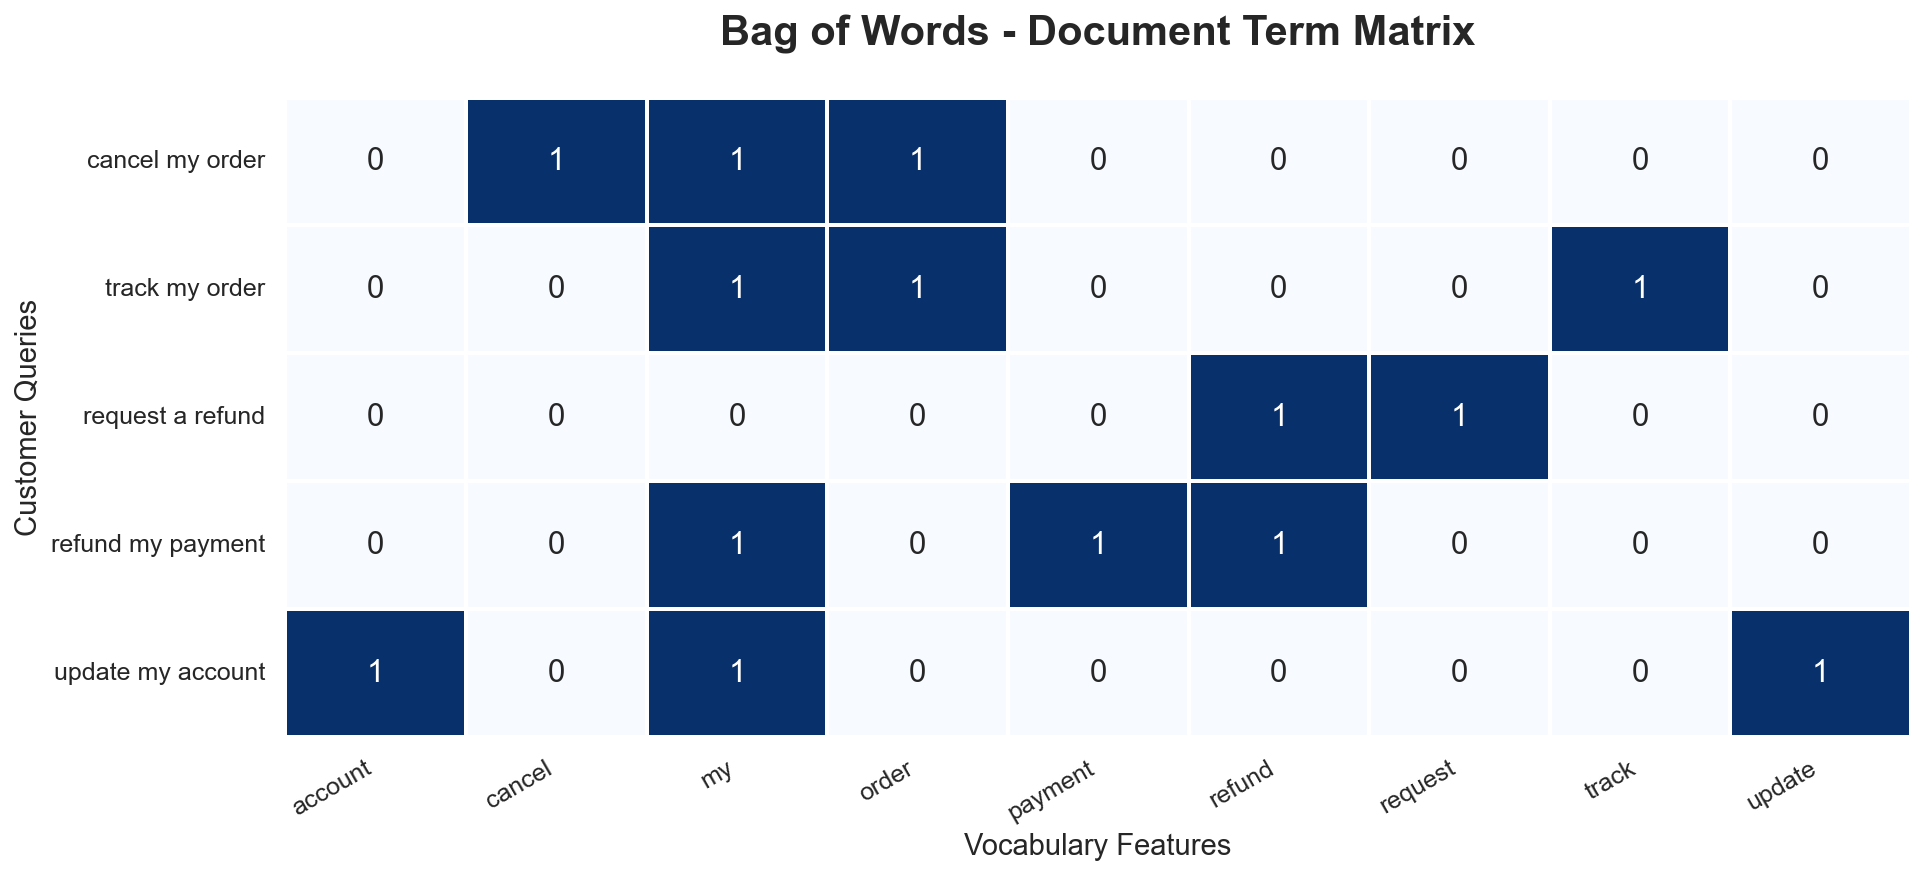

In [36]:
from sklearn.feature_extraction.text import CountVectorizer

# Convert lemmatized tokens into text
df["processed_text"] = df["lemmatized_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Initialize Bag of Words vectorizer
bow_vectorizer = CountVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

# Generate Bag of Words matrix
bow_matrix = bow_vectorizer.fit_transform(
    df["processed_text"]
)

# Extract vocabulary
bow_features = bow_vectorizer.get_feature_names_out()

# Calculate matrix statistics
total_elements = bow_matrix.shape[0] * bow_matrix.shape[1]

non_zero_elements = bow_matrix.nnz

sparsity = (
    1 - non_zero_elements / total_elements
) * 100

print("========== BAG OF WORDS STATISTICS ==========")

print("Total documents:", bow_matrix.shape[0])
print("Vocabulary size:", bow_matrix.shape[1])
print("Matrix shape:", bow_matrix.shape)
print(f"Total matrix elements: {total_elements:,}")
print(f"Non-zero elements: {non_zero_elements:,}")
print(f"Matrix sparsity: {sparsity:.2f}%")

# Calculate word frequencies
bow_word_counts = np.asarray(
    bow_matrix.sum(axis=0)
).ravel()

bow_frequency_df = pd.DataFrame({
    "Word": bow_features,
    "Frequency": bow_word_counts
}).sort_values(
    "Frequency",
    ascending=False
).reset_index(drop=True)

print("\n========== TOP 15 BOW FEATURES ==========")

display(bow_frequency_df.head(15))

# Demonstrate BoW using sample customer queries
sample_queries = [
    "cancel my order",
    "track my order",
    "request a refund",
    "refund my payment",
    "update my account"
]

sample_vectorizer = CountVectorizer()

sample_matrix = sample_vectorizer.fit_transform(
    sample_queries
)

sample_bow_df = pd.DataFrame(
    sample_matrix.toarray(),
    columns=sample_vectorizer.get_feature_names_out(),
    index=sample_queries
)

print("\n========== SAMPLE BOW MATRIX ==========")

display(sample_bow_df)

# Visualize sample Bag of Words matrix
fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

sns.heatmap(
    sample_bow_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    linewidths=1,
    linecolor="white",
    annot_kws={"size": 15},
    ax=ax
)

ax.set_title(
    "Bag of Words - Document Term Matrix",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Vocabulary Features", fontsize=14)
ax.set_ylabel("Customer Queries", fontsize=14)

plt.xticks(rotation=30, ha="right", fontsize=12)
plt.yticks(rotation=0, fontsize=12)

plt.tight_layout()
plt.show()

========== TF-IDF STATISTICS ==========
Total documents: 26872
Vocabulary size: 2681
Matrix shape: (26872, 2681)
Total matrix elements: 72,043,832
Non-zero elements: 125,962
Matrix sparsity: 99.83%

========== TOP 15 TF-IDF FEATURES ==========


,Word,Mean TF-IDF Score
0,account,0.05796
1,help,0.05713
2,order,0.05615
3,need,0.04290
4,see,0.03628
5,number,0.03581
6,want,0.03578
7,assistance,0.03544
8,not,0.03303
9,know,0.03222



========== SAMPLE TF-IDF MATRIX ==========


,account,cancel,my,order,payment,refund,request,track,update
cancel my order,0.000,0.713,0.402,0.575,0.000,0.000,0.000,0.000,0.000
track my order,0.000,0.000,0.402,0.575,0.000,0.000,0.000,0.713,0.000
request a refund,0.000,0.000,0.000,0.000,0.000,0.628,0.778,0.000,0.000
refund my payment,0.000,0.000,0.402,0.000,0.713,0.575,0.000,0.000,0.000
update my account,0.657,0.000,0.370,0.000,0.000,0.000,0.000,0.000,0.657


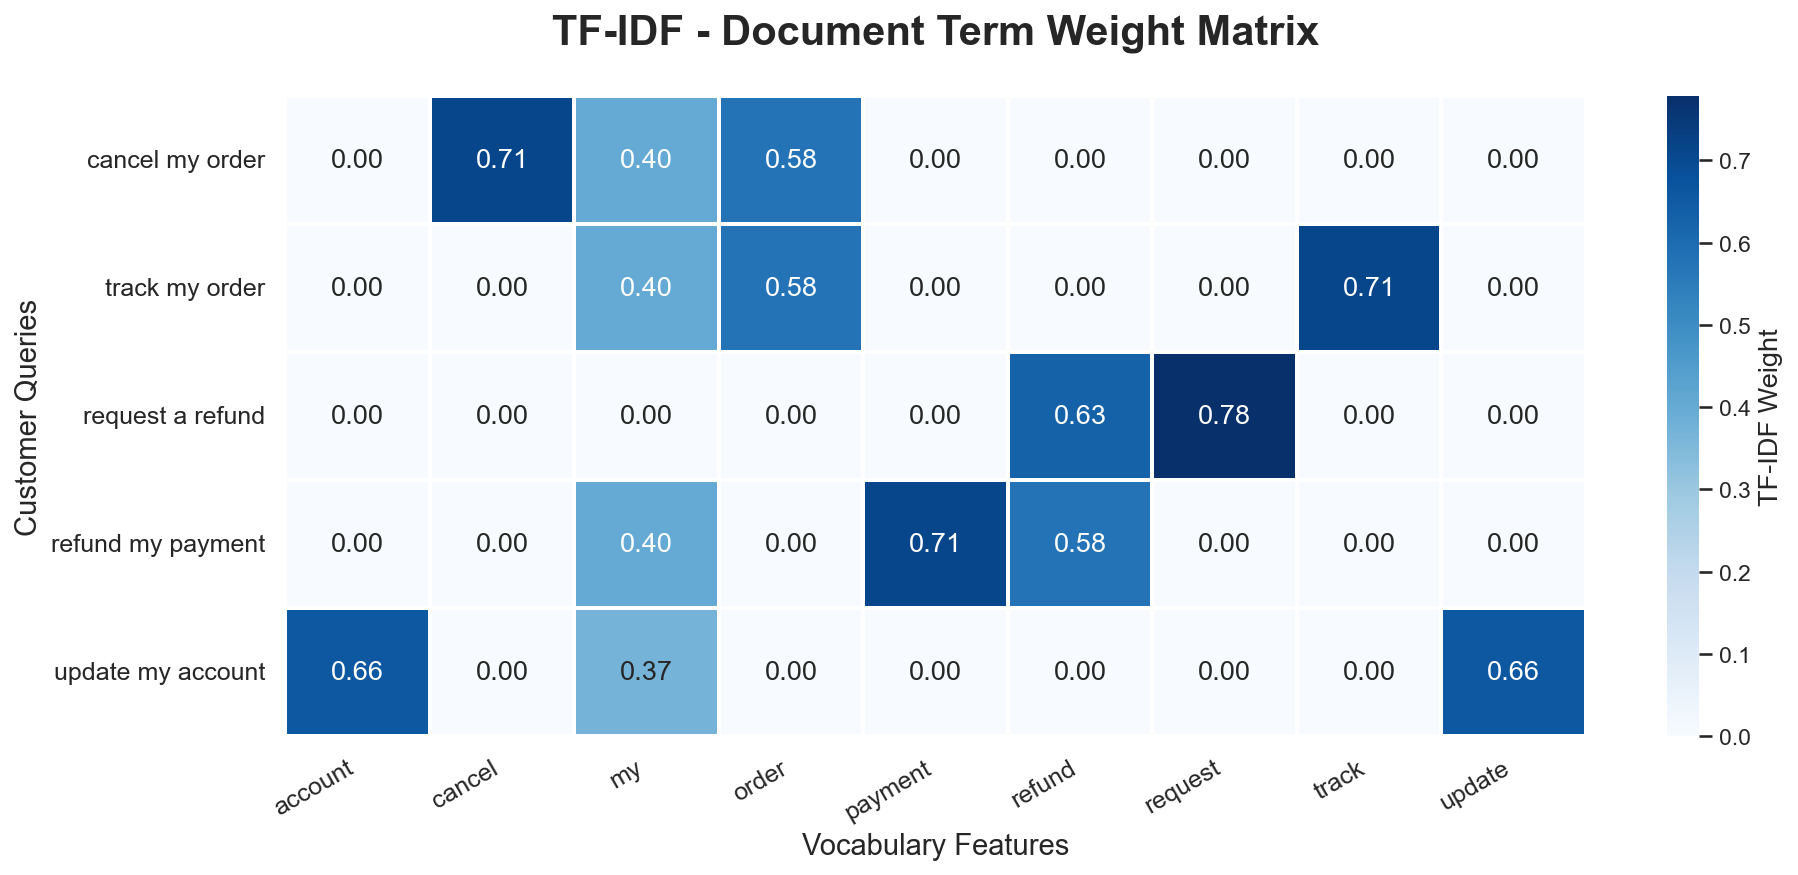

In [37]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 1)
)

# Generate TF-IDF matrix
tfidf_matrix = tfidf_vectorizer.fit_transform(
    df["processed_text"]
)

# Extract vocabulary
tfidf_features = tfidf_vectorizer.get_feature_names_out()

# Calculate matrix statistics
tfidf_total = tfidf_matrix.shape[0] * tfidf_matrix.shape[1]

tfidf_nonzero = tfidf_matrix.nnz

tfidf_sparsity = (
    1 - tfidf_nonzero / tfidf_total
) * 100

print("========== TF-IDF STATISTICS ==========")

print("Total documents:", tfidf_matrix.shape[0])
print("Vocabulary size:", tfidf_matrix.shape[1])
print("Matrix shape:", tfidf_matrix.shape)
print(f"Total matrix elements: {tfidf_total:,}")
print(f"Non-zero elements: {tfidf_nonzero:,}")
print(f"Matrix sparsity: {tfidf_sparsity:.2f}%")

# Calculate average TF-IDF scores
mean_tfidf = np.asarray(
    tfidf_matrix.mean(axis=0)
).ravel()

tfidf_df = pd.DataFrame({
    "Word": tfidf_features,
    "Mean TF-IDF Score": mean_tfidf
}).sort_values(
    "Mean TF-IDF Score",
    ascending=False
).reset_index(drop=True)

print("\n========== TOP 15 TF-IDF FEATURES ==========")

display(tfidf_df.head(15).round(5))

# TF-IDF demonstration using previous sample queries
sample_tfidf_vectorizer = TfidfVectorizer()

sample_tfidf_matrix = sample_tfidf_vectorizer.fit_transform(
    sample_queries
)

sample_tfidf_df = pd.DataFrame(
    sample_tfidf_matrix.toarray(),
    columns=sample_tfidf_vectorizer.get_feature_names_out(),
    index=sample_queries
)

print("\n========== SAMPLE TF-IDF MATRIX ==========")

display(sample_tfidf_df.round(3))

# Visualize TF-IDF matrix
fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

sns.heatmap(
    sample_tfidf_df,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    annot_kws={"size": 13},
    cbar_kws={"label": "TF-IDF Weight"},
    ax=ax
)

ax.set_title(
    "TF-IDF - Document Term Weight Matrix",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Vocabulary Features", fontsize=14)
ax.set_ylabel("Customer Queries", fontsize=14)

plt.xticks(rotation=30, ha="right", fontsize=12)
plt.yticks(rotation=0, fontsize=12)

plt.tight_layout()
plt.show()

========== TF-IDF KEYWORD EXTRACTION ==========


,instruction,keywords
9329,I can't talk with a human agent,"[(not talk, 0.5234), (talk human, 0.4628), (human agent, 0.3792), (human, 0.3787), (agent, 0.3139)]"
4160,I have got to locate hte bills from {{Person Name}},"[(locate hte, 0.4506), (hte bill, 0.4506), (get locate, 0.3887), (hte, 0.3759), (locate, 0.2655)]"
18500,"I cannot pay, help me to inform of a problem with payments","[(pay help, 0.4547), (not pay, 0.3855), (help inform, 0.345), (problem payment, 0.3407), (inform problem, 0.3376)]"
8840,I want help speaking to customer service,"[(speaking customer, 0.51), (help speaking, 0.4622), (speaking, 0.4433), (customer service, 0.3101), (service, 0.2663)]"
5098,I try to see th accepted payment options,"[(th, 0.5391), (try see, 0.3683), (accepted payment, 0.3528), (accepted, 0.351), (payment option, 0.3187)]"
17250,where to sign up to the company nmewsletter,"[(sign company, 0.7511), (sign, 0.478), (company, 0.4553)]"
3589,I'd like to see the withdrwaal fee how can i do it,"[(like see, 0.6755), (like, 0.4991), (fee, 0.4695), (see, 0.2724)]"
9043,I want to speak with someone,"[(want speak, 0.5882), (speak someone, 0.5315), (someone, 0.4436), (speak, 0.3562), (want, 0.2187)]"
15800,can you help me getting bill #85632?,"[(help get, 0.6009), (get bill, 0.5484), (bill, 0.3977), (get, 0.359), (help, 0.2263)]"
4384,I don't know how to take a quick look at invoice #12588,"[(know take, 0.4761), (take quick, 0.3715), (look invoice, 0.3358), (quick look, 0.3203), (quick, 0.3192)]"



========== TOP 15 EXTRACTED KEYWORDS ==========


,Keyword,Frequency
0,account,1909
1,order,1505
2,purchase order,898
3,cancel,801
4,name,674
5,purchase,555
6,invoice,501
7,person name,488
8,change,485
9,cancel purchase,470



========== KEYWORD STATISTICS ==========
Total queries: 26872
Total available features: 4824
Unique extracted keywords: 4824
Average keywords per query: 4.91


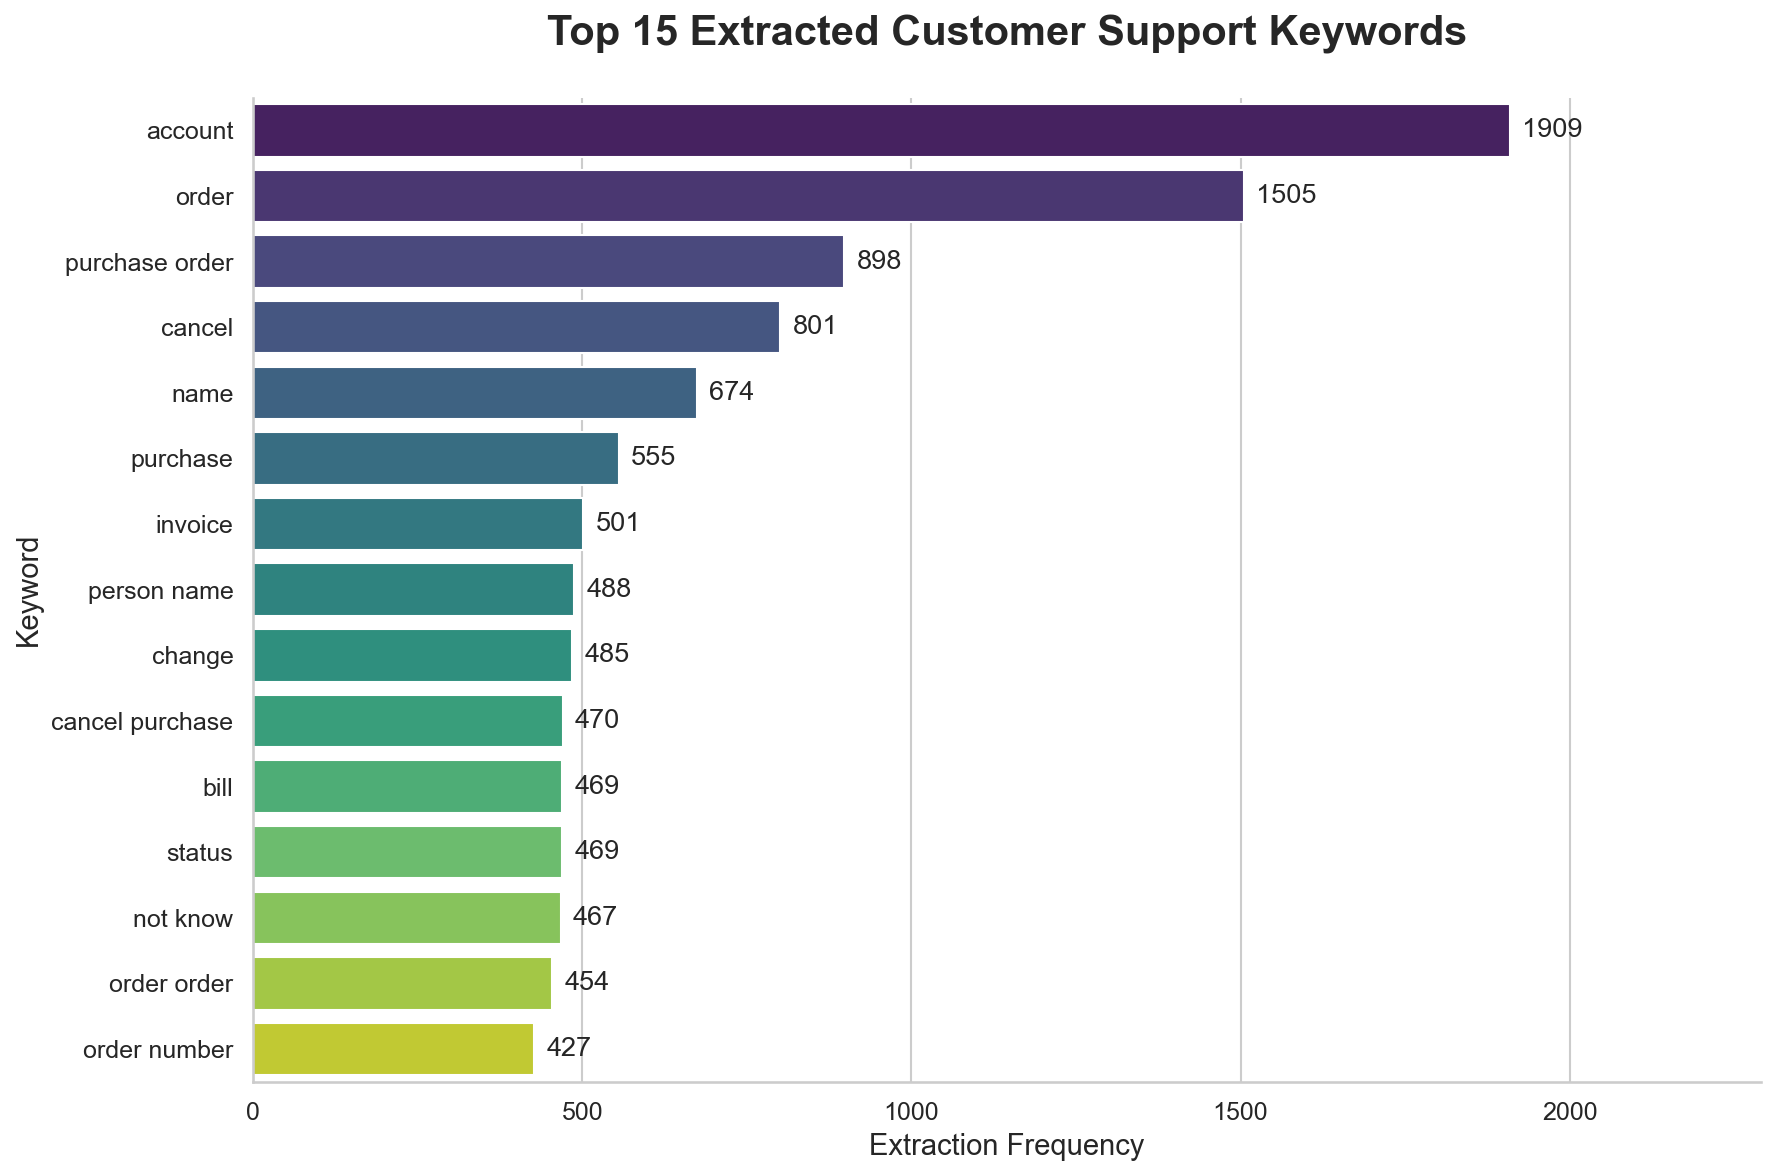

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize keyword vectorizer
keyword_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    token_pattern=r"(?u)\b[a-zA-Z]+\b"
)

# Generate TF-IDF matrix
keyword_matrix = keyword_vectorizer.fit_transform(
    df["processed_text"]
)

# Extract feature names
keyword_features = keyword_vectorizer.get_feature_names_out()

# Keyword extraction function
def extract_keywords(row_index, top_n=5):

    row = keyword_matrix.getrow(row_index)

    scores = list(zip(row.indices, row.data))

    scores = sorted(
        scores,
        key=lambda item: item[1],
        reverse=True
    )

    return [
        (keyword_features[index], round(float(score), 4))
        for index, score in scores[:top_n]
    ]


# Extract keywords for all customer queries
df["keywords"] = [
    extract_keywords(i)
    for i in range(len(df))
]

# Display sample results
print("========== TF-IDF KEYWORD EXTRACTION ==========")

display(
    df[["instruction", "keywords"]]
    .sample(10, random_state=42)
)

# Count extracted keyword frequencies
keyword_frequency = Counter(
    keyword
    for keywords in df["keywords"]
    for keyword, score in keywords
)

# Create frequency dataframe
keyword_df = pd.DataFrame(
    keyword_frequency.most_common(15),
    columns=["Keyword", "Frequency"]
)

print("\n========== TOP 15 EXTRACTED KEYWORDS ==========")

display(keyword_df)

# Summary statistics
print("\n========== KEYWORD STATISTICS ==========")

print("Total queries:", len(df))
print("Total available features:", len(keyword_features))
print("Unique extracted keywords:", len(keyword_frequency))

print(
    "Average keywords per query:",
    round(df["keywords"].apply(len).mean(), 2)
)

# Visualization
fig, ax = plt.subplots(figsize=(12, 8), dpi=150)

sns.barplot(
    data=keyword_df,
    x="Frequency",
    y="Keyword",
    hue="Keyword",
    palette="viridis",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=6,
        fontsize=13
    )

ax.set_title(
    "Top 15 Extracted Customer Support Keywords",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Extraction Frequency", fontsize=14)
ax.set_ylabel("Keyword", fontsize=14)

ax.tick_params(axis="both", labelsize=12)
ax.set_xlim(0, keyword_df["Frequency"].max() * 1.20)
ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

In [40]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.Collecting gensim
  Using cached gensim-4.4.0-cp311-cp311-win_amd64.whl.metadata (8.6 kB)
Using cached gensim-4.4.0-cp311-cp311-win_amd64.whl (24.4 MB)




[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\picka\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [41]:
import gensim
from gensim.models import Word2Vec

print("Gensim Version:", gensim.__version__)
print("Word2Vec imported successfully!")

Gensim Version: 4.4.0
Word2Vec imported successfully!


In [42]:
from gensim.models import Word2Vec

# Prepare tokenized customer queries
sentences = df["lemmatized_tokens"].tolist()

# Train CBOW model
cbow_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=0,
    epochs=15,
    seed=42
)

# Train Skip-gram model
skipgram_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    epochs=15,
    seed=42
)

# Model statistics
print("========== WORD2VEC STATISTICS ==========")

print("Total training documents:", len(sentences))
print("CBOW vocabulary size:", len(cbow_model.wv))
print("Skip-gram vocabulary size:", len(skipgram_model.wv))
print("Embedding dimensions:", cbow_model.vector_size)

# Display sample word embedding
print("\n========== SAMPLE WORD EMBEDDING ==========")

sample_vector = cbow_model.wv["refund"]

print("Word: refund")
print("Vector shape:", sample_vector.shape)
print("First 10 dimensions:")
print(sample_vector[:10].round(4))

# Compare similar words
target_words = [
    "order",
    "refund",
    "payment",
    "account",
    "delivery"
]

similarity_results = []

for word in target_words:

    if word in cbow_model.wv and word in skipgram_model.wv:

        cbow_similar = cbow_model.wv.most_similar(
            word, topn=5
        )

        skipgram_similar = skipgram_model.wv.most_similar(
            word, topn=5
        )

        similarity_results.append({
            "Word": word,
            "CBOW Similar Words": cbow_similar,
            "Skip-gram Similar Words": skipgram_similar
        })

similarity_df = pd.DataFrame(similarity_results)

print("\n========== CBOW VS SKIP-GRAM ==========")

display(similarity_df)

# Compare selected word pairs
word_pairs = [
    ("order", "purchase"),
    ("refund", "money"),
    ("payment", "pay"),
    ("customer", "service"),
    ("account", "password"),
    ("order", "password")
]

pair_results = []

for word1, word2 in word_pairs:

    if word1 in cbow_model.wv and word2 in cbow_model.wv:

        pair_results.append({
            "Word 1": word1,
            "Word 2": word2,
            "CBOW Similarity": round(
                float(cbow_model.wv.similarity(word1, word2)), 4
            ),
            "Skip-gram Similarity": round(
                float(skipgram_model.wv.similarity(word1, word2)), 4
            )
        })

word_similarity_df = pd.DataFrame(pair_results)

print("\n========== WORD SIMILARITY COMPARISON ==========")

display(word_similarity_df)

========== WORD2VEC STATISTICS ==========
Total training documents: 26872
CBOW vocabulary size: 1027
Skip-gram vocabulary size: 1027
Embedding dimensions: 100

========== SAMPLE WORD EMBEDDING ==========
Word: refund
Vector shape: (100,)
First 10 dimensions:
[-0.6762 -0.2298 -0.38   -0.3142 -1.1912 -0.4064  0.3489  0.4023 -0.7217
 -0.8663]

========== CBOW VS SKIP-GRAM ==========


,Word,CBOW Similar Words,Skip-gram Similar Words
0,order,"[(purchase, 0.875848114490509), (ordr, 0.7322750091552734), (afford, 0.6979722380638123), (number, 0.6754892468452454), (orer, 0.6619404554367065)]","[(purchase, 0.8528039455413818), (number, 0.8118331432342529), (purcahse, 0.6877393126487732), (ordr, 0.6851758360862732), (oredr, 0.6828684806823..."
1,refund,"[(reimbursement, 0.8760960102081299), (rebate, 0.8090915083885193), (reimburse, 0.7991645932197571), (compensation, 0.7912628054618835), (restitut...","[(reimbursement, 0.8377031683921814), (reimburse, 0.8234671950340271), (reufnd, 0.814923882484436), (ofv, 0.8126877546310425), (reimbursmeent, 0.8..."
2,payment,"[(registration, 0.7774373888969421), (pamyent, 0.7503765225410461), (paymnet, 0.7031576633453369), (paymeny, 0.6562319993972778), (signup, 0.65311...","[(paymeny, 0.8046478629112244), (registration, 0.8008869886398315), (paymnet, 0.7899671792984009), (pamyent, 0.7892801761627197), (paymnt, 0.77075..."
3,account,"[(acount, 0.8362096548080444), (cacount, 0.8257591724395752), (acconut, 0.8029550909996033), (profile, 0.7720743417739868), (acocunt, 0.7549626827...","[(cacount, 0.9023335576057434), (acount, 0.895130455493927), (acconut, 0.8580464720726013), (acocunt, 0.8397111296653748), (accountfor, 0.83758533..."
4,delivery,"[(shipping, 0.8784996867179871), (ship, 0.802280843257904), (shipment, 0.7030630707740784), (deilvery, 0.6923553347587585), (deliver, 0.6620979905...","[(shipping, 0.8011462688446045), (ship, 0.7723165154457092), (shipment, 0.7309522032737732), (hsipping, 0.6701361536979675), (deilvery, 0.66463434..."



========== WORD SIMILARITY COMPARISON ==========


,Word 1,Word 2,CBOW Similarity,Skip-gram Similarity
0,order,purchase,0.8758,0.8528
1,refund,money,0.5822,0.7080
2,payment,pay,0.1854,0.2890
3,customer,service,0.4582,0.6076
4,account,password,0.3705,0.5256
5,order,password,-0.1561,0.1685


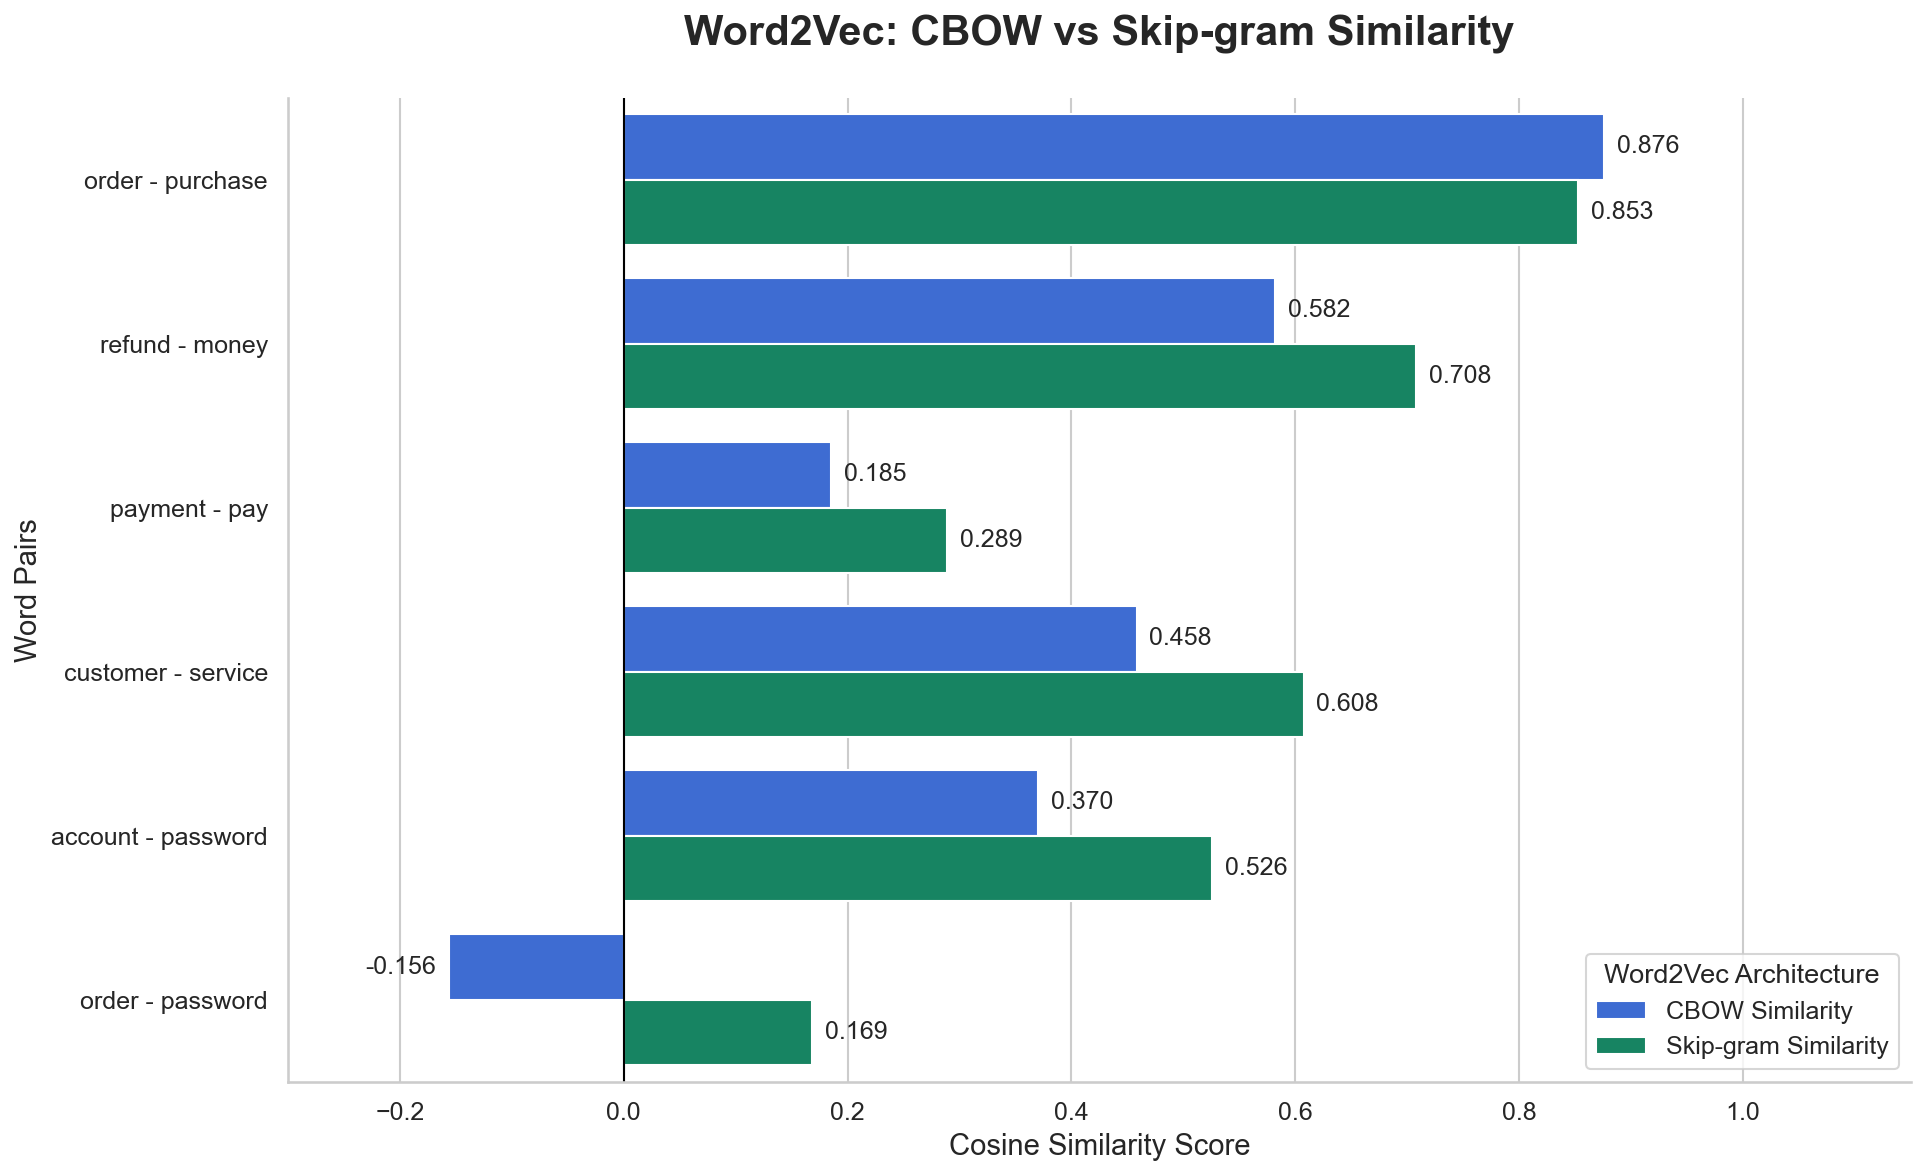

In [43]:
# Prepare word pair labels
word_similarity_df["Word Pair"] = (
    word_similarity_df["Word 1"] +
    " - " +
    word_similarity_df["Word 2"]
)

# Reshape dataframe for visualization
similarity_plot_df = word_similarity_df.melt(
    id_vars="Word Pair",
    value_vars=[
        "CBOW Similarity",
        "Skip-gram Similarity"
    ],
    var_name="Model",
    value_name="Cosine Similarity"
)

# Create visualization
fig, ax = plt.subplots(figsize=(13, 8), dpi=150)

sns.barplot(
    data=similarity_plot_df,
    x="Cosine Similarity",
    y="Word Pair",
    hue="Model",
    palette=["#2563EB", "#059669"],
    ax=ax
)

# Display similarity scores
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=6,
        fontsize=12
    )

# Zero reference line
ax.axvline(
    0,
    color="black",
    linewidth=1
)

# Chart formatting
ax.set_title(
    "Word2Vec: CBOW vs Skip-gram Similarity",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Cosine Similarity Score", fontsize=14)
ax.set_ylabel("Word Pairs", fontsize=14)

ax.set_xlim(-0.30, 1.15)

ax.tick_params(axis="both", labelsize=12)

ax.legend(
    title="Word2Vec Architecture",
    fontsize=12,
    title_fontsize=13,
    loc="lower right"
)

ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

INPUT QUERY: I want to cancel my order


,instruction,category,intent,Similarity Score
0,I want to cancel order {{Order Number}},ORDER,cancel_order,0.8763
1,cancelling order,ORDER,cancel_order,0.8490
2,canceling order,ORDER,cancel_order,0.8490
3,cancel order,ORDER,cancel_order,0.8490
4,i want help canceling order {{Order Number}},ORDER,cancel_order,0.8429


INPUT QUERY: I forgot my account password


,instruction,category,intent,Similarity Score
0,"I forgot my account password, how t reset it?",ACCOUNT,recover_password,0.8832
1,"I forgot my user password, help me to reset it",ACCOUNT,recover_password,0.7643
2,"I forgot the bloody key of my account, where to retrieve it?",ACCOUNT,recover_password,0.5436
3,"I have forgotten my user account key, help to restore it",ACCOUNT,recover_password,0.5404
4,"I have forgotten my PIN, could I reset it?",ACCOUNT,recover_password,0.5163


INPUT QUERY: How can I get my money back?


,instruction,category,intent,Similarity Score
0,get money back,REFUND,get_refund,1.0000
1,getting money back,REFUND,get_refund,1.0000
2,help to get my money back,REFUND,get_refund,0.9601
3,want help to get my money back,REFUND,get_refund,0.9032
4,want assistance to get my money back,REFUND,get_refund,0.8822


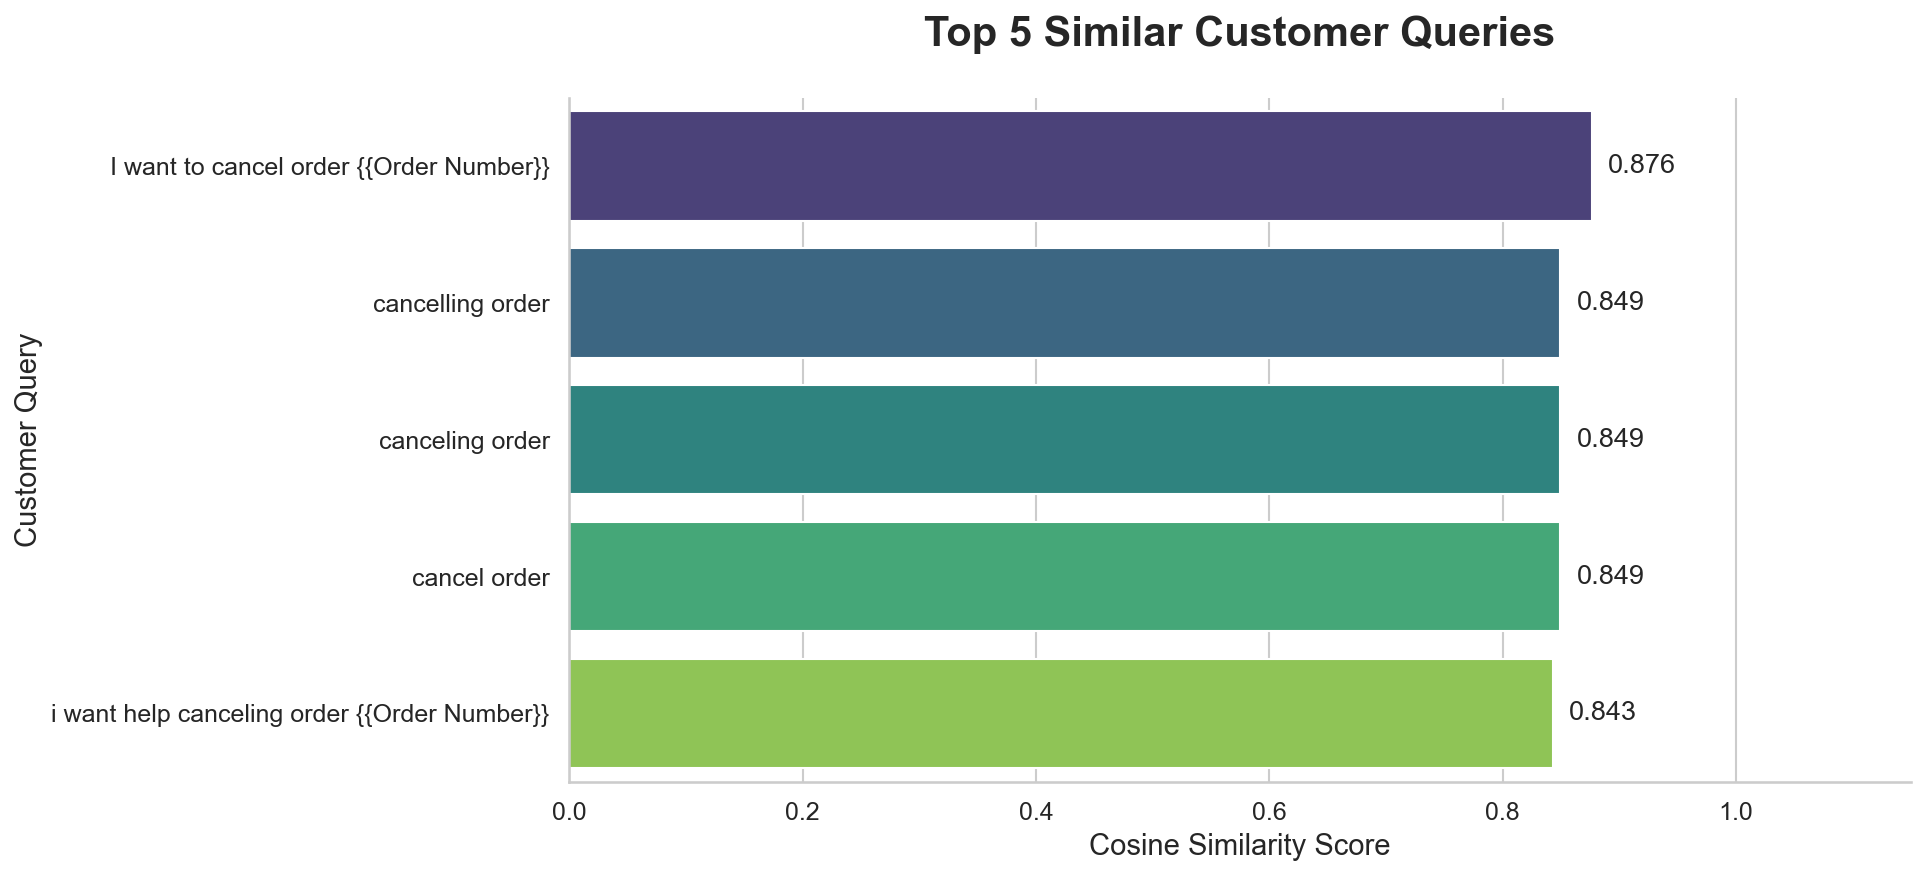

In [44]:
from sklearn.metrics.pairwise import cosine_similarity

# Function to preprocess new customer queries
def preprocess_query(text):

    cleaned = clean_text(text)

    tokens = word_tokenize(cleaned)

    tokens = apply_lemmatization(tokens)

    tokens = remove_stopwords(tokens)

    return " ".join(tokens)


# Find similar customer queries
def find_similar_queries(query, top_n=5):

    processed_query = preprocess_query(query)

    # Transform query using existing TF-IDF vectorizer
    query_vector = tfidf_vectorizer.transform(
        [processed_query]
    )

    # Calculate similarity with all customer queries
    scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    ).flatten()

    # Rank queries by similarity
    ranked_indices = np.argsort(-scores)

    results = df.iloc[ranked_indices][
        ["instruction", "category", "intent"]
    ].copy()

    results["Similarity Score"] = scores[ranked_indices]

    # Exclude zero-similarity results and repeated queries
    results = results[
        results["Similarity Score"] > 0
    ]

    results = results.drop_duplicates(
        subset="instruction"
    )

    return results.head(top_n).reset_index(drop=True)


# Test customer queries
test_queries = [
    "I want to cancel my order",
    "I forgot my account password",
    "How can I get my money back?"
]

# Display similar queries
for query in test_queries:

    print("=" * 70)
    print("INPUT QUERY:", query)
    print("=" * 70)

    display(
        find_similar_queries(query, top_n=5).round(4)
    )


# Visualize query similarity
selected_query = "I want to cancel my order"

similar_queries = find_similar_queries(
    selected_query,
    top_n=5
)

fig, ax = plt.subplots(figsize=(13, 6), dpi=150)

sns.barplot(
    data=similar_queries,
    x="Similarity Score",
    y="instruction",
    hue="instruction",
    palette="viridis",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=8,
        fontsize=13
    )

ax.set_title(
    "Top 5 Similar Customer Queries",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Cosine Similarity Score", fontsize=14)
ax.set_ylabel("Customer Query", fontsize=14)

ax.set_xlim(0, 1.15)
ax.tick_params(axis="both", labelsize=12)
ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

In [45]:
from nltk.sentiment import SentimentIntensityAnalyzer

# Initialize VADER sentiment analyzer
sia = SentimentIntensityAnalyzer()

# Calculate sentiment scores using original text
sentiment_scores = df["instruction"].apply(
    sia.polarity_scores
)

# Convert sentiment scores into dataframe
sentiment_scores_df = pd.DataFrame(
    sentiment_scores.tolist(),
    index=df.index
)

# Store sentiment scores
df["positive_score"] = sentiment_scores_df["pos"]
df["negative_score"] = sentiment_scores_df["neg"]
df["neutral_score"] = sentiment_scores_df["neu"]
df["compound_score"] = sentiment_scores_df["compound"]

# Sentiment classification function
def classify_sentiment(score):

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


# Assign sentiment labels
df["sentiment"] = df["compound_score"].apply(
    classify_sentiment
)

# Display sample results
print("========== SENTIMENT ANALYSIS RESULTS ==========")

display(
    df[
        [
            "instruction",
            "positive_score",
            "negative_score",
            "neutral_score",
            "compound_score",
            "sentiment"
        ]
    ].sample(15, random_state=42)
)

# Sentiment distribution
sentiment_counts = df["sentiment"].value_counts()

sentiment_df = sentiment_counts.rename_axis(
    "Sentiment"
).reset_index(name="Count")

sentiment_df["Percentage"] = (
    sentiment_df["Count"] / len(df) * 100
).round(2)

print("\n========== SENTIMENT DISTRIBUTION ==========")

display(sentiment_df)

# Test negation handling
test_sentiments = [
    "The customer service is good.",
    "The customer service is not good.",
    "I am very happy with my order!",
    "I am extremely disappointed with the service.",
    "Where is my order?",
    "I want to request a refund."
]

sentiment_test_df = pd.DataFrame([
    {
        "Text": text,
        "Compound Score": sia.polarity_scores(text)["compound"],
        "Sentiment": classify_sentiment(
            sia.polarity_scores(text)["compound"]
        )
    }
    for text in test_sentiments
])

print("\n========== SENTIMENT VALIDATION ==========")

display(sentiment_test_df)

========== SENTIMENT ANALYSIS RESULTS ==========


,instruction,positive_score,negative_score,neutral_score,compound_score,sentiment
9329,I can't talk with a human agent,0.000,0.000,1.000,0.0000,Neutral
4160,I have got to locate hte bills from {{Person Name}},0.000,0.000,1.000,0.0000,Neutral
18500,"I cannot pay, help me to inform of a problem with payments",0.098,0.374,0.528,-0.5664,Negative
8840,I want help speaking to customer service,0.500,0.000,0.500,0.4588,Positive
5098,I try to see th accepted payment options,0.259,0.000,0.741,0.2732,Positive
17250,where to sign up to the company nmewsletter,0.000,0.000,1.000,0.0000,Neutral
3589,I'd like to see the withdrwaal fee how can i do it,0.200,0.000,0.800,0.3612,Positive
9043,I want to speak with someone,0.245,0.000,0.755,0.0772,Positive
15800,can you help me getting bill #85632?,0.310,0.000,0.690,0.4019,Positive
4384,I don't know how to take a quick look at invoice #12588,0.000,0.000,1.000,0.0000,Neutral



========== SENTIMENT DISTRIBUTION ==========


,Sentiment,Count,Percentage
0,Neutral,14429,53.70
1,Positive,8310,30.92
2,Negative,4133,15.38



========== SENTIMENT VALIDATION ==========


,Text,Compound Score,Sentiment
0,The customer service is good.,0.4404,Positive
1,The customer service is not good.,-0.3412,Negative
2,I am very happy with my order!,0.6468,Positive
3,I am extremely disappointed with the service.,-0.5256,Negative
4,Where is my order?,0.0000,Neutral
5,I want to request a refund.,0.0772,Positive


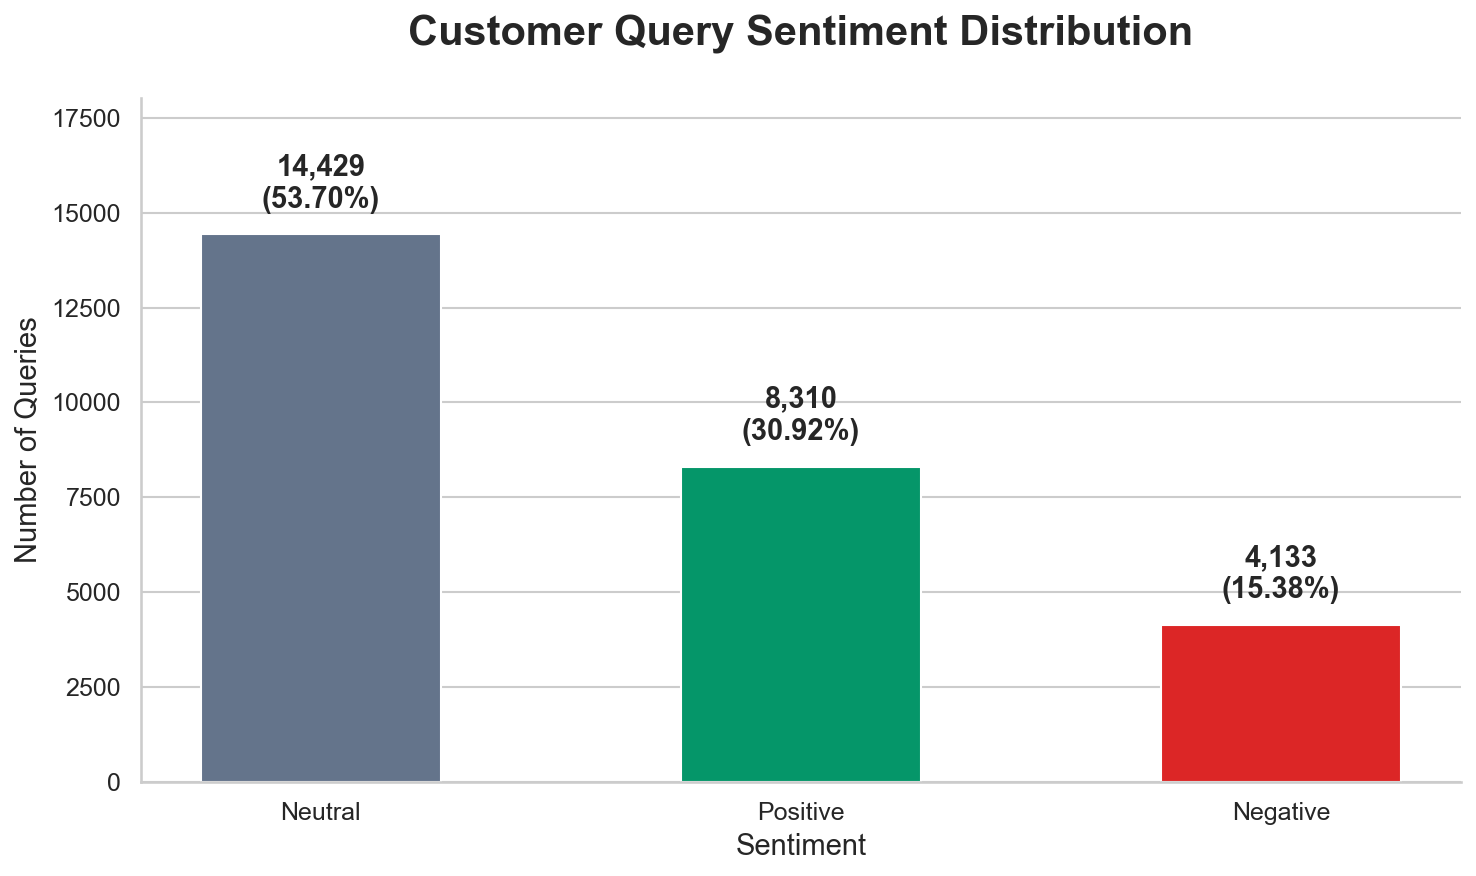

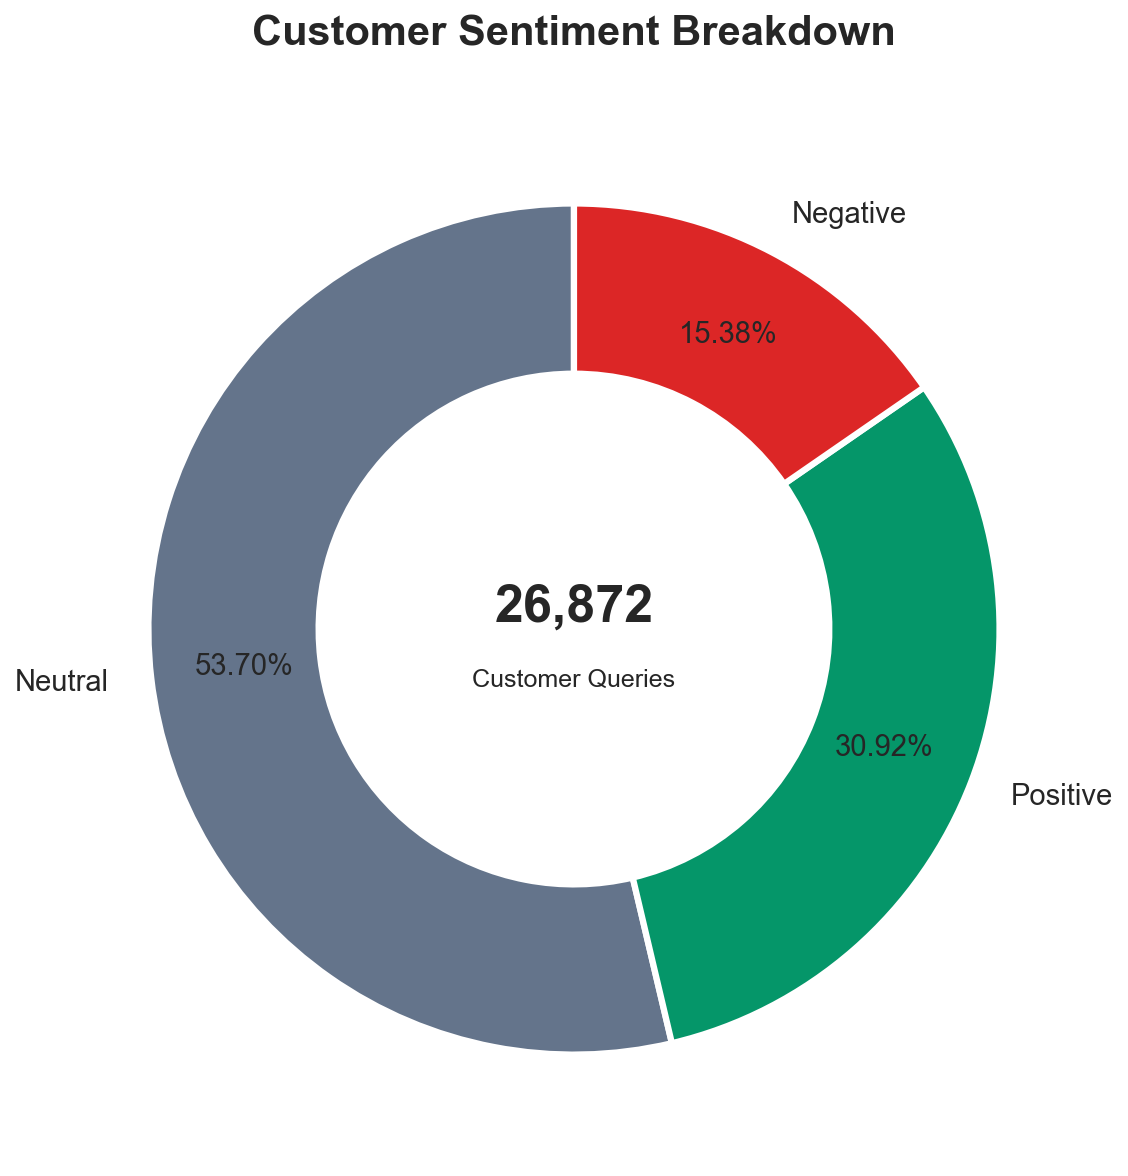

In [46]:
# Define sentiment colors
sentiment_colors = {
    "Positive": "#059669",
    "Neutral": "#64748B",
    "Negative": "#DC2626"
}

# Chart 1: Sentiment distribution
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

bars = ax.bar(
    sentiment_df["Sentiment"],
    sentiment_df["Count"],
    color=[
        sentiment_colors[s]
        for s in sentiment_df["Sentiment"]
    ],
    width=0.5
)

bar_labels = [
    f"{count:,}\n({percentage:.2f}%)"
    for count, percentage in zip(
        sentiment_df["Count"],
        sentiment_df["Percentage"]
    )
]

ax.bar_label(
    bars,
    labels=bar_labels,
    padding=10,
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "Customer Query Sentiment Distribution",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Sentiment", fontsize=14)
ax.set_ylabel("Number of Queries", fontsize=14)

ax.set_ylim(0, sentiment_df["Count"].max() * 1.25)
ax.tick_params(axis="both", labelsize=12)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()


# Chart 2: Sentiment percentage distribution
fig, ax = plt.subplots(figsize=(9, 8), dpi=150)

ax.pie(
    sentiment_df["Count"],
    labels=sentiment_df["Sentiment"],
    colors=[
        sentiment_colors[s]
        for s in sentiment_df["Sentiment"]
    ],
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.40,
        "edgecolor": "white",
        "linewidth": 3
    },
    textprops={
        "fontsize": 14,
        "fontweight": "medium"
    }
)

# Center text
ax.text(
    0, 0.05,
    f"{len(df):,}",
    ha="center",
    va="center",
    fontsize=25,
    fontweight="bold"
)

ax.text(
    0, -0.12,
    "Customer Queries",
    ha="center",
    va="center",
    fontsize=12
)

ax.set_title(
    "Customer Sentiment Breakdown",
    fontsize=20,
    fontweight="bold",
    pad=25
)

plt.tight_layout()
plt.show()

In [47]:
%pip install transformers torch


  Using cached torch-2.15.0-cp311-cp311-win_amd64.whl.metadata (36 kB)
  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
  Using cached regex-2026.11.24-cp311-cp311-win_amd64.whl.metadata (41 kB)
  Using cached tokenizers-0.23.3-cp310-abi3-win_amd64.whl.metadata (10 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.8.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.2-py3-none-any.whl.metadata (10.0 kB)
  Using cached anyio-4.16.0-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore2-2.16.2-py3-none-any.whl.metadata (28 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata (4.5 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
chainlit 2.6.2 requires python-multipart<0.0.19,>=0.0.18, but you have python-multipart 0.0.20 which is incompatible.
nicegui 3.9.0 requires pydantic-core>=2.35.0, but you have pydantic-core 2.33.1 which is incompatible.
nicegui 3.9.0 requires python-multipart>=0.0.22, but you have python-multipart 0.0.20 which is incompatible.
nicegui 3.9.0 requires starlette>=0.49.1, but you have starlette 0.46.2 which is incompatible.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\picka\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ---------------------------------  3/18 [sympy]
   ------ ----

In [48]:
import torch
import transformers

print("PyTorch Version:", torch.__version__)
print("Transformers Version:", transformers.__version__)
print("GPU Available:", torch.cuda.is_available())

PyTorch Version: 2.15.0+cpu
Transformers Version: 5.24.1
GPU Available: False


In [49]:
from transformers import pipeline
import torch

# Load pretrained emotion detection model
emotion_classifier = pipeline(
    task="text-classification",
    model="j-hartmann/emotion-english-distilroberta-base",
    device=-1
)

print("Emotion detection model loaded successfully!")

# Select 1,000 customer queries
emotion_sample = df.sample(
    n=1000,
    random_state=42
).copy()

# Generate emotion predictions
emotion_results = emotion_classifier(
    emotion_sample["instruction"].tolist(),
    batch_size=16,
    truncation=True,
    max_length=128
)

# Store predicted emotions
emotion_sample["emotion"] = [
    result["label"]
    for result in emotion_results
]

emotion_sample["emotion_score"] = [
    result["score"]
    for result in emotion_results
]

# Display sample predictions
print("\n========== EMOTION DETECTION RESULTS ==========")

display(
    emotion_sample[
        ["instruction", "sentiment", "emotion", "emotion_score"]
    ].head(15).round(4)
)

# Calculate emotion distribution
emotion_df = emotion_sample["emotion"].value_counts().rename_axis(
    "Emotion"
).reset_index(name="Count")

emotion_df["Percentage"] = (
    emotion_df["Count"] / len(emotion_sample) * 100
).round(2)

print("\n========== EMOTION DISTRIBUTION ==========")

display(emotion_df)

print("\n========== EMOTION STATISTICS ==========")

print("Total analyzed queries:", len(emotion_sample))
print("Unique predicted emotions:", emotion_sample["emotion"].nunique())

print(
    "Average model confidence:",
    round(emotion_sample["emotion_score"].mean(), 4)
)

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

C:\Users\picka\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\picka\.cache\huggingface\hub\models--j-hartmann--emotion-english-distilroberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

... (7 outputs left out)

,instruction,sentiment,emotion,emotion_score
9329,I can't talk with a human agent,Neutral,sadness,0.3674
4160,I have got to locate hte bills from {{Person Name}},Neutral,neutral,0.8672
18500,"I cannot pay, help me to inform of a problem with payments",Negative,sadness,0.6218
8840,I want help speaking to customer service,Positive,sadness,0.5186
5098,I try to see th accepted payment options,Positive,neutral,0.7722
17250,where to sign up to the company nmewsletter,Neutral,neutral,0.9167
3589,I'd like to see the withdrwaal fee how can i do it,Positive,neutral,0.6380
9043,I want to speak with someone,Positive,disgust,0.3597
15800,can you help me getting bill #85632?,Positive,neutral,0.8420
4384,I don't know how to take a quick look at invoice #12588,Neutral,surprise,0.4911



========== EMOTION DISTRIBUTION ==========


,Emotion,Count,Percentage
0,neutral,577,57.7
1,sadness,272,27.2
2,anger,75,7.5
3,surprise,37,3.7
4,fear,18,1.8
5,joy,16,1.6
6,disgust,5,0.5



========== EMOTION STATISTICS ==========
Total analyzed queries: 1000
Unique predicted emotions: 7
Average model confidence: 0.7042


In [50]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel

# Remove numerical tokens and generic support words
topic_stopwords = {
    "help", "want", "need", "assistance",
    "please", "know", "get", "see", "try",
    "would", "like", "person", "name"
}

# Prepare documents for topic modeling
topic_tokens = [
    [
        word for word in tokens
        if word.isalpha()
        and word not in topic_stopwords
        and len(word) > 2
    ]
    for tokens in df["lemmatized_tokens"]
]

# Create Gensim dictionary
lda_dictionary = Dictionary(topic_tokens)

# Remove extremely rare and common words
lda_dictionary.filter_extremes(
    no_below=5,
    no_above=0.5
)

# Create Bag of Words corpus
lda_corpus = [
    lda_dictionary.doc2bow(tokens)
    for tokens in topic_tokens
]

# Train LDA model
lda_model = LdaModel(
    corpus=lda_corpus,
    id2word=lda_dictionary,
    num_topics=5,
    random_state=42,
    passes=10,
    iterations=100,
    alpha="auto",
    per_word_topics=False
)

print("========== LDA MODEL STATISTICS ==========")

print("Total documents:", len(lda_corpus))
print("Dictionary size:", len(lda_dictionary))
print("Number of topics:", lda_model.num_topics)

# Extract top words from each topic
topic_results = []

for topic_id in range(lda_model.num_topics):

    topic_words = lda_model.show_topic(
        topic_id,
        topn=10
    )

    topic_results.append({
        "Topic": f"Topic {topic_id + 1}",
        "Top Keywords": ", ".join(
            word for word, weight in topic_words
        )
    })

lda_topics_df = pd.DataFrame(topic_results)

print("\n========== DISCOVERED TOPICS ==========")

display(lda_topics_df)

# Assign dominant topic to each non-empty document
dominant_topics = []
topic_probabilities = []

for document in lda_corpus:

    if not document:
        dominant_topics.append(None)
        topic_probabilities.append(np.nan)
        continue

    distribution = lda_model.get_document_topics(
        document,
        minimum_probability=0
    )

    topic_id, probability = max(
        distribution,
        key=lambda item: item[1]
    )

    dominant_topics.append(
        f"Topic {topic_id + 1}"
    )

    topic_probabilities.append(
        round(float(probability), 4)
    )

df["dominant_topic"] = dominant_topics
df["topic_probability"] = topic_probabilities

# Display sample topic assignments
print("\n========== SAMPLE TOPIC ASSIGNMENTS ==========")

display(
    df[
        [
            "instruction",
            "dominant_topic",
            "topic_probability"
        ]
    ].sample(10, random_state=42)
)

# Topic distribution
lda_topic_distribution = (
    df["dominant_topic"]
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Count")
)

print("\n========== TOPIC DISTRIBUTION ==========")

display(lda_topic_distribution)

print(
    "Unassigned empty documents:",
    df["dominant_topic"].isna().sum()
)

# Evaluate topic coherence
coherence_model = CoherenceModel(
    model=lda_model,
    texts=topic_tokens,
    dictionary=lda_dictionary,
    coherence="c_v",
    processes=1
)

coherence_score = coherence_model.get_coherence()

print("\n========== TOPIC MODEL EVALUATION ==========")

print(f"Coherence Score: {coherence_score:.4f}")

========== LDA MODEL STATISTICS ==========
Total documents: 26872
Dictionary size: 432
Number of topics: 5

========== DISCOVERED TOPICS ==========


,Topic,Top Keywords
0,Topic 1,"order, number, purchase, product, profile, user, eta, not, pin, article"
1,Topic 2,"refund, status, amount, symbol, currency, rebate, expect, restitution, payment, current"
2,Topic 3,"account, problem, type, change, use, new, category, sign, not, switch"
3,Topic 4,"address, shipping, feedback, set, submit, newsletter, service, leave, company, enter"
4,Topic 5,"check, delivery, issue, error, not, anything, update, send, signup, bill"



========== SAMPLE TOPIC ASSIGNMENTS ==========


,instruction,dominant_topic,topic_probability
9329,I can't talk with a human agent,Topic 3,0.6284
4160,I have got to locate hte bills from {{Person Name}},Topic 5,0.8935
18500,"I cannot pay, help me to inform of a problem with payments",Topic 2,0.6691
8840,I want help speaking to customer service,Topic 4,0.8830
5098,I try to see th accepted payment options,Topic 2,0.8918
17250,where to sign up to the company nmewsletter,Topic 3,0.4388
3589,I'd like to see the withdrwaal fee how can i do it,Topic 5,0.7501
9043,I want to speak with someone,Topic 4,0.8360
15800,can you help me getting bill #85632?,Topic 5,0.7501
4384,I don't know how to take a quick look at invoice #12588,Topic 5,0.9324



========== TOPIC DISTRIBUTION ==========


,Topic,Count
0,Topic 5,6005
1,Topic 1,5900
2,Topic 4,5409
3,Topic 2,4829
4,Topic 3,4689


Unassigned empty documents: 40

========== TOPIC MODEL EVALUATION ==========
Coherence Score: 0.3957


========== NAMED TOPIC DISTRIBUTION ==========


,Topic,Count,Topic Name,Percentage
0,Topic 5,6005,"Delivery, Billing & Technical Issues",22.38
1,Topic 1,5900,Order & Product Management,21.99
2,Topic 4,5409,Shipping & Customer Feedback,20.16
3,Topic 2,4829,Refund & Payment Services,18.00
4,Topic 3,4689,Account Management,17.48


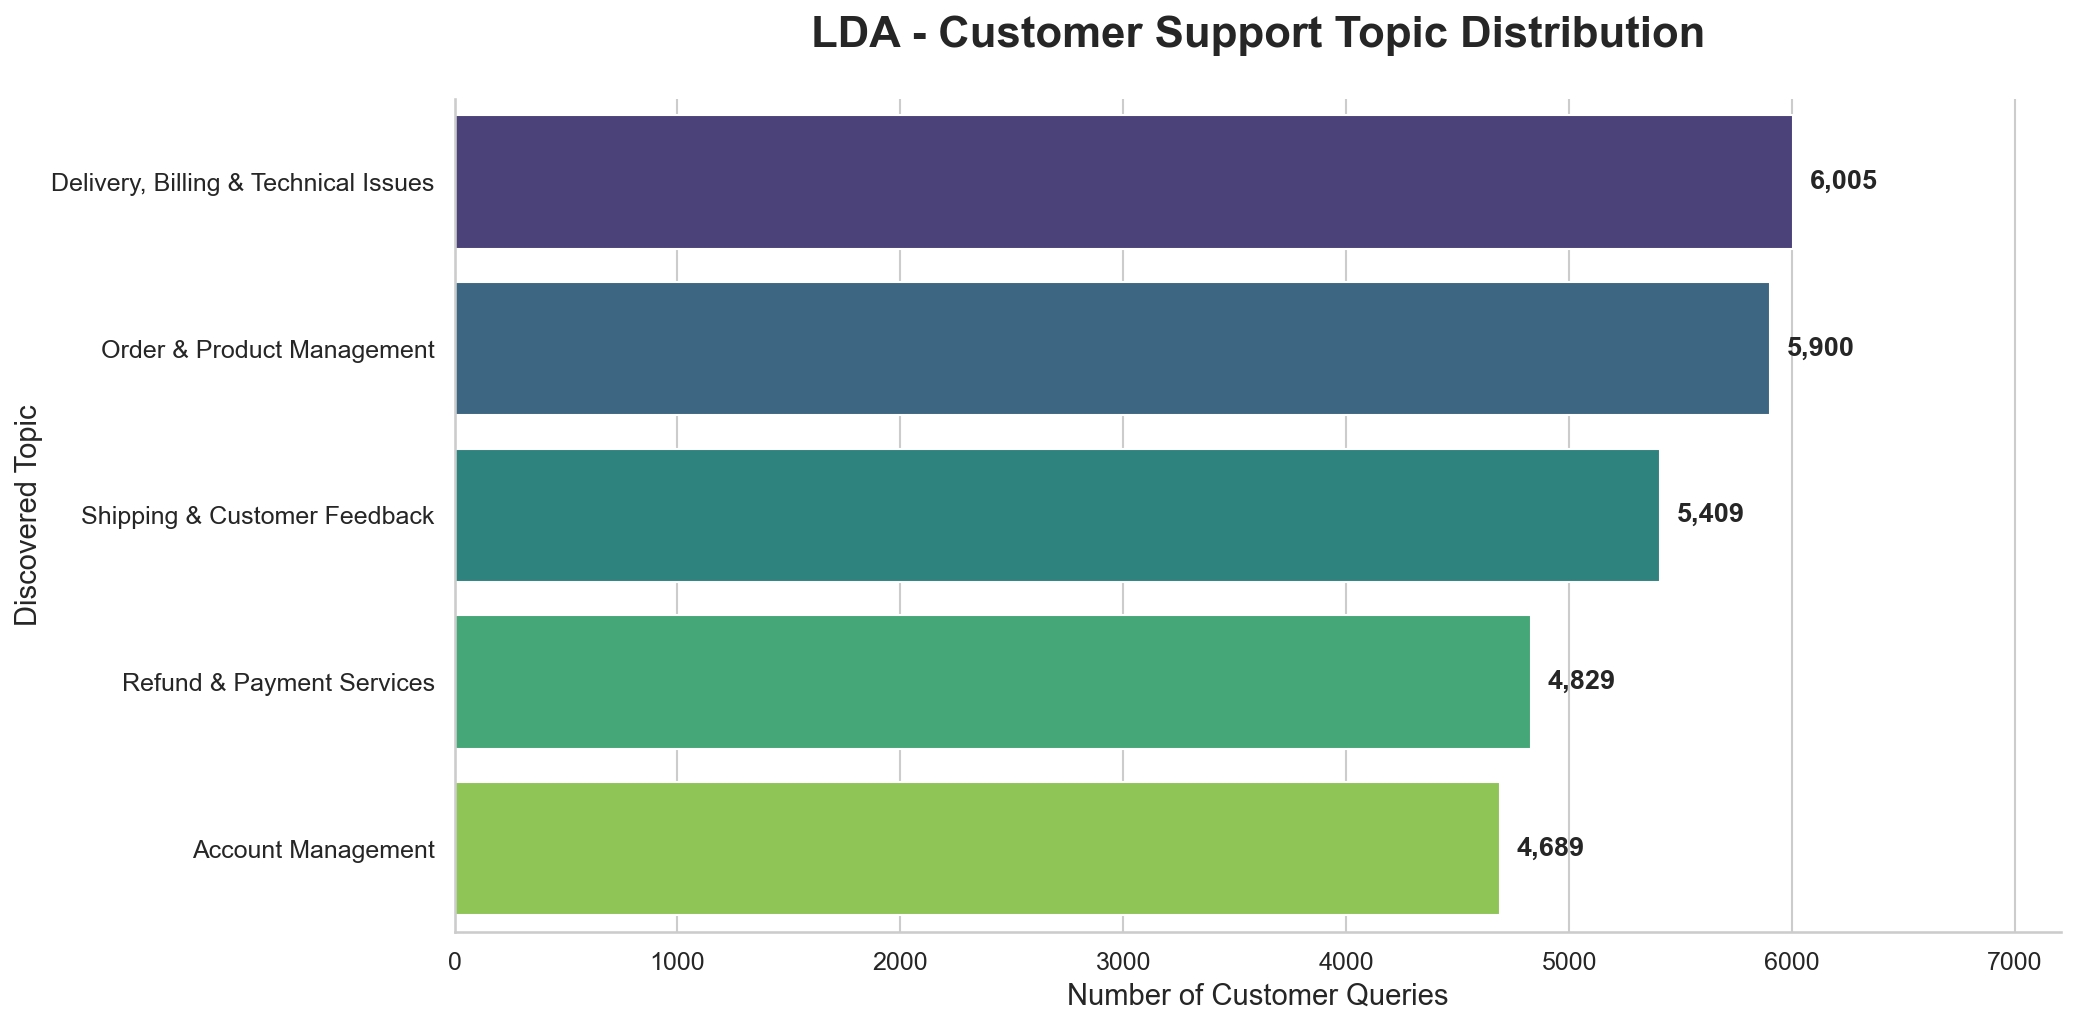

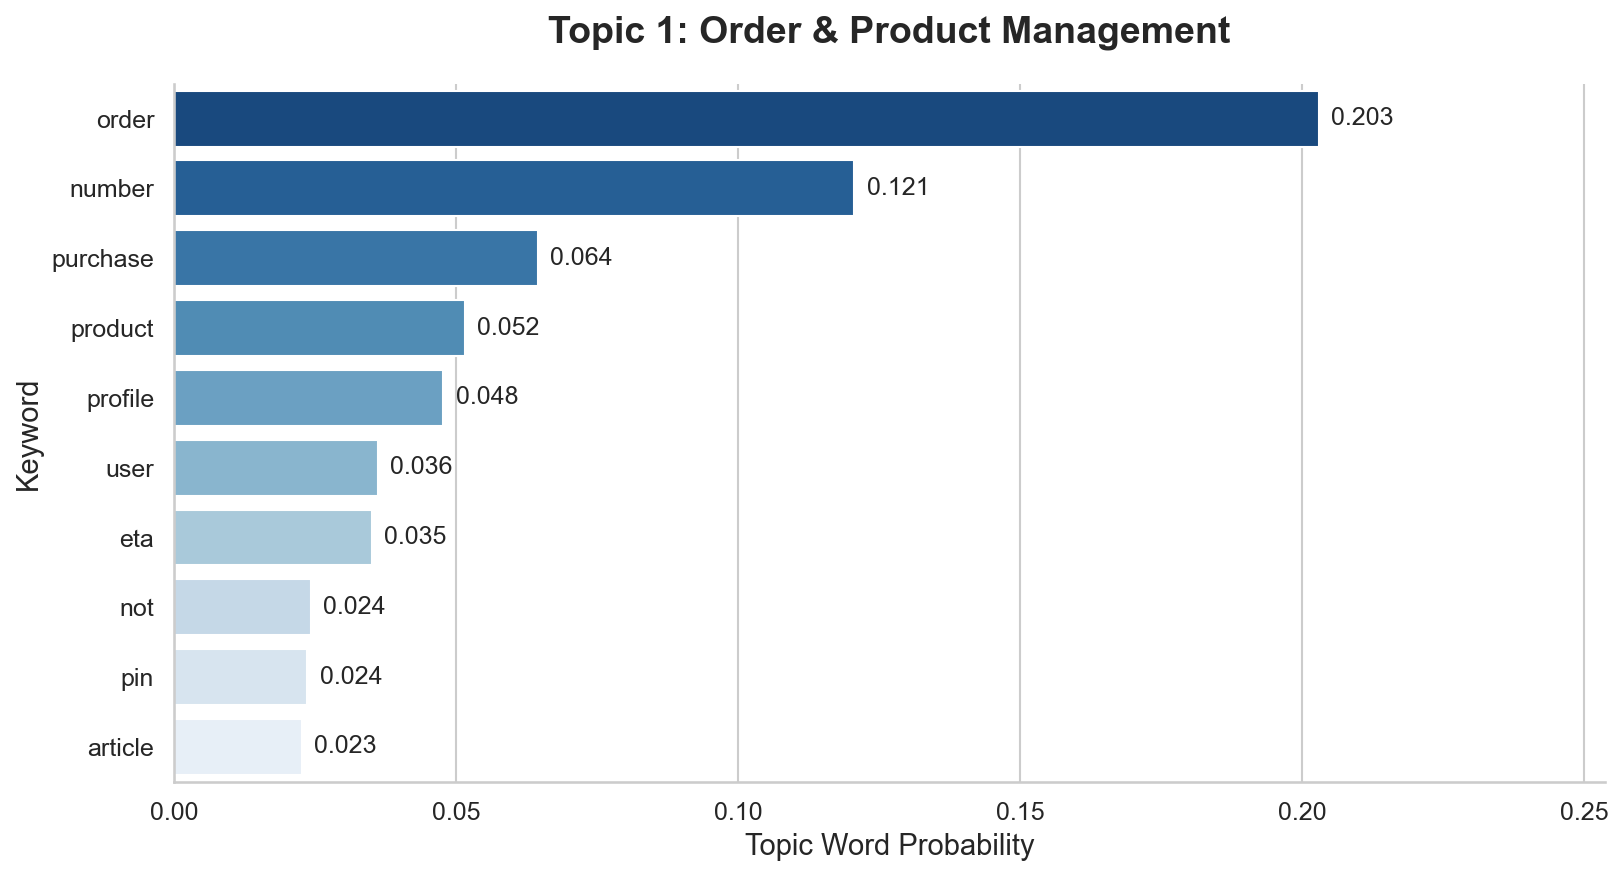

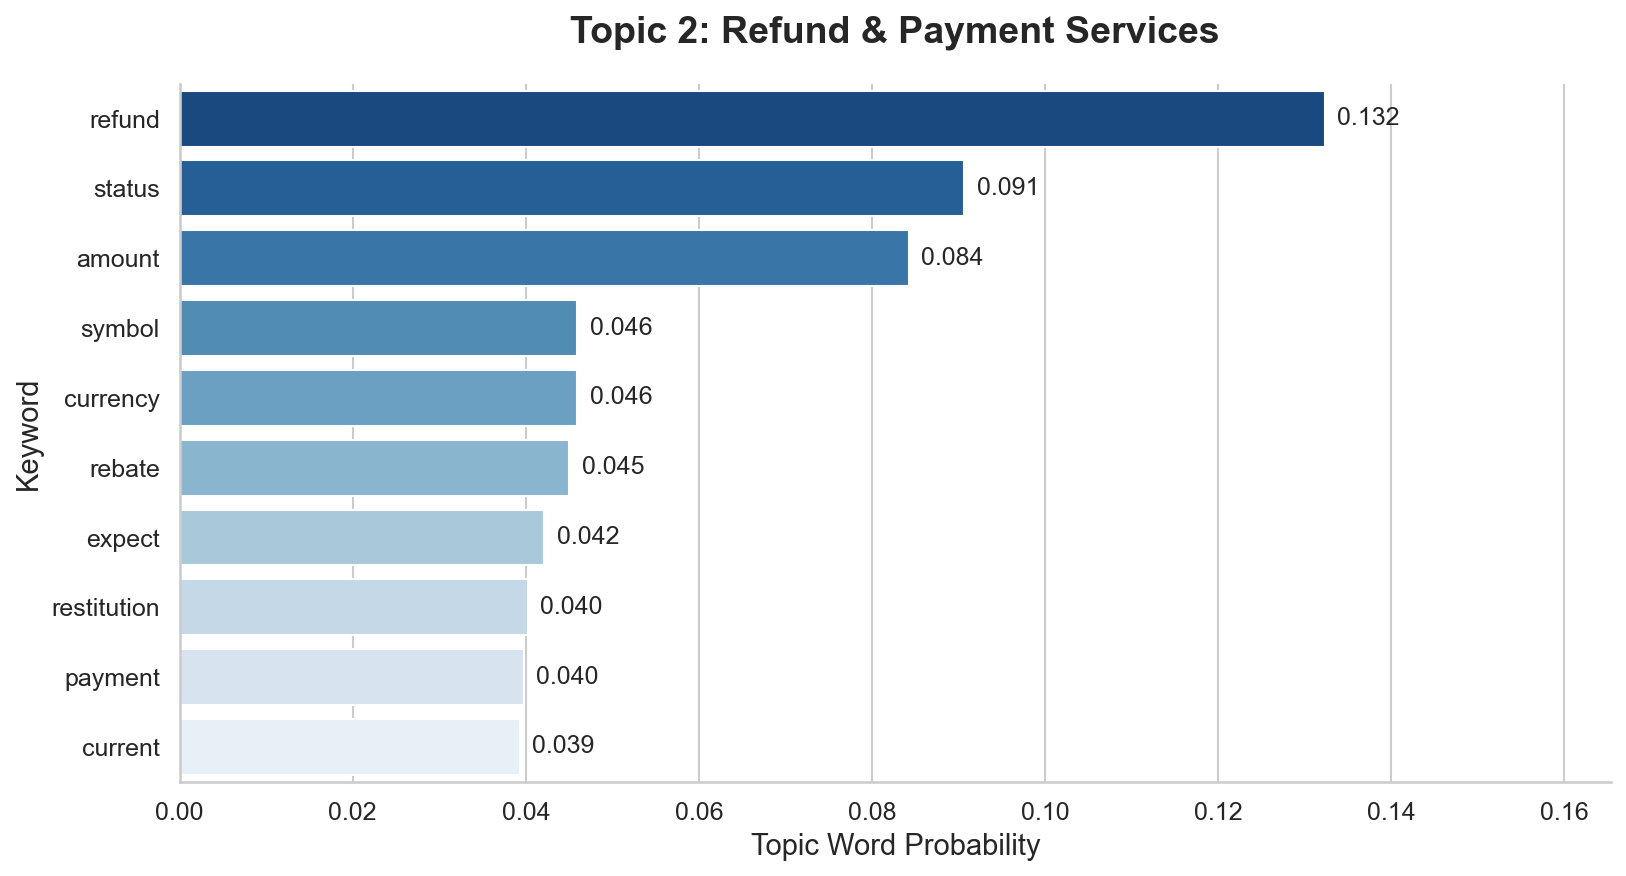

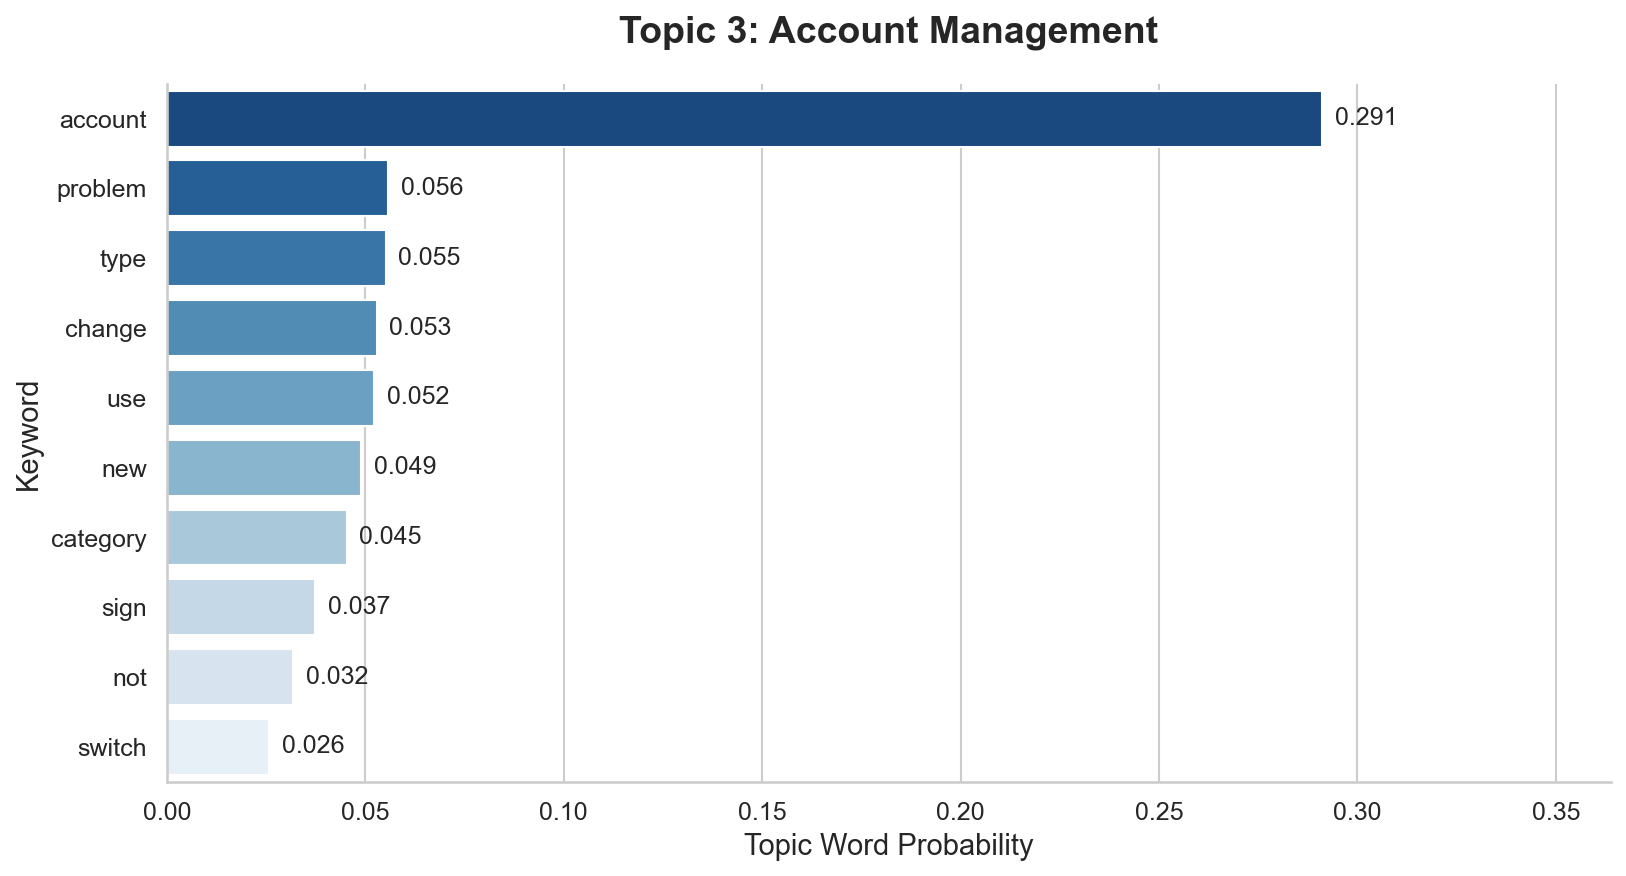

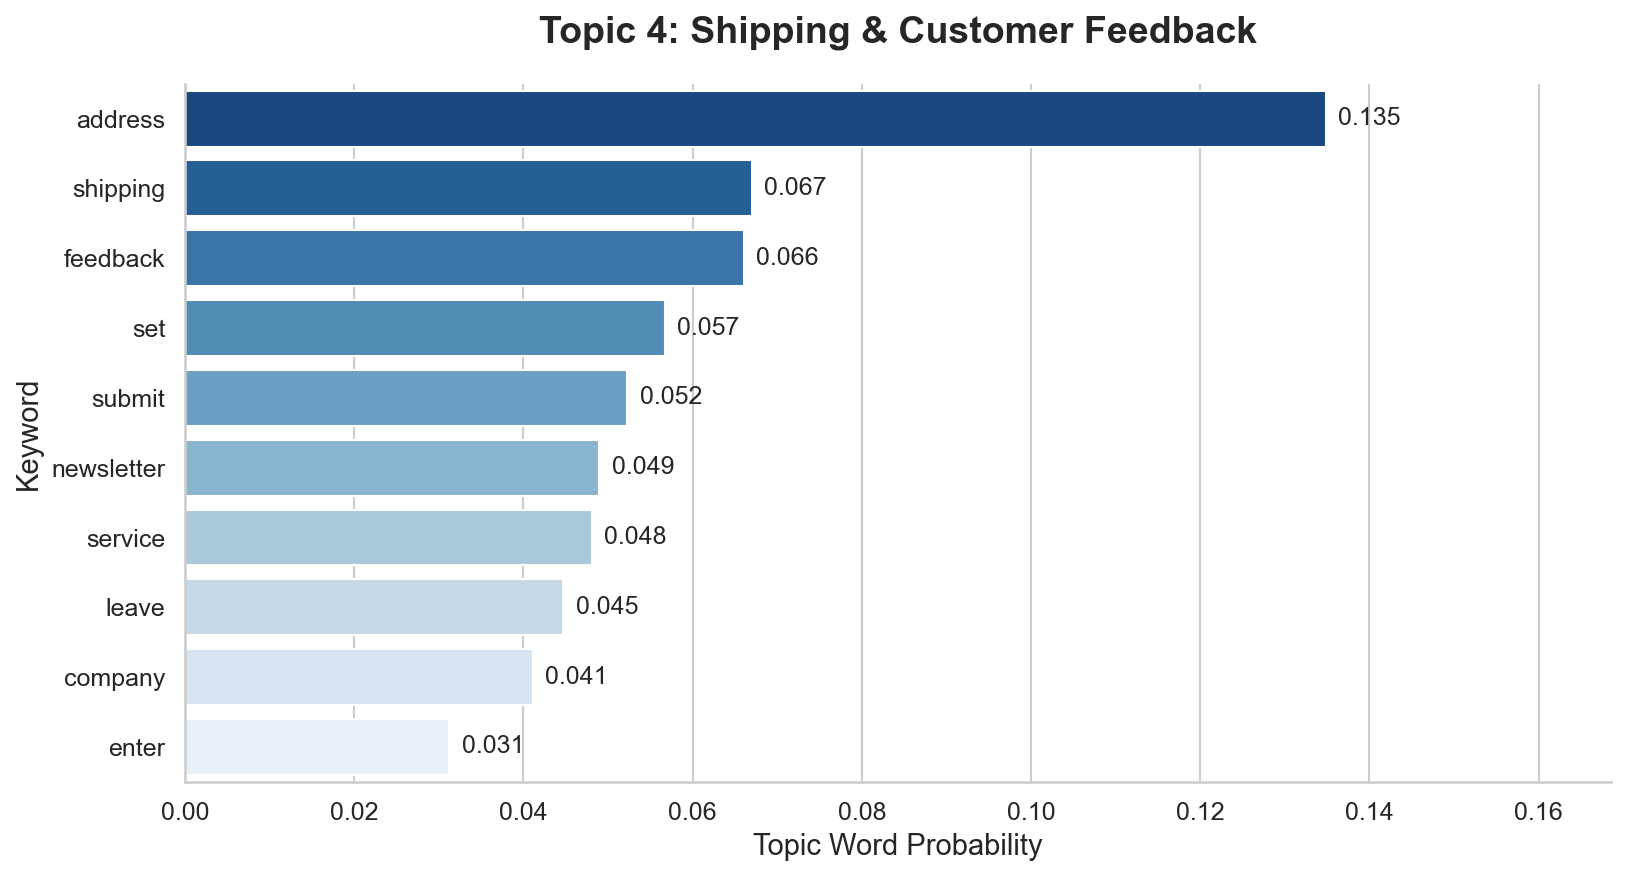

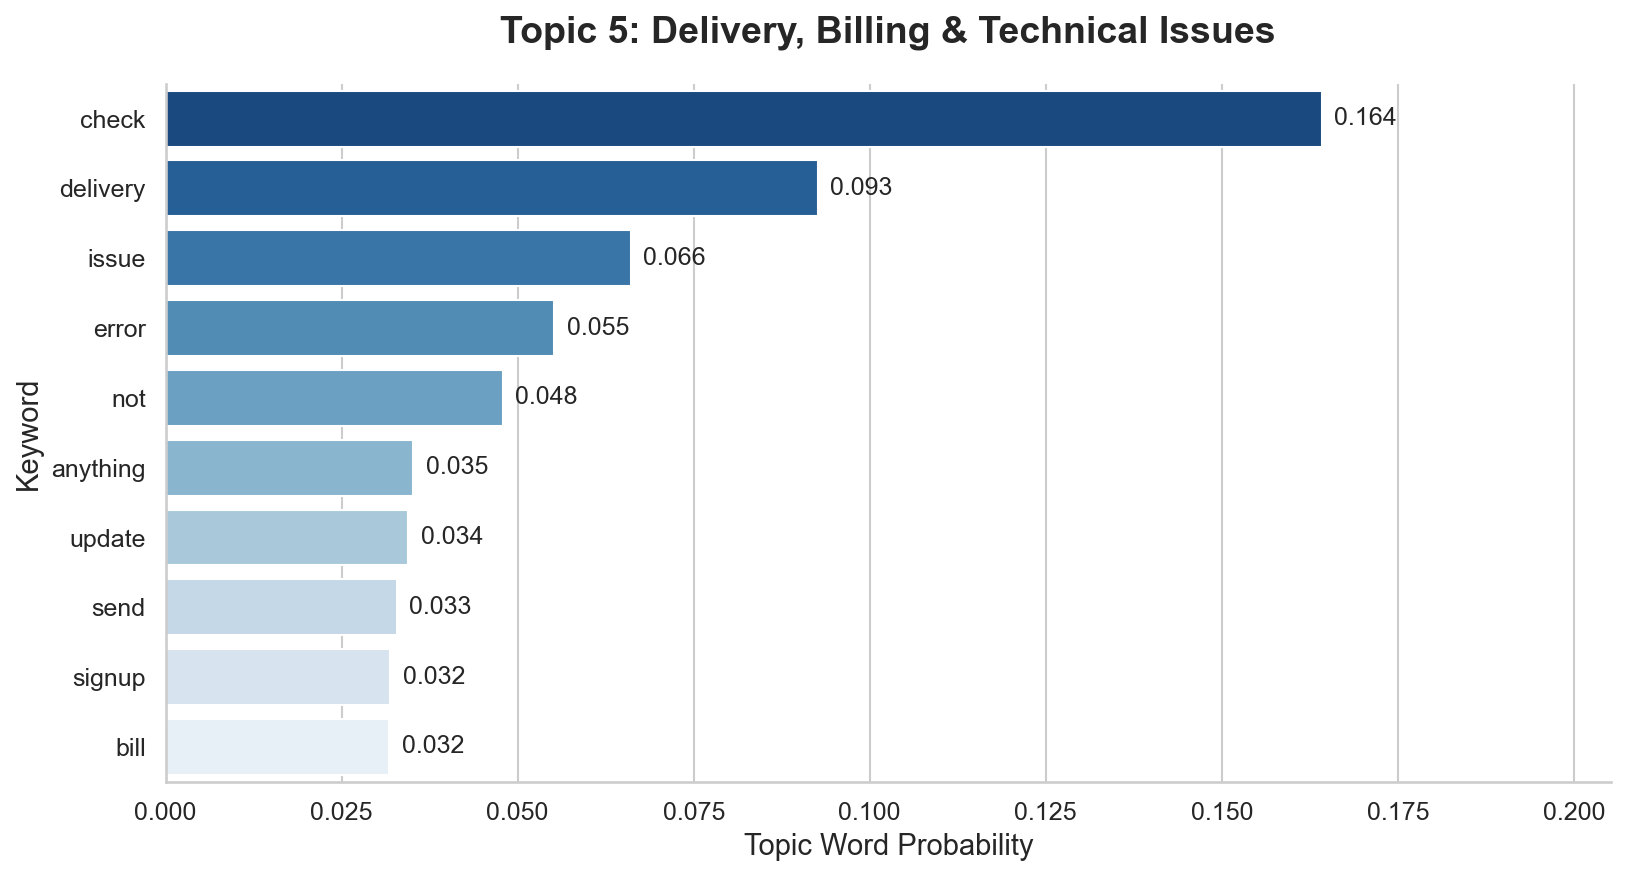

In [51]:
# Assign descriptive names to discovered topics
topic_names = {
    "Topic 1": "Order & Product Management",
    "Topic 2": "Refund & Payment Services",
    "Topic 3": "Account Management",
    "Topic 4": "Shipping & Customer Feedback",
    "Topic 5": "Delivery, Billing & Technical Issues"
}

# Map topic names
df["topic_name"] = df["dominant_topic"].map(topic_names)

# Prepare topic distribution
topic_plot_df = lda_topic_distribution.copy()

topic_plot_df["Topic Name"] = topic_plot_df["Topic"].map(
    topic_names
)

topic_plot_df["Percentage"] = (
    topic_plot_df["Count"] /
    topic_plot_df["Count"].sum() * 100
).round(2)

print("========== NAMED TOPIC DISTRIBUTION ==========")

display(topic_plot_df)

# Chart 1: Topic distribution
fig, ax = plt.subplots(figsize=(14, 7), dpi=150)

sns.barplot(
    data=topic_plot_df,
    x="Count",
    y="Topic Name",
    hue="Topic Name",
    palette="viridis",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="{:,.0f}",
        padding=8,
        fontsize=13,
        fontweight="bold"
    )

ax.set_title(
    "LDA - Customer Support Topic Distribution",
    fontsize=21,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Number of Customer Queries", fontsize=14)
ax.set_ylabel("Discovered Topic", fontsize=14)

ax.tick_params(axis="both", labelsize=12)
ax.set_xlim(0, topic_plot_df["Count"].max() * 1.2)
ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()


# Chart 2: Important keywords for each topic
for topic_id in range(lda_model.num_topics):

    words_weights = lda_model.show_topic(
        topic_id,
        topn=10
    )

    topic_words_df = pd.DataFrame(
        words_weights,
        columns=["Keyword", "Weight"]
    )

    fig, ax = plt.subplots(figsize=(11, 6), dpi=150)

    sns.barplot(
        data=topic_words_df,
        x="Weight",
        y="Keyword",
        hue="Keyword",
        palette="Blues_r",
        legend=False,
        ax=ax
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.3f",
            padding=6,
            fontsize=12
        )

    topic_label = f"Topic {topic_id + 1}"

    ax.set_title(
        f"{topic_label}: {topic_names[topic_label]}",
        fontsize=18,
        fontweight="bold",
        pad=20
    )

    ax.set_xlabel("Topic Word Probability", fontsize=14)
    ax.set_ylabel("Keyword", fontsize=14)

    ax.tick_params(axis="both", labelsize=12)
    ax.set_xlim(0, topic_words_df["Weight"].max() * 1.25)
    ax.grid(axis="y", visible=False)

    sns.despine()
    plt.tight_layout()
    plt.show()

In [52]:
from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.tokenize import sent_tokenize

# Extractive summarization function
def summarize_text(text, num_sentences=2):

    sentences = sent_tokenize(str(text))

    if len(sentences) <= num_sentences:
        return " ".join(sentences)

    # Convert sentences into TF-IDF vectors
    summary_vectorizer = TfidfVectorizer(
        stop_words=sorted(stop_words)
    )

    try:
        sentence_matrix = summary_vectorizer.fit_transform(
            sentences
        )
    except ValueError:
        return " ".join(sentences[:num_sentences])

    # Calculate sentence importance
    sentence_scores = np.asarray(
        sentence_matrix.sum(axis=1)
    ).ravel()

    # Select highest-scoring sentences
    ranked_indices = np.argsort(
        -sentence_scores
    )[:num_sentences]

    # Preserve original sentence order
    selected_indices = sorted(ranked_indices)

    summary = " ".join(
        sentences[i] for i in selected_indices
    )

    return summary


# Select customer support responses
summary_sample = df[
    ["instruction", "response"]
].sample(5, random_state=42).copy()

# Generate summaries
summary_sample["summary"] = summary_sample[
    "response"
].apply(summarize_text)

# Calculate word counts
summary_sample["original_words"] = summary_sample[
    "response"
].apply(lambda text: len(text.split()))

summary_sample["summary_words"] = summary_sample[
    "summary"
].apply(lambda text: len(text.split()))

# Calculate compression percentage
summary_sample["reduction_percentage"] = (
    1 - summary_sample["summary_words"] /
    summary_sample["original_words"].clip(lower=1)
) * 100

print("========== SUMMARIZATION RESULTS ==========")

for _, row in summary_sample.iterrows():

    print("\n" + "=" * 70)

    print("CUSTOMER QUERY:")
    print(row["instruction"])

    print("\nORIGINAL RESPONSE:")
    print(row["response"])

    print("\nEXTRACTED SUMMARY:")
    print(row["summary"])

    print("\nOriginal words:", row["original_words"])
    print("Summary words:", row["summary_words"])

    print(
        f"Word reduction: "
        f"{row['reduction_percentage']:.2f}%"
    )

# Overall statistics
print("\n========== SUMMARIZATION STATISTICS ==========")

display(
    summary_sample[
        [
            "original_words",
            "summary_words",
            "reduction_percentage"
        ]
    ].round(2)
)

print(
    "Average word reduction:",
    round(summary_sample["reduction_percentage"].mean(), 2),
    "%"
)

========== SUMMARIZATION RESULTS ==========

CUSTOMER QUERY:
I can't talk with  a human agent

ORIGINAL RESPONSE:
Thank you for reaching out! I'm sorry to hear that you're facing difficulties in connecting with a human agent. Please rest assured that I'm here to assist you and resolve this issue. Could you please provide me with some more details about the problem you're experiencing? This will help me find the best solution for you.

EXTRACTED SUMMARY:
I'm sorry to hear that you're facing difficulties in connecting with a human agent. Please rest assured that I'm here to assist you and resolve this issue.

Original words: 56
Summary words: 27
Word reduction: 51.79%

CUSTOMER QUERY:
I have got to locate hte bills from {{Person Name}}

ORIGINAL RESPONSE:
I'll get right on it! I understand your need to locate the bills associated with {{Person Name}}. To assist you in finding the relevant invoices, could you please provide me with some additional details such as the date range or any oth

,original_words,summary_words,reduction_percentage
9329,56,27,51.79
4160,68,51,25.00
18500,103,35,66.02
8840,74,36,51.35
5098,98,30,69.39


Average word reduction: 52.71 %


In [53]:
# Select required columns for machine learning
ml_df = df[
    ["instruction", "cleaned_text", "processed_text",
     "category", "intent"]
].copy()

print("========== ORIGINAL DATASET ==========")
print("Total records:", len(ml_df))

# Remove empty processed queries
ml_df = ml_df[
    ml_df["processed_text"].str.strip().ne("")
].copy()

print("Records after removing empty queries:", len(ml_df))

# Normalize placeholders and numerical identifiers
def normalize_ml_text(text):

    text = re.sub(
        r"\{\{[^{}]+\}\}",
        " placeholder ",
        text
    )

    text = re.sub(
        r"\d+",
        " numbertoken ",
        text
    )

    return clean_text(text)


# Create normalized classification text
ml_df["ml_text"] = ml_df["instruction"].apply(
    normalize_ml_text
)

# Remove empty normalized queries
ml_df = ml_df[
    ml_df["ml_text"].str.strip().ne("")
].copy()

# Check conflicting intent labels
conflicting_queries = (
    ml_df.groupby("ml_text")["intent"]
    .nunique()
)

conflicting_queries = conflicting_queries[
    conflicting_queries > 1
].index

print("\n========== CONFLICTING LABELS ==========")
print("Conflicting normalized queries:", len(conflicting_queries))

# Remove ambiguous queries
ml_df = ml_df[
    ~ml_df["ml_text"].isin(conflicting_queries)
].copy()

# Count duplicates before removal
duplicate_count = ml_df["ml_text"].duplicated().sum()

# Remove duplicate normalized queries
ml_df = ml_df.drop_duplicates(
    subset="ml_text"
).reset_index(drop=True)

print("\n========== FINAL ML DATASET ==========")

print("Duplicate queries removed:", duplicate_count)
print("Final records:", len(ml_df))
print("Unique categories:", ml_df["category"].nunique())
print("Unique intents:", ml_df["intent"].nunique())
print("Remaining duplicates:", ml_df["ml_text"].duplicated().sum())

# Display sample records
display(
    ml_df[
        ["instruction", "ml_text", "category", "intent"]
    ].sample(10, random_state=42)
)

# Final intent distribution
print("\n========== FINAL INTENT DISTRIBUTION ==========")

display(
    ml_df["intent"].value_counts()
    .rename_axis("Intent")
    .reset_index(name="Count")
)

========== ORIGINAL DATASET ==========
Total records: 26872
Records after removing empty queries: 26872

========== CONFLICTING LABELS ==========
Conflicting normalized queries: 0

========== FINAL ML DATASET ==========
Duplicate queries removed: 3400
Final records: 23472
Unique categories: 11
Unique intents: 27
Remaining duplicates: 0


,instruction,ml_text,category,intent
11727,I am trying to see when will my purchase arrive,i am trying to see when will my purchase arrive,DELIVERY,delivery_period
22242,I have got to track purchase {{Order Number}},i have got to track purchase placeholder,ORDER,track_order
13398,i want assistance to get my invoice #37777,i want assistance to get my invoice numbertoken,INVOICE,get_invoice
21118,issues setting up another shipping address,issues setting up another shipping address,SHIPPING,set_up_shipping_address
16938,I need assistance ordering an item,i need assistance ordering an item,ORDER,place_order
16801,assistance shopping a few of ur product,assistance shopping a few of ur product,ORDER,place_order
12978,need to get my bill #12588,need to get my bill numbertoken,INVOICE,get_invoice
15382,give me information about the subscription to ur newsletter,give me information about the subscription to ur newsletter,SUBSCRIPTION,newsletter_subscription
9060,can I open a gold account for my daughter?,can i open a gold account for my daughter,ACCOUNT,create_account
20300,could you help me leaving an opinion about a product?,could you help me leaving an opinion about a product,FEEDBACK,review



========== FINAL INTENT DISTRIBUTION ==========


,Intent,Count
0,complaint,994
1,review,991
2,set_up_shipping_address,989
3,payment_issue,989
4,registration_problems,986
5,recover_password,986
6,place_order,986
7,delivery_period,986
8,check_payment_methods,984
9,newsletter_subscription,977


========== TRAIN-TEST SPLIT ==========
Total records: 23,472
Training records: 18,777
Testing records: 4,695

Training intent classes: 27
Testing intent classes: 27

========== DATA LEAKAGE CHECK ==========
Identical normalized queries across splits: 0

========== CLASS DISTRIBUTION ==========


,Training Count,Testing Count,Training %,Testing %
intent,,,,
cancel_order,326,81,1.74,1.73
change_order,672,168,3.58,3.58
change_shipping_address,766,191,4.08,4.07
check_cancellation_fee,737,184,3.93,3.92
check_invoice,682,170,3.63,3.62
check_payment_methods,787,197,4.19,4.20
check_refund_policy,773,194,4.12,4.13
complaint,795,199,4.23,4.24
contact_customer_service,774,194,4.12,4.13


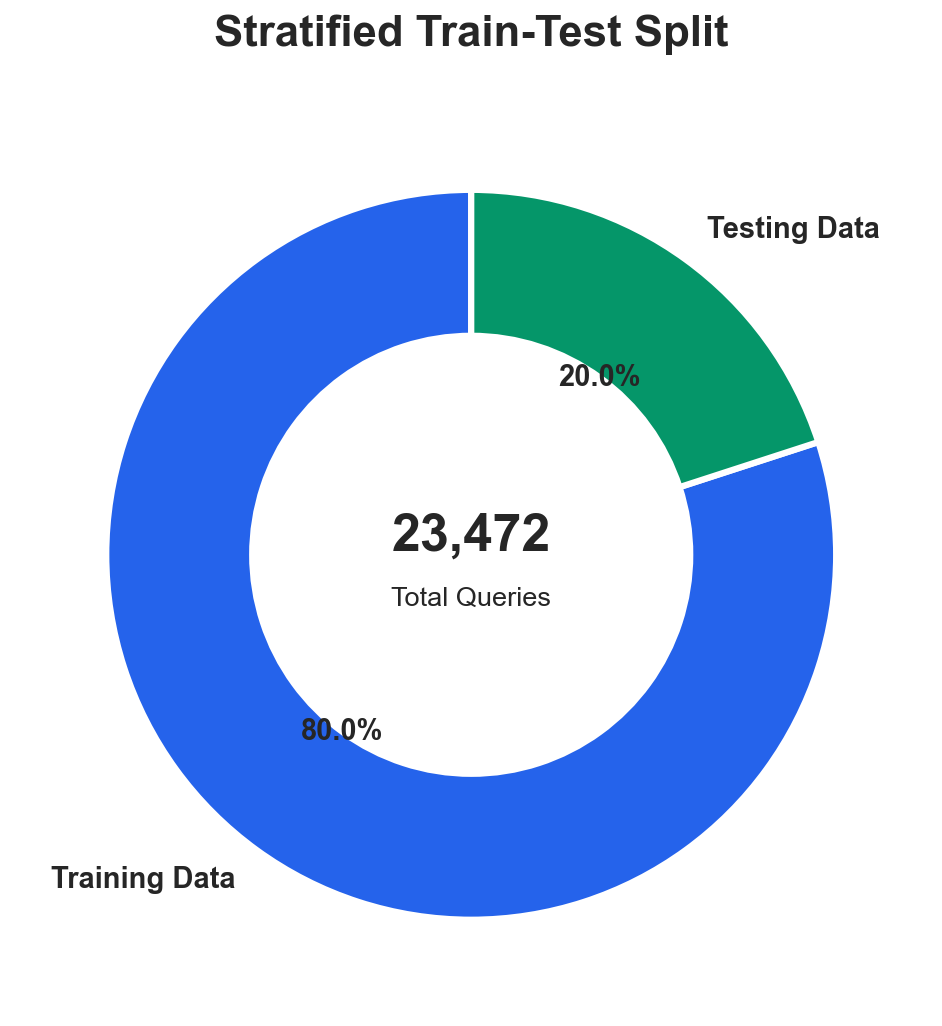

In [54]:
from sklearn.model_selection import train_test_split

# Independent variable - customer query
X = ml_df["ml_text"]

# Dependent variable - customer intent
y = ml_df["intent"]

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset split statistics
print("========== TRAIN-TEST SPLIT ==========")

print(f"Total records: {len(X):,}")
print(f"Training records: {len(X_train):,}")
print(f"Testing records: {len(X_test):,}")

print("\nTraining intent classes:", y_train.nunique())
print("Testing intent classes:", y_test.nunique())

# Check duplicate overlap between splits
overlap = set(X_train).intersection(set(X_test))

print("\n========== DATA LEAKAGE CHECK ==========")

print("Identical normalized queries across splits:", len(overlap))

# Compare class distributions
split_distribution = pd.DataFrame({
    "Training Count": y_train.value_counts(),
    "Testing Count": y_test.value_counts()
})

split_distribution["Training %"] = (
    split_distribution["Training Count"] / len(y_train) * 100
).round(2)

split_distribution["Testing %"] = (
    split_distribution["Testing Count"] / len(y_test) * 100
).round(2)

print("\n========== CLASS DISTRIBUTION ==========")

display(split_distribution)

# Visualize dataset split
fig, ax = plt.subplots(figsize=(9, 7), dpi=150)

ax.pie(
    [len(X_train), len(X_test)],
    labels=["Training Data", "Testing Data"],
    colors=["#2563EB", "#059669"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={
        "width": 0.40,
        "edgecolor": "white",
        "linewidth": 3
    },
    textprops={
        "fontsize": 14,
        "fontweight": "bold"
    }
)

ax.text(
    0, 0.05,
    f"{len(X):,}",
    ha="center",
    va="center",
    fontsize=25,
    fontweight="bold"
)

ax.text(
    0, -0.12,
    "Total Queries",
    ha="center",
    va="center",
    fontsize=13
)

ax.set_title(
    "Stratified Train-Test Split",
    fontsize=21,
    fontweight="bold",
    pad=25
)

plt.tight_layout()
plt.show()

In [55]:
import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

# Define classification algorithms
classifiers = {
    "Naive Bayes": MultinomialNB(
        alpha=0.5
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        C=5.0,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    )
}

# Configure cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

# Store models and results
trained_models = {}
model_results = []

# Train and evaluate models
for name, classifier in classifiers.items():

    print("=" * 65)
    print(f"Training: {name}")
    print("=" * 65)

    start_time = time.time()

    # Create NLP classification pipeline
    model_pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True,
                max_features=20000
            )
        ),
        ("classifier", classifier)
    ])

    # Perform cross-validation
    cv_results = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    # Train pipeline on complete training data
    model_pipeline.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    # Save trained model
    trained_models[name] = model_pipeline

    # Save evaluation results
    result = {
        "Model": name,
        "CV Accuracy": cv_results["test_accuracy"].mean(),
        "CV Precision": cv_results["test_precision"].mean(),
        "CV Recall": cv_results["test_recall"].mean(),
        "CV F1 Score": cv_results["test_f1"].mean(),
        "F1 Std": cv_results["test_f1"].std(),
        "Time (seconds)": elapsed_time
    }

    model_results.append(result)

    print(f"CV Accuracy: {result['CV Accuracy']:.4f}")
    print(f"CV Precision: {result['CV Precision']:.4f}")
    print(f"CV Recall: {result['CV Recall']:.4f}")
    print(f"CV F1 Score: {result['CV F1 Score']:.4f}")
    print(f"Execution Time: {elapsed_time:.2f} seconds")

# Create model comparison dataframe
model_results_df = pd.DataFrame(
    model_results
).sort_values(
    "CV F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n========== MODEL COMPARISON ==========")

display(model_results_df.round(4))

# Select best model using cross-validation
best_model_name = model_results_df.loc[0, "Model"]

best_model = trained_models[best_model_name]

print("\n========== BEST MODEL ==========")

print("Selected model:", best_model_name)

print(
    "Best CV F1 Score:",
    round(model_results_df.loc[0, "CV F1 Score"], 4)
)

Training: Naive Bayes
CV Accuracy: 0.9881
CV Precision: 0.9882
CV Recall: 0.9856
CV F1 Score: 0.9866
Execution Time: 3.37 seconds
Training: Logistic Regression
CV Accuracy: 0.9923
CV Precision: 0.9920
CV Recall: 0.9907
CV F1 Score: 0.9912
Execution Time: 11.81 seconds
Training: Linear SVM
CV Accuracy: 0.9923
CV Precision: 0.9919
CV Recall: 0.9906
CV F1 Score: 0.9912
Execution Time: 8.76 seconds

========== MODEL COMPARISON ==========


,Model,CV Accuracy,CV Precision,CV Recall,CV F1 Score,F1 Std,Time (seconds)
0,Logistic Regression,0.9923,0.9920,0.9907,0.9912,0.0033,11.8098
1,Linear SVM,0.9923,0.9919,0.9906,0.9912,0.0031,8.7623
2,Naive Bayes,0.9881,0.9882,0.9856,0.9866,0.0038,3.3680



========== BEST MODEL ==========
Selected model: Logistic Regression
Best CV F1 Score: 0.9912


========== FINAL MODEL EVALUATION ==========
Selected Model: Logistic Regression
Training Records: 18777
Testing Records: 4695

Test Accuracy:  0.9928
Test Precision: 0.9929
Test Recall:    0.9912
Test F1 Score:  0.9920

========== PREDICTION SUMMARY ==========
Correct predictions: 4661
Incorrect predictions: 34

========== CLASSIFICATION REPORT ==========


,precision,recall,f1-score,support
cancel_order,1.0000,0.9383,0.9682,81.0000
change_order,0.9595,0.9881,0.9736,168.0000
change_shipping_address,0.9948,1.0000,0.9974,191.0000
check_cancellation_fee,0.9946,1.0000,0.9973,184.0000
check_invoice,0.9767,0.9882,0.9825,170.0000
check_payment_methods,1.0000,1.0000,1.0000,197.0000
check_refund_policy,1.0000,1.0000,1.0000,194.0000
complaint,1.0000,1.0000,1.0000,199.0000
contact_customer_service,1.0000,0.9794,0.9896,194.0000
contact_human_agent,0.9796,1.0000,0.9897,192.0000



========== CATEGORY LEVEL PERFORMANCE ==========
Category Accuracy: 0.9977


,Metric,Score
0,Accuracy,0.9928
1,Macro Precision,0.9929
2,Macro Recall,0.9912
3,Macro F1 Score,0.9920
4,Category Accuracy,0.9977


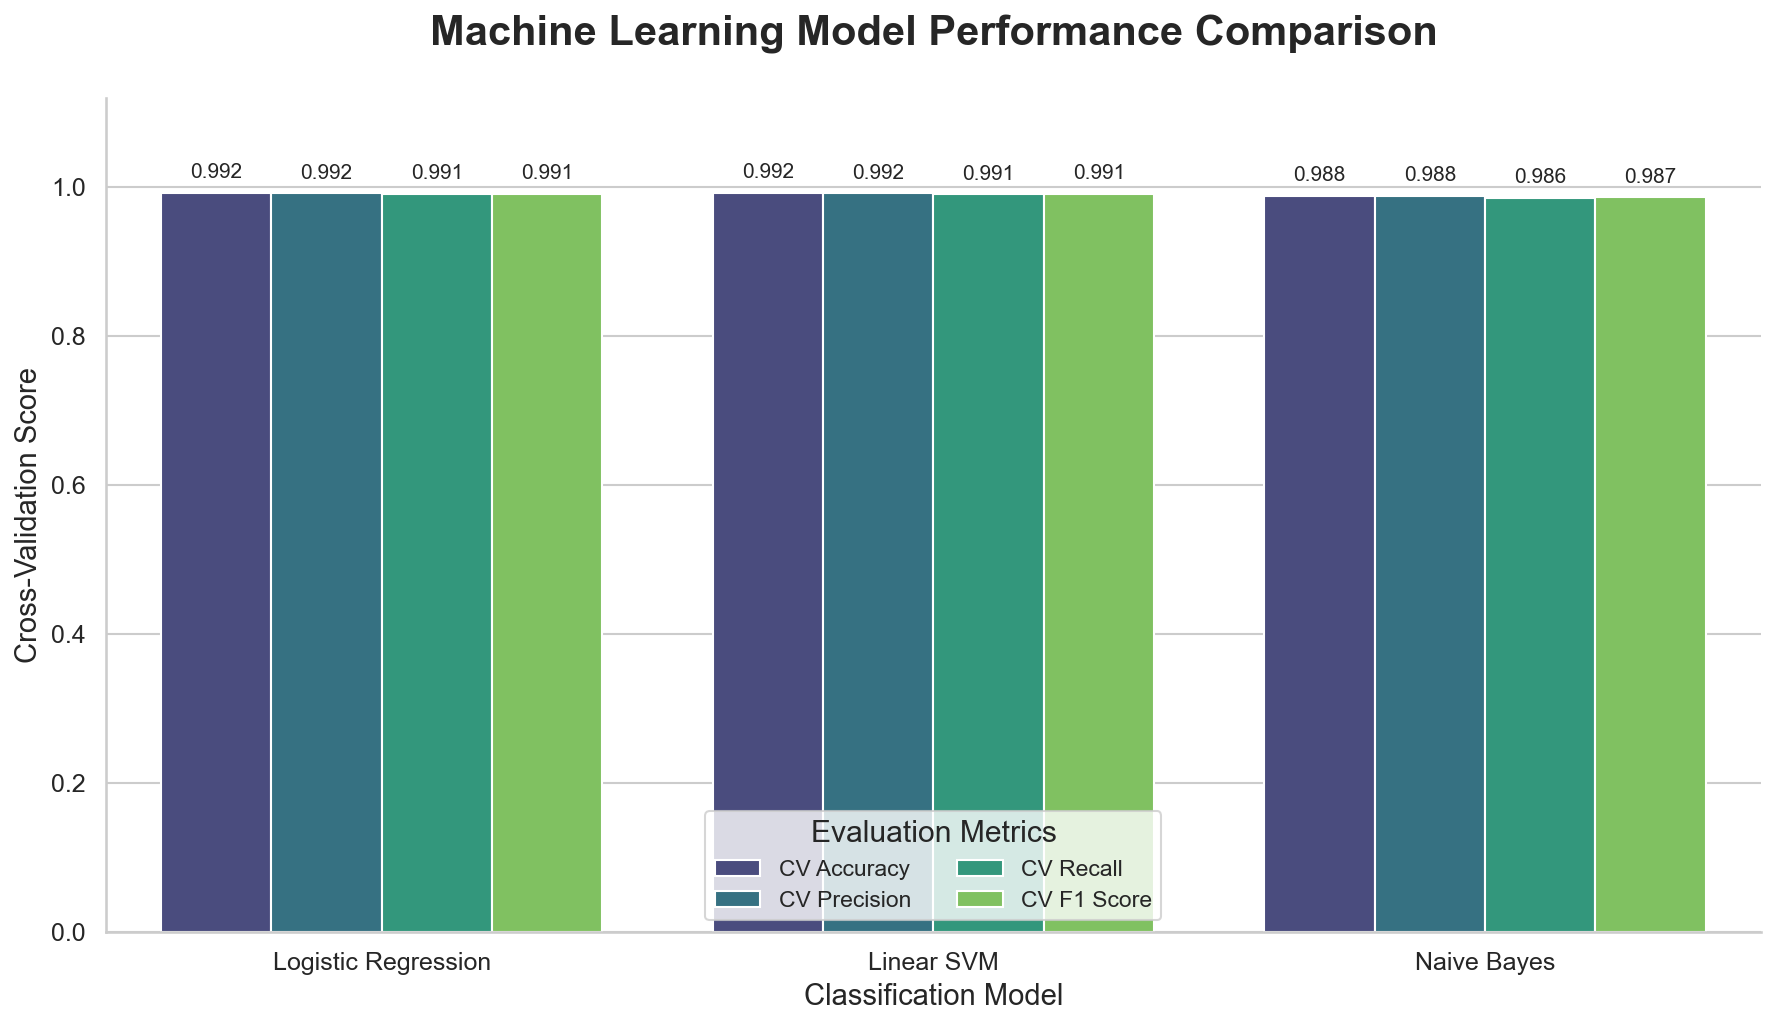

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict intents on unseen test data
y_pred = best_model.predict(X_test)

# Calculate evaluation metrics
test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

# Display final model performance
print("========== FINAL MODEL EVALUATION ==========")

print("Selected Model:", best_model_name)
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print(f"\nTest Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test F1 Score:  {test_f1:.4f}")

# Correct and incorrect predictions
correct_predictions = np.sum(y_test.to_numpy() == y_pred)
incorrect_predictions = len(y_test) - correct_predictions

print("\n========== PREDICTION SUMMARY ==========")

print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)

# Classification report
print("\n========== CLASSIFICATION REPORT ==========")

report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

# Map intents to support categories
intent_category_map = (
    ml_df.loc[X_train.index, ["intent", "category"]]
    .groupby("intent")["category"]
    .agg(lambda values: values.mode().iloc[0])
    .to_dict()
)

actual_categories = ml_df.loc[X_test.index, "category"]

predicted_categories = pd.Series(
    y_pred,
    index=X_test.index
).map(intent_category_map)

category_accuracy = accuracy_score(
    actual_categories,
    predicted_categories
)

print("\n========== CATEGORY LEVEL PERFORMANCE ==========")

print(f"Category Accuracy: {category_accuracy:.4f}")

# Create evaluation dataframe
test_metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1 Score",
        "Category Accuracy"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        category_accuracy
    ]
})

display(test_metrics_df.round(4))

# Visualize cross-validation model comparison
fig, ax = plt.subplots(figsize=(12, 7), dpi=150)

comparison_df = model_results_df.melt(
    id_vars="Model",
    value_vars=[
        "CV Accuracy",
        "CV Precision",
        "CV Recall",
        "CV F1 Score"
    ],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette="viridis",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=5,
        fontsize=10
    )

ax.set_title(
    "Machine Learning Model Performance Comparison",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Classification Model", fontsize=14)
ax.set_ylabel("Cross-Validation Score", fontsize=14)

ax.set_ylim(0, 1.12)

ax.tick_params(axis="both", labelsize=12)

ax.legend(
    title="Evaluation Metrics",
    loc="lower center",
    fontsize=11,
    ncol=2
)

ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

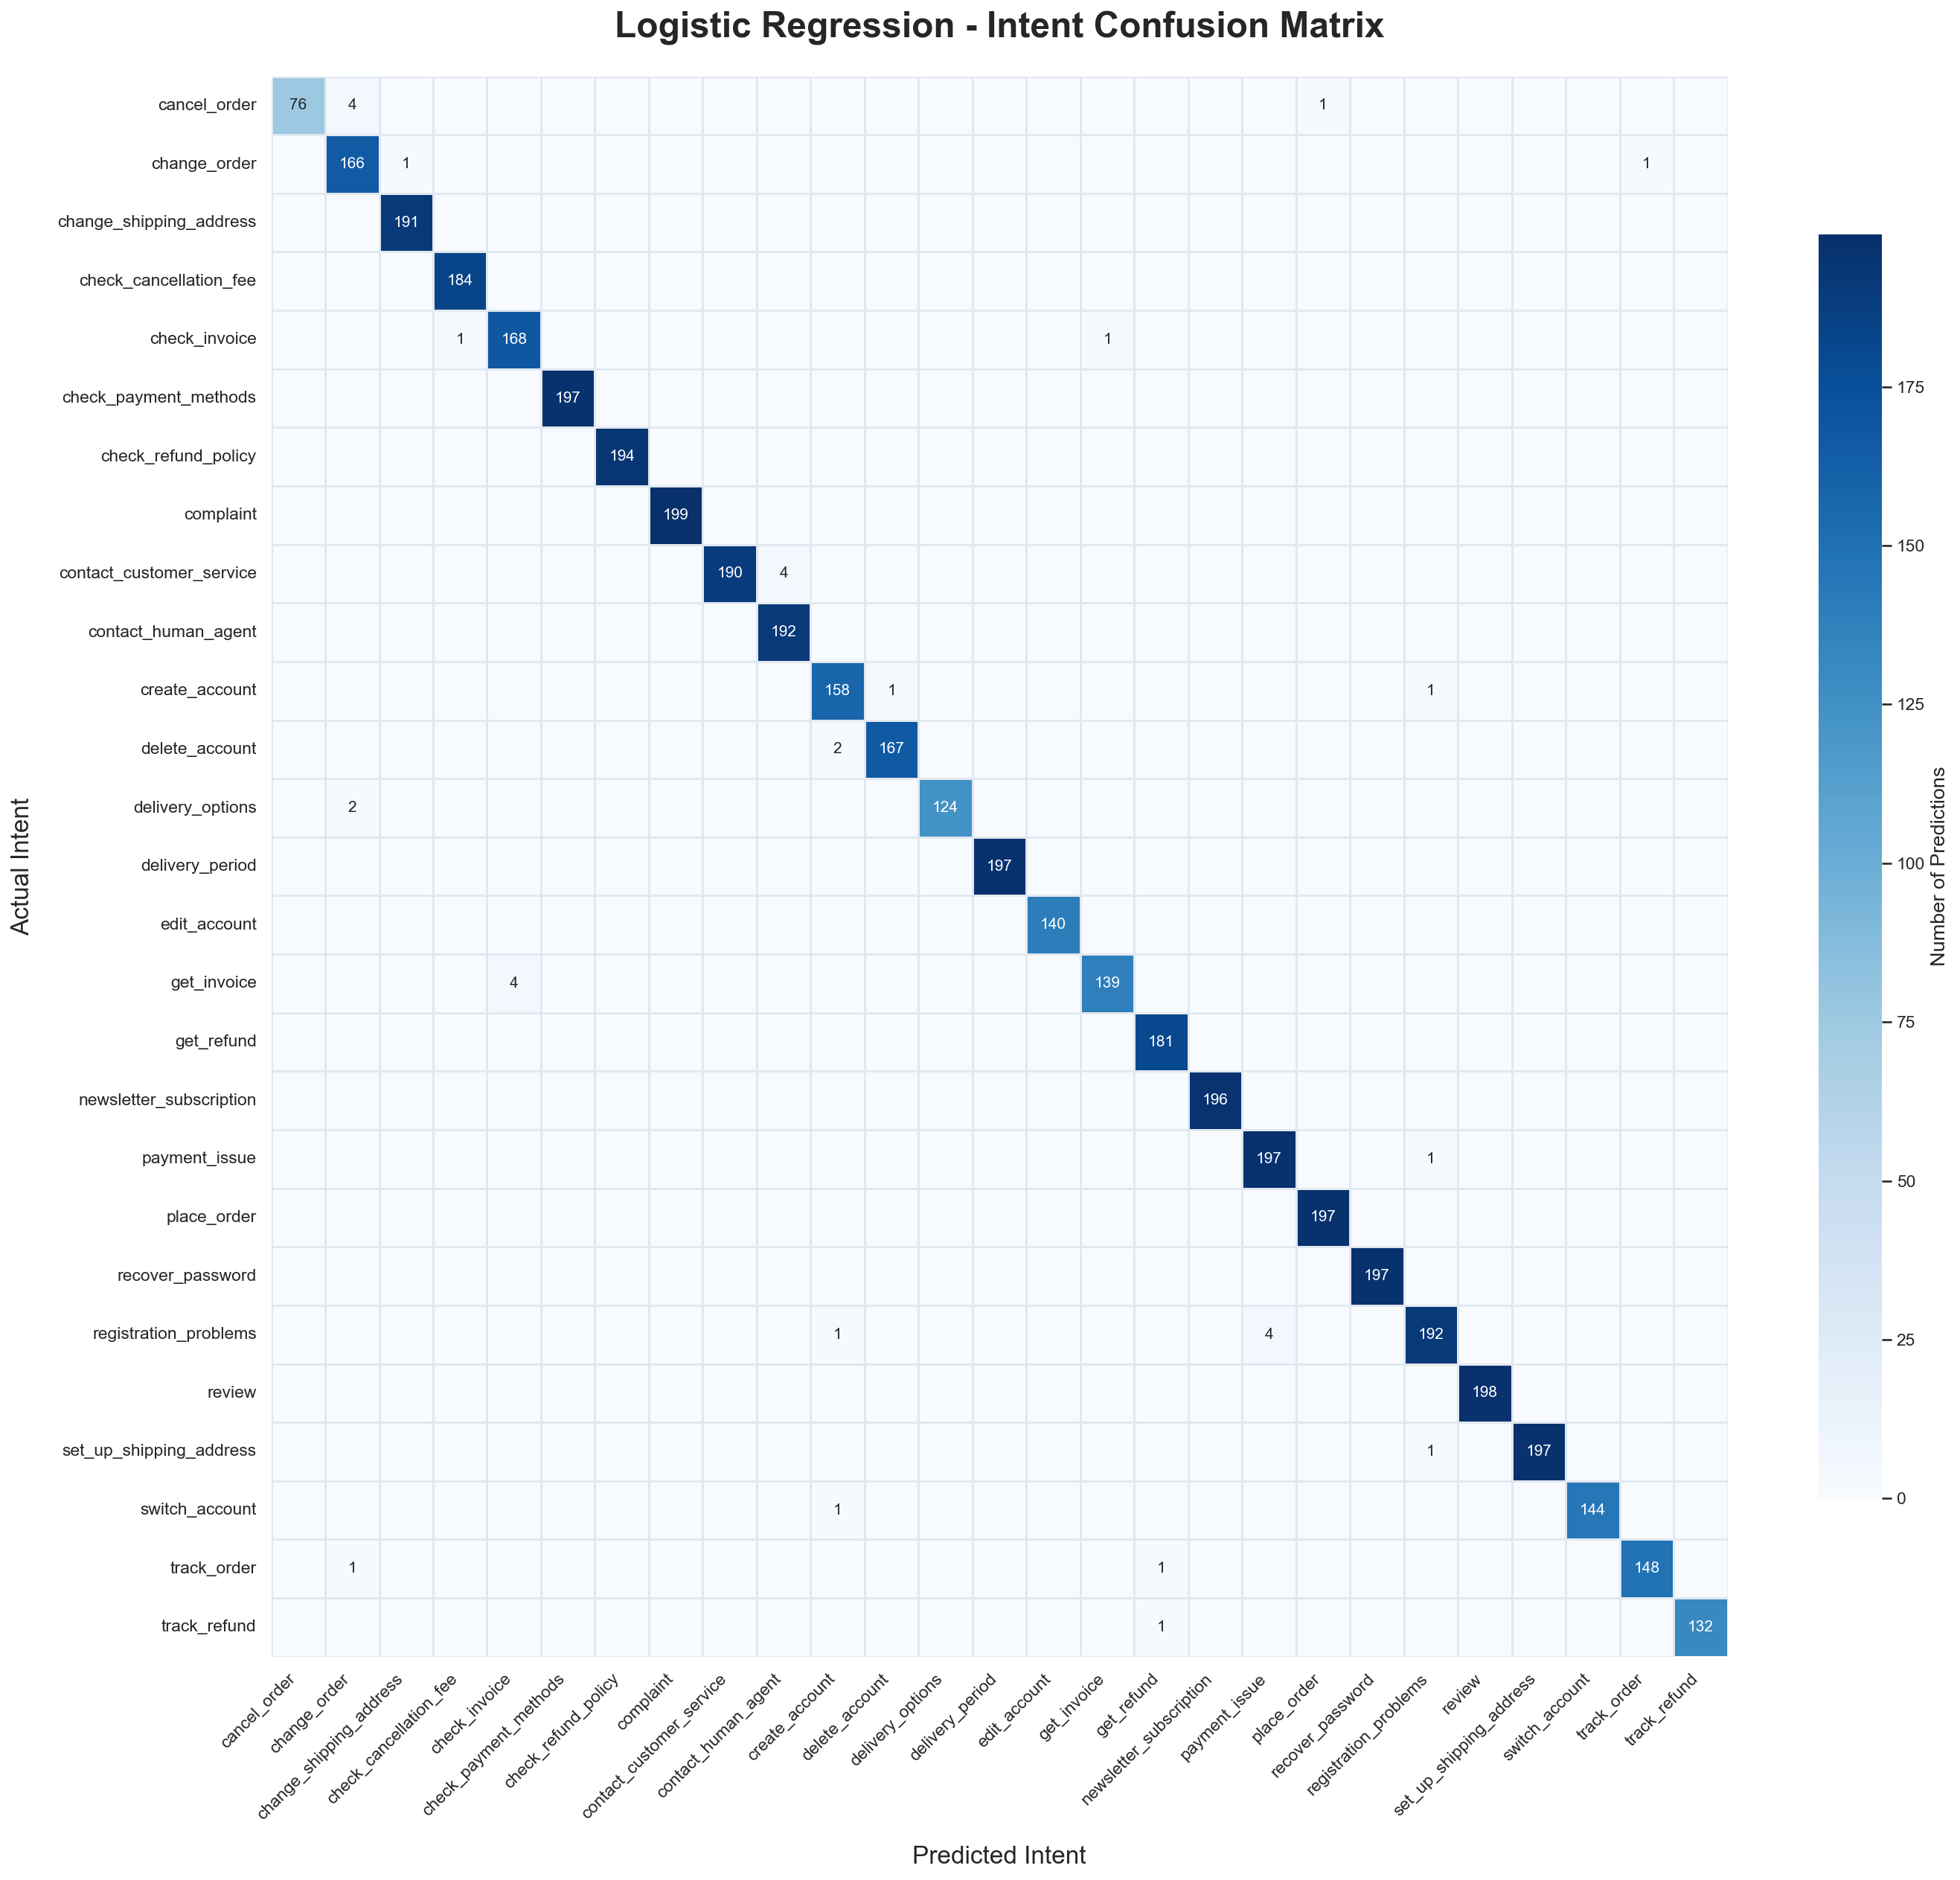

========== MISCLASSIFICATION ANALYSIS ==========
Total test queries: 4695
Incorrect predictions: 34
Error rate: 0.72%


,instruction,Actual Intent,Predicted Intent
0,when will I receive ordered {{Order Number}}?,track_order,get_refund
1,how can I erdit purchase {{Order Number}}?,change_order,track_order
2,I do not know how I can inform of an error with signjp,registration_problems,payment_issue
3,i canot correct the order i made,change_order,change_shipping_address
4,need help to report problems with a registratoon,registration_problems,payment_issue
5,i dont know what to do to talk with customre assistance,contact_customer_service,contact_human_agent
6,I need help to deelete a pro account,delete_account,create_account
7,assistance informing of an error with onlinepayment,payment_issue,registration_problems
8,what do I need to do to cancell a {{Account Category}} account?,delete_account,create_account
9,could uhelp me cancelin order {{Order Number}},cancel_order,change_order



========== MOST CONFUSED INTENTS ==========


,Actual Intent,Predicted Intent,Count
0,cancel_order,change_order,4
6,contact_customer_service,contact_human_agent,4
14,registration_problems,payment_issue,4
11,get_invoice,check_invoice,4
9,delete_account,create_account,2
10,delivery_options,change_order,2
5,check_invoice,get_invoice,1
7,create_account,delete_account,1
8,create_account,registration_problems,1
4,check_invoice,check_cancellation_fee,1


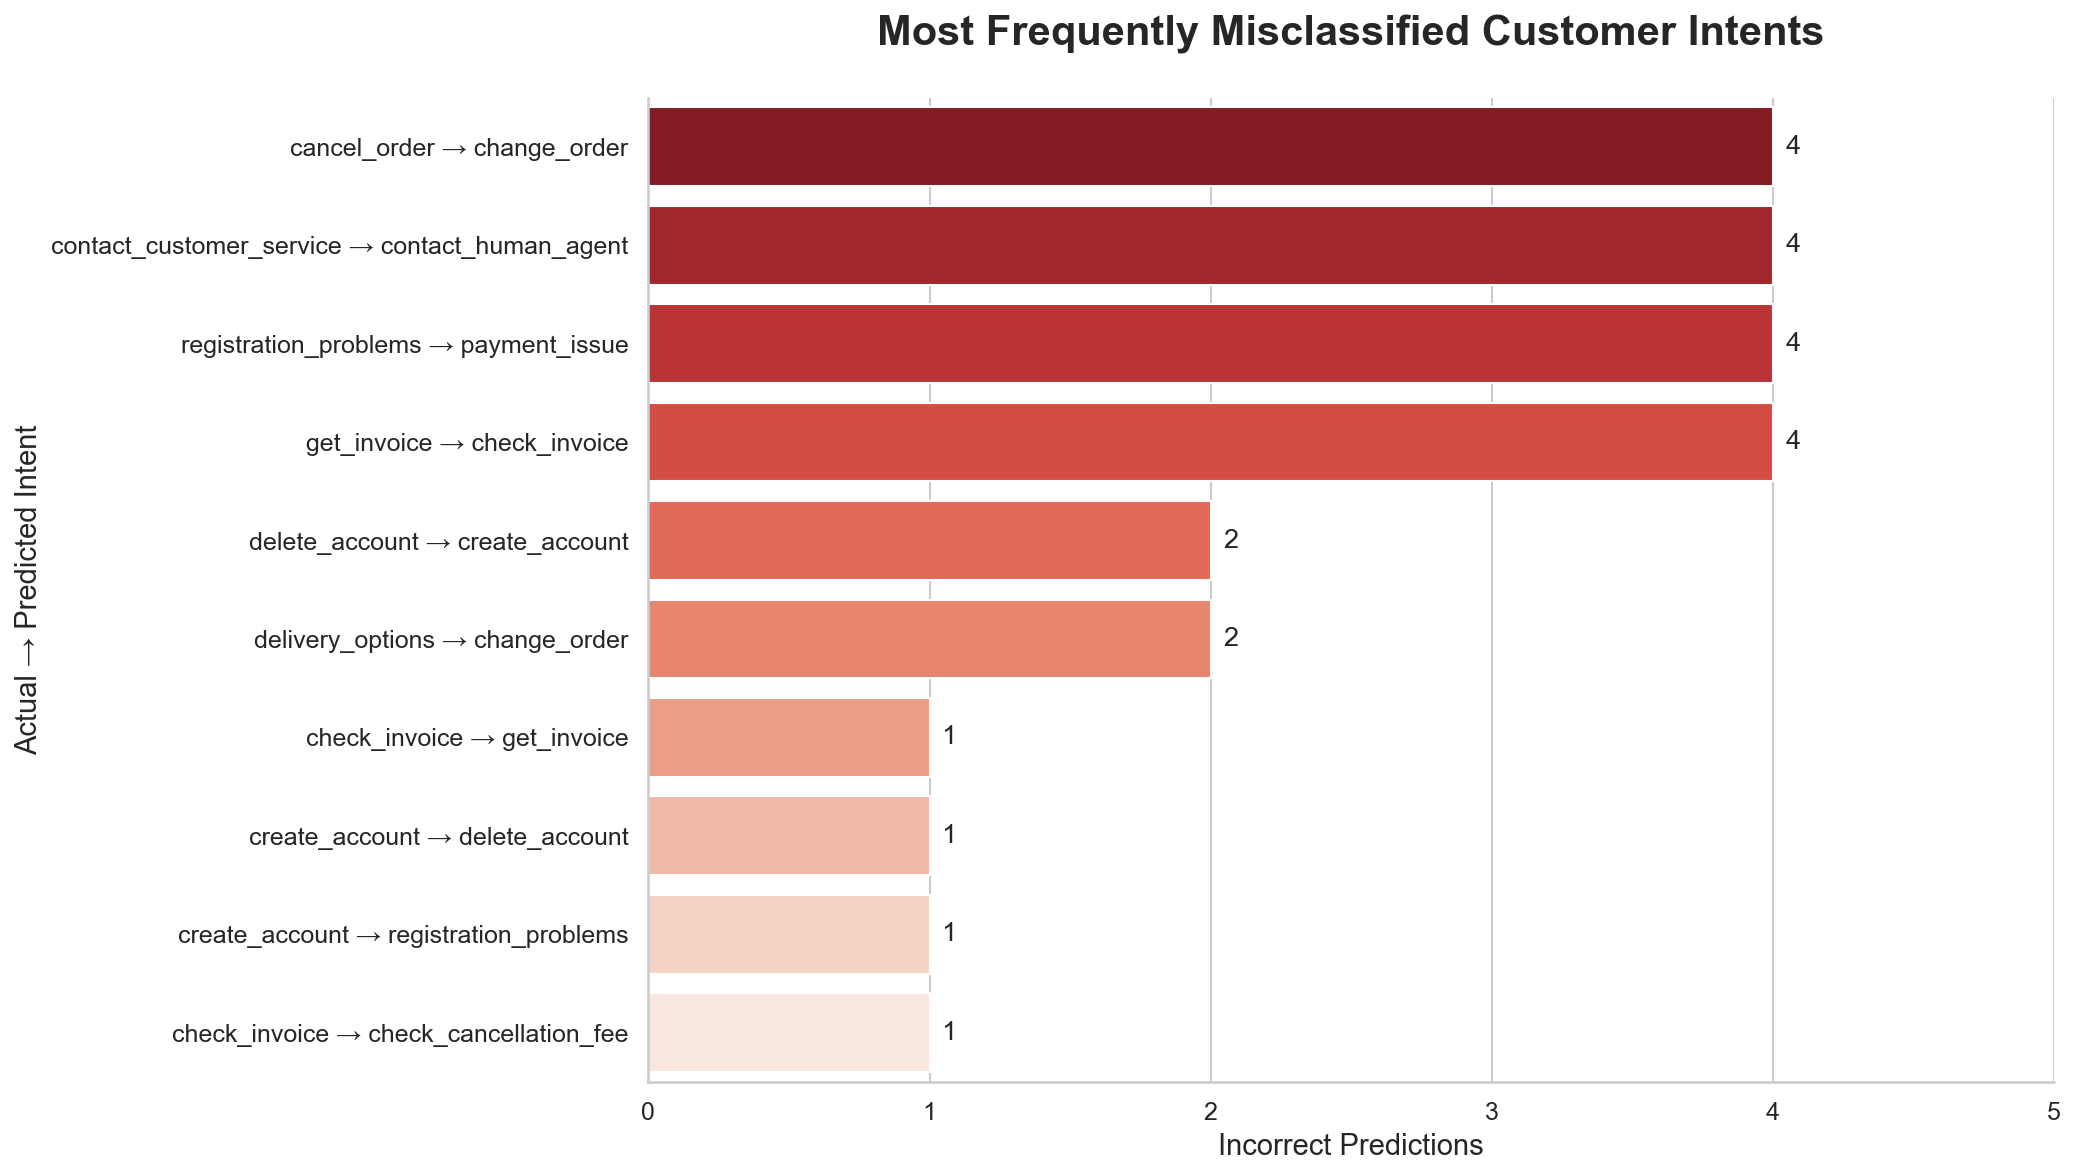

In [57]:
from sklearn.metrics import confusion_matrix

# Get all intent labels
intent_labels = sorted(y_test.unique())

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=intent_labels
)

# Create readable confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=intent_labels,
    columns=intent_labels
)

# Replace zero annotations with empty strings
annotations = np.where(
    cm == 0,
    "",
    cm.astype(str)
)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(19, 17), dpi=150)

sns.heatmap(
    cm_df,
    annot=annotations,
    fmt="",
    cmap="Blues",
    linewidths=0.5,
    linecolor="#E2E8F0",
    annot_kws={"size": 10},
    cbar_kws={
        "label": "Number of Predictions",
        "shrink": 0.8
    },
    ax=ax
)

ax.set_title(
    "Logistic Regression - Intent Confusion Matrix",
    fontsize=23,
    fontweight="bold",
    pad=25
)

ax.set_xlabel(
    "Predicted Intent",
    fontsize=16,
    labelpad=15
)

ax.set_ylabel(
    "Actual Intent",
    fontsize=16,
    labelpad=15
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=11
)

plt.yticks(
    rotation=0,
    fontsize=11
)

plt.tight_layout()
plt.show()


# MISCLASSIFICATION ANALYSIS

error_df = ml_df.loc[
    X_test.index,
    ["instruction", "category", "intent"]
].copy()

error_df["Predicted Intent"] = y_pred

error_df = error_df.rename(
    columns={"intent": "Actual Intent"}
)

# Extract incorrect predictions
error_df = error_df[
    error_df["Actual Intent"] !=
    error_df["Predicted Intent"]
].copy()

print("========== MISCLASSIFICATION ANALYSIS ==========")

print("Total test queries:", len(y_test))
print("Incorrect predictions:", len(error_df))

print(
    f"Error rate: "
    f"{len(error_df) / len(y_test) * 100:.2f}%"
)

# Display incorrect predictions
display(
    error_df[
        [
            "instruction",
            "Actual Intent",
            "Predicted Intent"
        ]
    ].reset_index(drop=True)
)

# Most frequently confused intent pairs
confused_intents = (
    error_df.groupby(
        ["Actual Intent", "Predicted Intent"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\n========== MOST CONFUSED INTENTS ==========")

display(confused_intents.head(15))


# Visualize most confused intent pairs
error_plot_df = confused_intents.head(10).copy()

error_plot_df["Intent Pair"] = (
    error_plot_df["Actual Intent"]
    + " → "
    + error_plot_df["Predicted Intent"]
)

fig, ax = plt.subplots(figsize=(14, 8), dpi=150)

sns.barplot(
    data=error_plot_df,
    x="Count",
    y="Intent Pair",
    hue="Intent Pair",
    palette="Reds_r",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=6,
        fontsize=13
    )

ax.set_title(
    "Most Frequently Misclassified Customer Intents",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_xlabel("Incorrect Predictions", fontsize=14)
ax.set_ylabel("Actual → Predicted Intent", fontsize=14)

ax.tick_params(axis="both", labelsize=12)
ax.set_xlim(0, error_plot_df["Count"].max() * 1.25)

from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax.grid(axis="y", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

In [58]:
import joblib
import sklearn
from pathlib import Path

# Locate project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create models directory
models_dir = project_root / "models"

models_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save trained classification pipeline
model_path = models_dir / "intent_classifier.pkl"

joblib.dump(best_model, model_path)

# Save intent-category mapping
joblib.dump(
    intent_category_map,
    models_dir / "intent_category_map.pkl"
)

# Save keyword extraction vectorizer
joblib.dump(
    keyword_vectorizer,
    models_dir / "keyword_vectorizer.pkl"
)

# Save model performance metrics
model_metadata = {
    "model_name": best_model_name,
    "total_records": len(df),
    "ml_records": len(ml_df),
    "training_records": len(X_train),
    "testing_records": len(X_test),
    "total_intents": int(y.nunique()),
    "total_categories": int(ml_df["category"].nunique()),
    "cv_accuracy": float(model_results_df.loc[0, "CV Accuracy"]),
    "cv_f1": float(model_results_df.loc[0, "CV F1 Score"]),
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "category_accuracy": float(category_accuracy),
    "correct_predictions": int(correct_predictions),
    "incorrect_predictions": int(incorrect_predictions),
    "sklearn_version": sklearn.__version__
}

joblib.dump(
    model_metadata,
    models_dir / "model_metadata.pkl"
)

print("========== MODEL SAVING COMPLETED ==========")

for file in models_dir.glob("*.pkl"):
    print(
        f"{file.name} | "
        f"{file.stat().st_size / 1024:.2f} KB"
    )

print("\nModel directory:", models_dir)
print("Scikit-learn version:", sklearn.__version__)


# Load saved model for verification
loaded_model = joblib.load(model_path)

# Verify saved model predictions
loaded_predictions = loaded_model.predict(X_test)

print(
    "\nSaved model verification:",
    np.array_equal(y_pred, loaded_predictions)
)


# Custom prediction function
def predict_customer_intent(text):

    normalized_text = normalize_ml_text(text)

    if not normalized_text.strip():
        return {
            "Customer Query": text,
            "Predicted Category": "Unknown",
            "Predicted Intent": "Unknown",
            "Confidence (%)": 0.0
        }

    predicted_intent = loaded_model.predict(
        [normalized_text]
    )[0]

    probabilities = loaded_model.predict_proba(
        [normalized_text]
    )[0]

    confidence = probabilities.max()

    predicted_category = intent_category_map.get(
        predicted_intent,
        "Unknown"
    )

    return {
        "Customer Query": text,
        "Predicted Category": predicted_category,
        "Predicted Intent": predicted_intent,
        "Confidence (%)": round(
            float(confidence) * 100, 2
        )
    }


# Test custom customer queries
custom_queries = [
    "Please cancel my order immediately.",
    "I forgot my account password.",
    "My payment failed but money was deducted.",
    "I want to know where my package is.",
    "Please send me a copy of my invoice.",
    "I want my money back.",
    "How can I speak with a human agent?",
    "I need to change my shipping address.",
    "How do I permanently delete my account?",
    "I want to subscribe to your newsletter.",
    "Can u help me cancle my ordr?",
    "What is the weather today?"
]

custom_results = pd.DataFrame([
    predict_customer_intent(query)
    for query in custom_queries
])

print("\n========== CUSTOM QUERY PREDICTIONS ==========")

display(custom_results)

========== MODEL SAVING COMPLETED ==========
intent_category_map.pkl | 0.64 KB
intent_classifier.pkl | 1206.44 KB
keyword_vectorizer.pkl | 119.40 KB
model_metadata.pkl | 0.40 KB

Model directory: c:\Users\picka\OneDrive\Desktop\Customer_Support_Intelligence\models
Scikit-learn version: 1.8.0

Saved model verification: True

========== CUSTOM QUERY PREDICTIONS ==========


,Customer Query,Predicted Category,Predicted Intent,Confidence (%)
0,Please cancel my order immediately.,ORDER,cancel_order,48.43
1,I forgot my account password.,ACCOUNT,recover_password,92.00
2,My payment failed but money was deducted.,PAYMENT,payment_issue,42.79
3,I want to know where my package is.,DELIVERY,delivery_period,46.20
4,Please send me a copy of my invoice.,INVOICE,get_invoice,77.38
5,I want my money back.,REFUND,get_refund,86.49
6,How can I speak with a human agent?,CONTACT,contact_human_agent,99.50
7,I need to change my shipping address.,SHIPPING,change_shipping_address,98.17
8,How do I permanently delete my account?,ACCOUNT,delete_account,86.48
9,I want to subscribe to your newsletter.,SUBSCRIPTION,newsletter_subscription,99.76
